In [2]:
#import the library
import scanpy as sc
import numpy as np
import scipy as sp
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import rcParams
from matplotlib import colors
import seaborn as sb
from gprofiler import GProfiler
import seaborn as sns
import rpy2.rinterface_lib.callbacks
import logging
import tensorflow as tf
import os

from rpy2.robjects import pandas2ri
import anndata2ri

import importlib
import warnings
warnings.filterwarnings("ignore")

import pickle as pkl
from matplotlib.colors import LinearSegmentedColormap

In [3]:
def print_full(x):
    pd.set_option('display.max_rows', len(x))
    print(x)
    pd.reset_option('display.max_rows')

In [4]:
#This pallete is for colorblinds
my_palette = ['#0351A8','#8CB0E0','#D56D11','#FFBB78','#234E08','#53CB8B','#D30083','#CB788D','#4E195A','#C58CCF','#AA290F','#B03FD1','#E8BCCF','#64605F','#B2AD9A','#D2D30B','#D1BD4F','#06DCF2','#9EDAE5','#517219','#5B43CF','#D92F24','#FFD900','#002F33','#B8A3A3']

In [5]:
from matplotlib.colors import LinearSegmentedColormap
values = [0,1]
colors = [(227, 227, 227), (255, 42, 18)]
norm = plt.Normalize(min(values), max(values))
my_cmap = LinearSegmentedColormap.from_list(
    '', [(norm(value), tuple(np.array(color) / 255)) for value, color in zip(values, colors)])

In [6]:
os.chdir(r'E:\AAA_Labwork\Tcell tissues\v2')
adata = sc.read_h5ad(r"liver_annotated.h5ad")

In [5]:
# Ignore R warning messages
#Note: this can be commented out to get more verbose R output
rpy2.rinterface_lib.callbacks.logger.setLevel(logging.ERROR)

# Automatically convert rpy2 outputs to pandas dataframes
pandas2ri.activate()
anndata2ri.activate()
%load_ext rpy2.ipython

In [5]:
plt.rcParams['figure.figsize']=(8,8) #rescale figures
sc.settings.verbosity = 3
#sc.set_figure_params(dpi=200, dpi_save=300)
sc.logging.print_versions()

-----
anndata     0.8.0
scanpy      1.9.3
-----
PIL                                         9.2.0
aa8f2297d25b4dc6fd3d98411eb3ba53823c4f42    NA
absl                                        NA
anndata2ri                                  1.1
asciitree                                   NA
asttokens                                   NA
astunparse                                  1.6.3
backcall                                    0.2.0
beta_ufunc                                  NA
binom_ufunc                                 NA
botocore                                    1.27.59
brotli                                      NA
cairo                                       1.23.0
certifi                                     2022.09.24
cffi                                        1.15.1
charset_normalizer                          2.1.1
cloudpickle                                 2.2.0
colorama                                    0.4.4
cycler                                      0.10.0
cython_runtime 

In [7]:
%%R
.libPaths(.libPaths('C:\\Users\\16220\\AppData\\Local\\R\\win-library\\4.3'))

In [8]:
%%R
library(scran)
library(Seurat)
library(RColorBrewer)
library(slingshot)
library(monocle)
library(gam)
library(ggplot2)
library(plyr)
library(MAST)
library(clusterExperiment)
library(monocle3)

Exception ignored from cffi callback <function _consolewrite_ex at 0x00000256782233A0>:
Traceback (most recent call last):
  File "C:\Users\16220\anaconda3\envs\cpdb\lib\site-packages\rpy2\rinterface_lib\callbacks.py", line 133, in _consolewrite_ex
    s = conversion._cchar_to_str_with_maxlen(buf, n, _CCHAR_ENCODING)
  File "C:\Users\16220\anaconda3\envs\cpdb\lib\site-packages\rpy2\rinterface_lib\conversion.py", line 138, in _cchar_to_str_with_maxlen
    s = ffi.string(c, maxlen).decode(encoding)
UnicodeDecodeError: 'utf-8' codec can't decode byte 0xd4 in position 0: invalid continuation byte
Exception ignored from cffi callback <function _consolewrite_ex at 0x00000256782233A0>:
Traceback (most recent call last):
  File "C:\Users\16220\anaconda3\envs\cpdb\lib\site-packages\rpy2\rinterface_lib\callbacks.py", line 133, in _consolewrite_ex
    s = conversion._cchar_to_str_with_maxlen(buf, n, _CCHAR_ENCODING)
  File "C:\Users\16220\anaconda3\envs\cpdb\lib\site-packages\rpy2\rinterface_lib\


    an issue that caused a segfault when used with rpy2:
    https://github.com/rstudio/reticulate/pull/1188
    Make sure that you use a version of that package that includes
    the fix.
    

Exception ignored from cffi callback <function _consolewrite_ex at 0x00000256782233A0>:
Traceback (most recent call last):
  File "C:\Users\16220\anaconda3\envs\cpdb\lib\site-packages\rpy2\rinterface_lib\callbacks.py", line 133, in _consolewrite_ex
    s = conversion._cchar_to_str_with_maxlen(buf, n, _CCHAR_ENCODING)
  File "C:\Users\16220\anaconda3\envs\cpdb\lib\site-packages\rpy2\rinterface_lib\conversion.py", line 138, in _cchar_to_str_with_maxlen
    s = ffi.string(c, maxlen).decode(encoding)
UnicodeDecodeError: 'utf-8' codec can't decode byte 0xd4 in position 1: invalid continuation byte
Exception ignored from cffi callback <function _consolewrite_ex at 0x00000256782233A0>:
Traceback (most recent call last):
  File "C:\Users\16220\anaconda3\envs\cpdb\lib\site-packages\rpy2\rinterface_lib\callbacks.py", line 133, in _consolewrite_ex
    s = conversion._cchar_to_str_with_maxlen(buf, n, _CCHAR_ENCODING)
  File "C:\Users\16220\anaconda3\envs\cpdb\lib\site-packages\rpy2\rinterface_lib\

In [6]:
adata = sc.read_h5ad('liver_processed.h5ad')

In [9]:
adata3 = sc.read_10x_h5('F:/Tcell_tissues/liv3/outs/filtered_feature_bc_matrix.h5')
adata4 = sc.read_10x_h5('F:/Tcell_tissues/liv4/outs/filtered_feature_bc_matrix.h5')
adata5 = sc.read_10x_h5('F:/Tcell_tissues/liv5/outs/filtered_feature_bc_matrix.h5')
adata3.var_names_make_unique()
adata4.var_names_make_unique()
adata5.var_names_make_unique()

reading F:/Tcell_tissues/liv3/outs/filtered_feature_bc_matrix.h5
 (0:00:01)
reading F:/Tcell_tissues/liv4/outs/filtered_feature_bc_matrix.h5
 (0:00:00)
reading F:/Tcell_tissues/liv5/outs/filtered_feature_bc_matrix.h5
 (0:00:00)


In [10]:
adata_group = [adata3, adata4, adata5]

In [11]:
for i in range(0,len(adata_group)): 
    adata_group[i].obs['n_counts'] = adata_group[i].X.sum(1)
    adata_group[i].obs['log_counts'] = np.log(adata_group[i].obs['n_counts'])
    adata_group[i].obs['n_genes'] = (adata_group[i].X > 0).sum(1)
    adata_group[i].obs['log10GenesPerUMI'] = np.log10(adata_group[i].obs['n_genes'])/np.log10(adata_group[i].obs['n_counts']) #This is the complexity

    mt_gene_mask = [gene.startswith('MT-') for gene in adata_group[i].var_names]
    adata_group[i].obs['mt_frac'] = np.array(adata_group[i].X[:, mt_gene_mask].sum(1).ravel())[0]/adata_group[i].obs['n_counts']
    ribo_gene_mask = [gene.startswith('RPL') or gene.startswith('RPS') for gene in adata_group[i].var_names]
    adata_group[i].obs['ribo_frac'] = np.array(adata_group[i].X[:, ribo_gene_mask].sum(1).ravel())[0]/adata_group[i].obs['n_counts']
    print('Number of cells: {:d}'.format(adata_group[i].n_obs))

Number of cells: 8649
Number of cells: 8915
Number of cells: 12211


### 3 QC

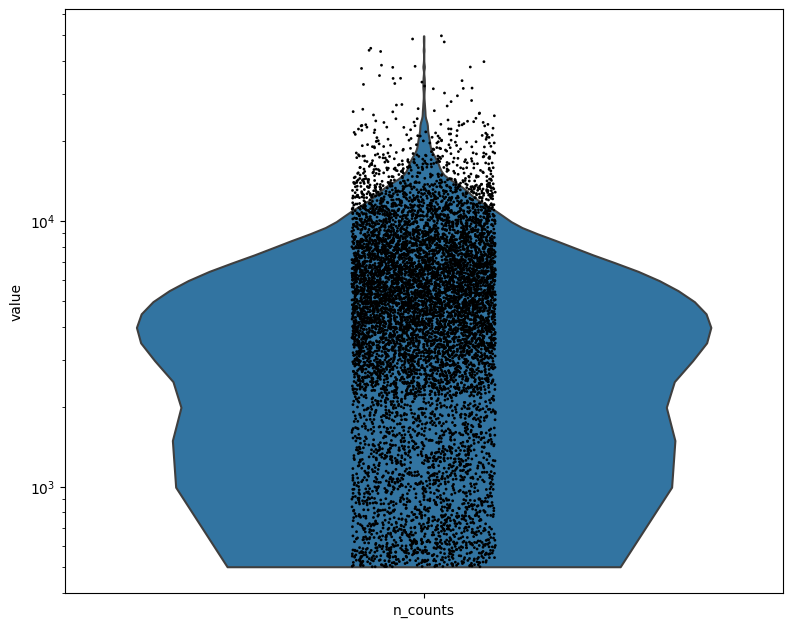

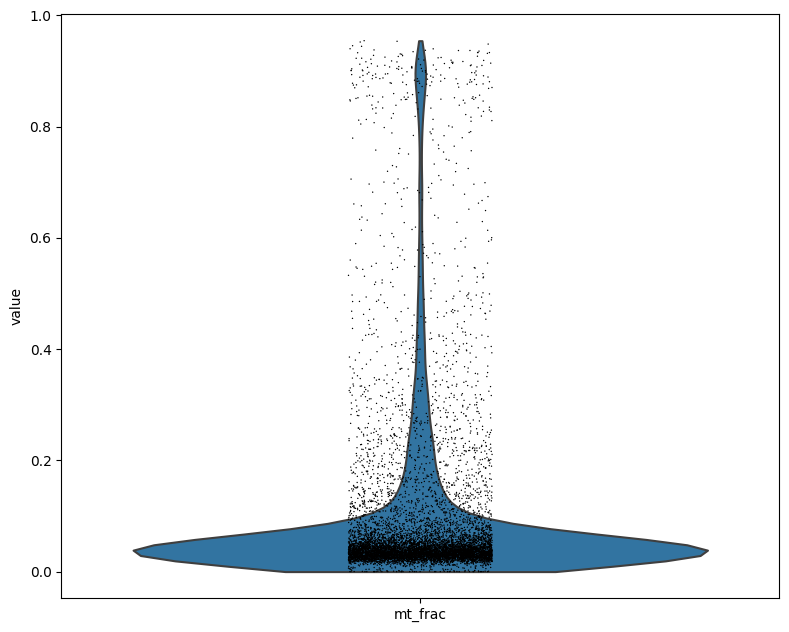

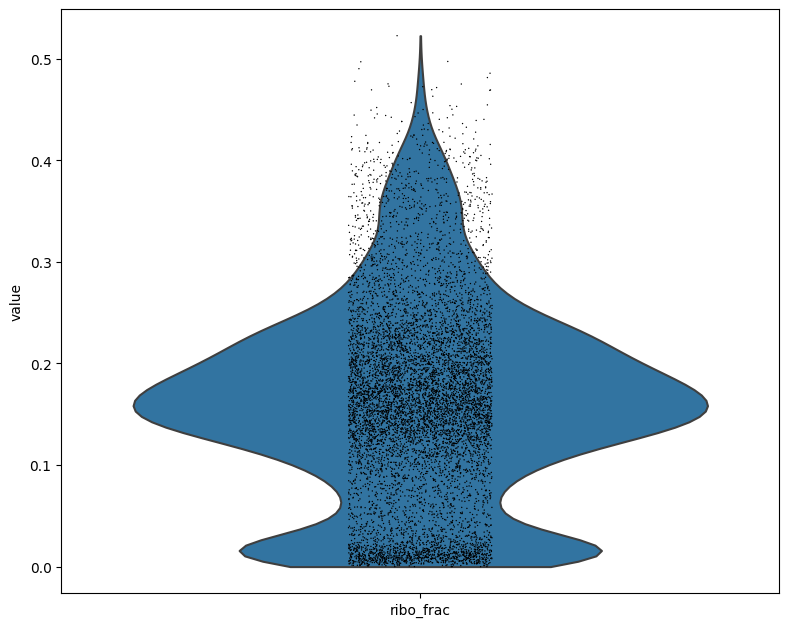

In [12]:
# Quality control - plot QC metrics
t1 = sc.pl.violin(adata_group[0], 'n_counts', size=2, log=True, cut=0)
t2 = sc.pl.violin(adata_group[0], 'mt_frac')
t3 = sc.pl.violin(adata_group[0], 'ribo_frac')

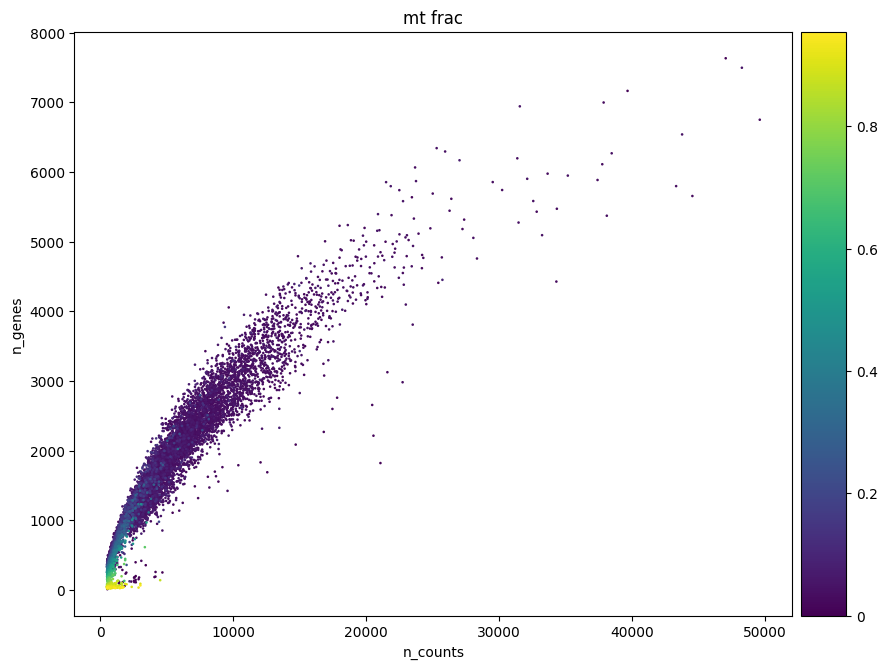

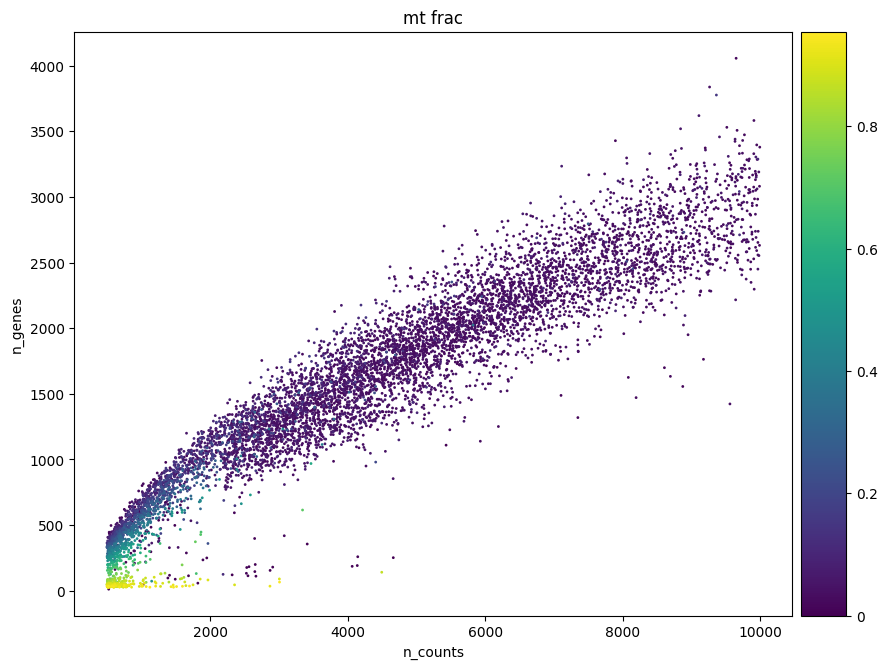

In [13]:
#Data quality summary plots
p1 = sc.pl.scatter(adata_group[0], 'n_counts', 'n_genes', color='mt_frac')
p2 = sc.pl.scatter(adata_group[0][adata_group[0].obs['n_counts']<10000], 'n_counts', 'n_genes', color='mt_frac')

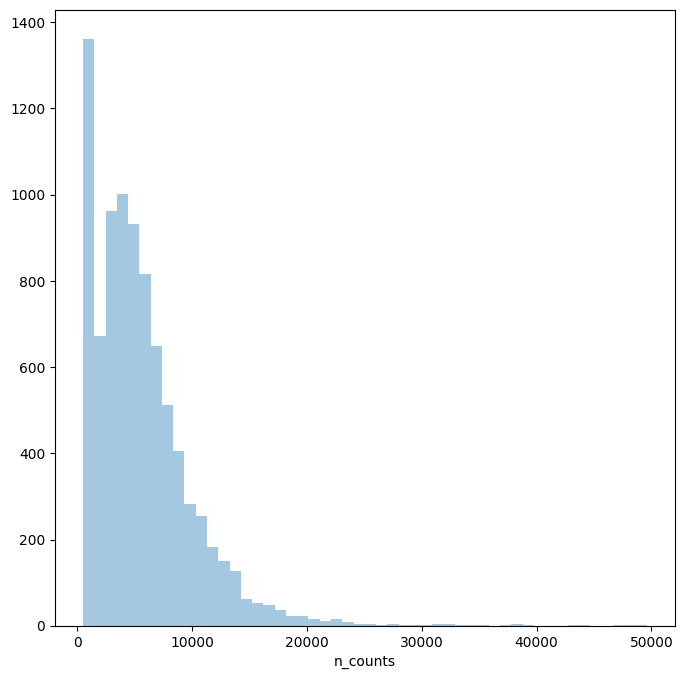

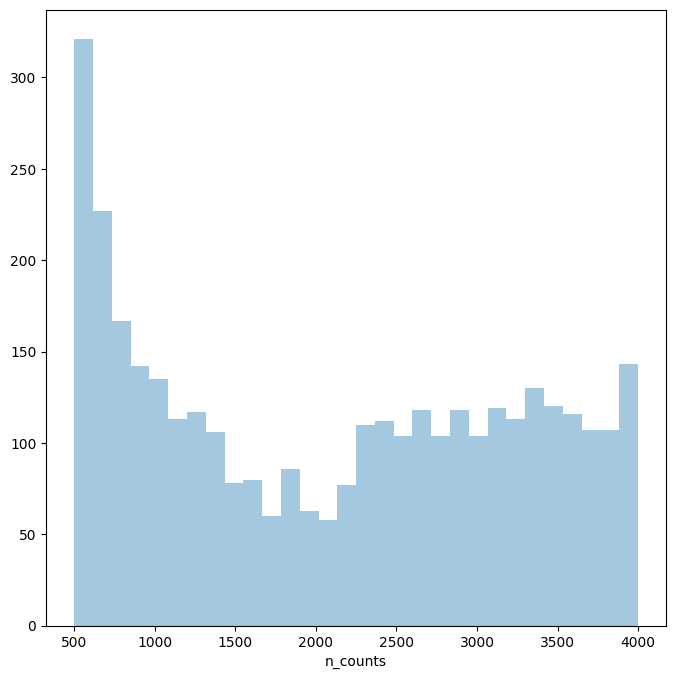

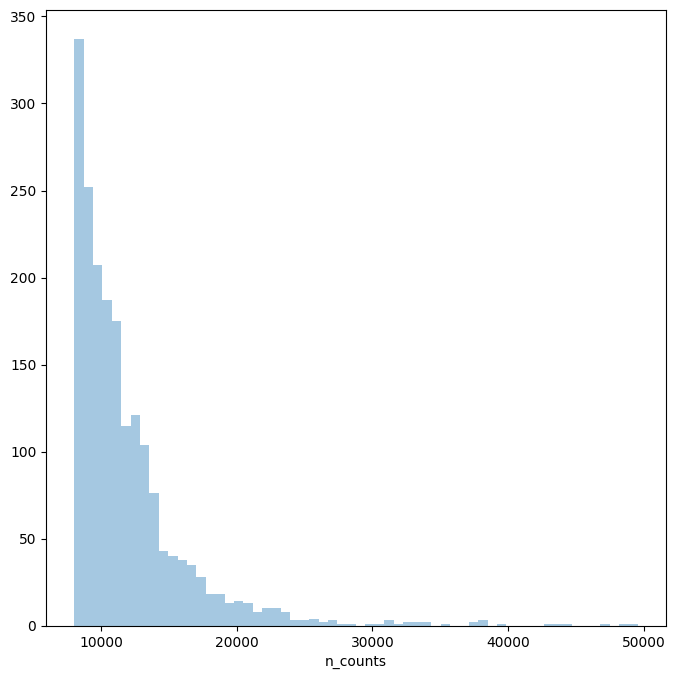

In [17]:
#Thresholding decision: counts
p3 = sns.distplot(adata_group[0].obs['n_counts'], kde=False)
plt.show()

p4 = sns.distplot(adata_group[0].obs['n_counts'][adata_group[0].obs['n_counts']<4000], kde=False, bins=30)
plt.show()

p5 = sns.distplot(adata_group[0].obs['n_counts'][adata_group[0].obs['n_counts']>8000], kde=False, bins=60)
plt.show()

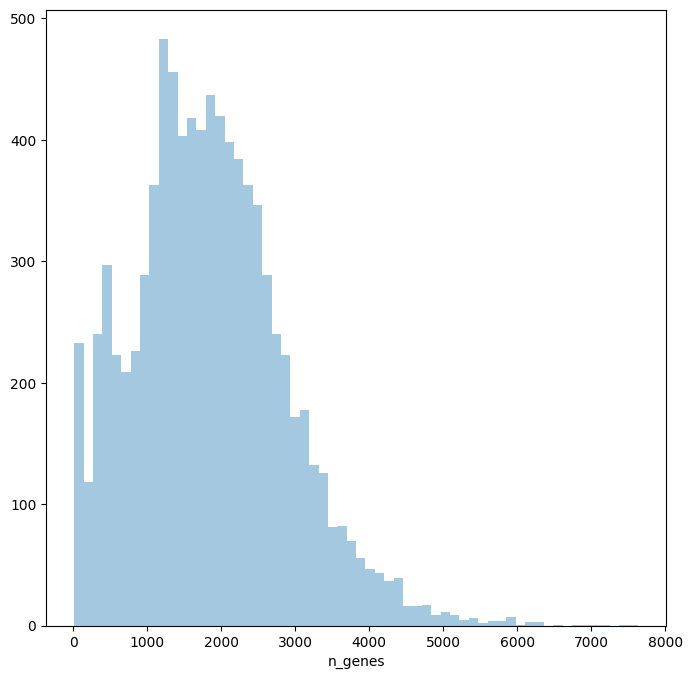

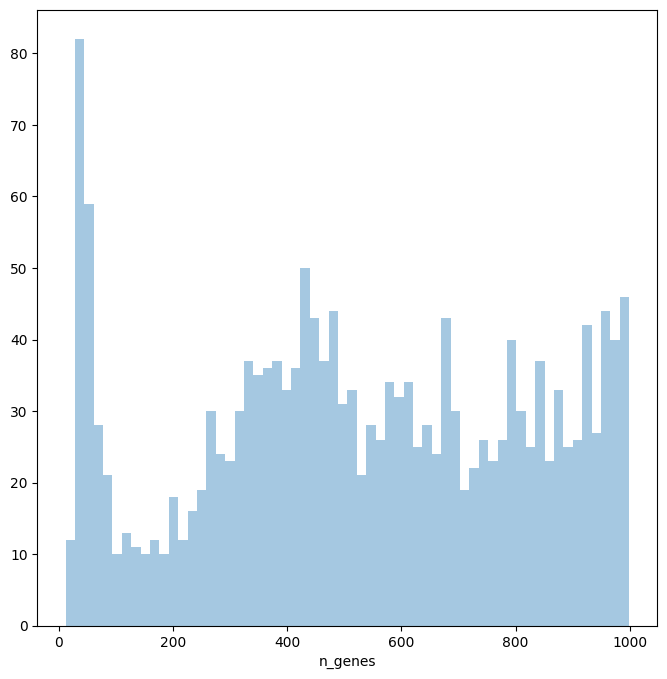

In [16]:
#Thresholding decision: genes
p6 = sns.distplot(adata_group[0].obs['n_genes'], kde=False, bins=60)
plt.show()

p7 = sns.distplot(adata_group[0].obs['n_genes'][adata_group[0].obs['n_genes']<1000], kde=False, bins=60)
plt.show()

In [18]:
# Filter cells according to identified QC thresholds:
print('Total number of cells: {:d}'.format(adata_group[0].n_obs))

sc.pp.filter_cells(adata_group[0], min_counts = 1000)
print('Number of cells after min count filter: {:d}'.format(adata_group[0].n_obs))


adata_group[0] = adata_group[0][adata_group[0].obs['mt_frac'] < 0.2]
print('Number of cells after MT filter: {:d}'.format(adata_group[0].n_obs))

sc.pp.filter_cells(adata_group[0], min_genes = 200)
print('Number of cells after gene filter: {:d}'.format(adata_group[0].n_obs))


Total number of cells: 8649
filtered out 892 cells that have less than 1000 counts
Number of cells after min count filter: 7757
Number of cells after MT filter: 7400
filtered out 18 cells that have less than 200 genes expressed
Number of cells after gene filter: 7382


In [19]:
import doubletdetection
clf = doubletdetection.BoostClassifier(n_components = 50, n_top_var_genes = 3000)
# raw_counts is a cells by genes count matrix
labels = clf.fit(adata_group[0].X.A).predict()
# higher means more likely to be doublet
scores = clf.doublet_score()

  0%|          | 0/10 [00:00<?, ?it/s]

computing PCA
Note that scikit-learn's randomized PCA might not be exactly reproducible across different computational platforms. For exact reproducibility, choose `svd_solver='arpack'.`
    with n_comps=50
    finished (0:00:00)
computing PCA
Note that scikit-learn's randomized PCA might not be exactly reproducible across different computational platforms. For exact reproducibility, choose `svd_solver='arpack'.`
    with n_comps=50
    finished (0:00:00)
computing PCA
Note that scikit-learn's randomized PCA might not be exactly reproducible across different computational platforms. For exact reproducibility, choose `svd_solver='arpack'.`
    with n_comps=50
    finished (0:00:00)
computing PCA
Note that scikit-learn's randomized PCA might not be exactly reproducible across different computational platforms. For exact reproducibility, choose `svd_solver='arpack'.`
    with n_comps=50
    finished (0:00:00)
computing PCA
Note that scikit-learn's randomized PCA might not be exactly repro

In [20]:
print('Number of cells before DP filter: {:d}'.format(adata_group[0].n_obs))
adata_group[0] = adata_group[0][labels == 0]
print('Number of cells after DP filter: {:d}'.format(adata_group[0].n_obs))

Number of cells before DP filter: 7382
Number of cells after DP filter: 7081


### 4 QC

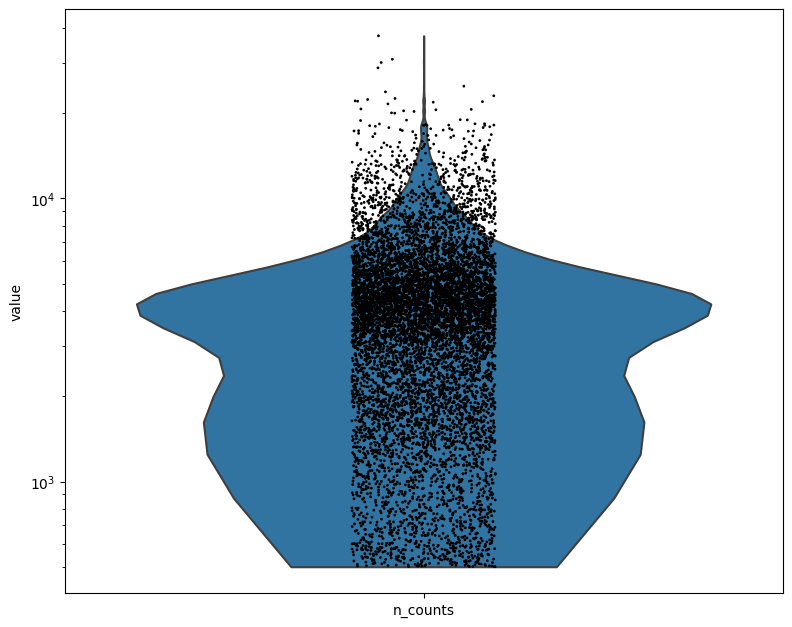

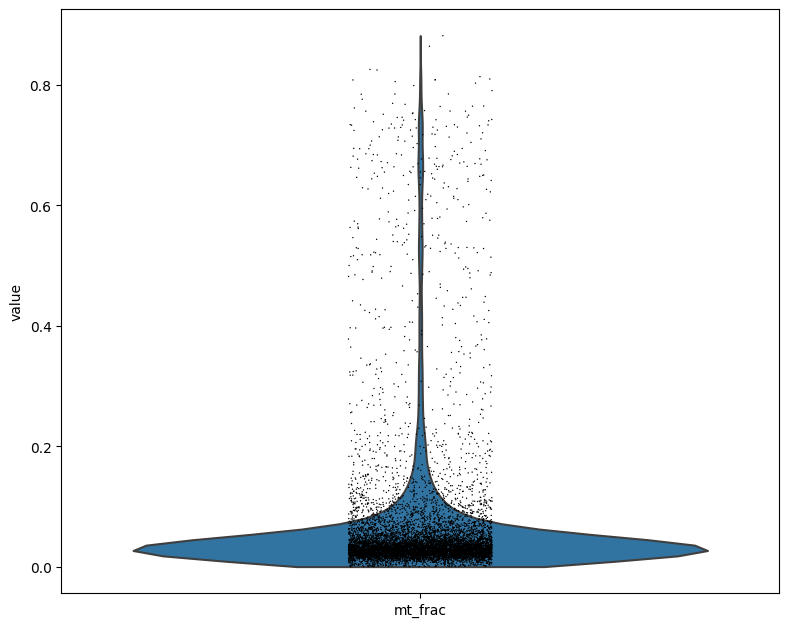

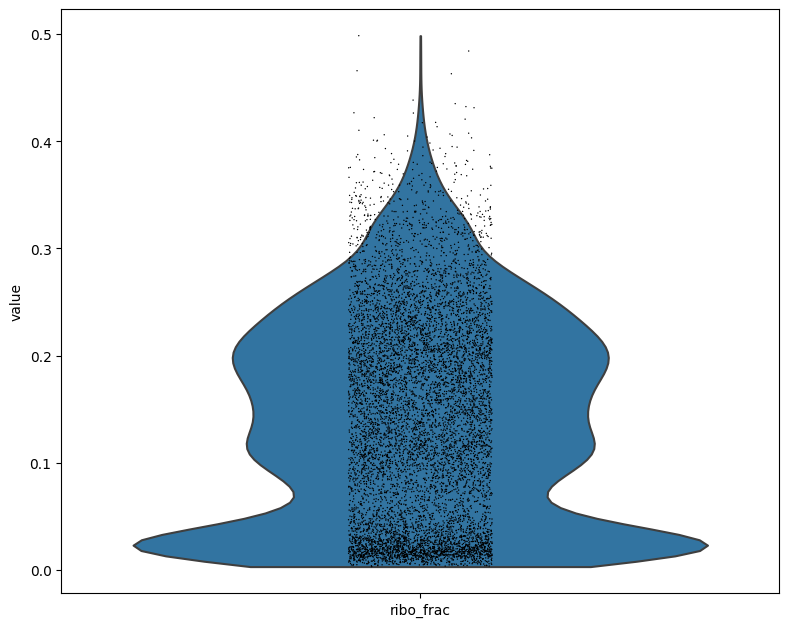

In [21]:
%matplotlib inline
t1 = sc.pl.violin(adata_group[1], 'n_counts', size=2, log=True, cut=0)
t2 = sc.pl.violin(adata_group[1], 'mt_frac')
t3 = sc.pl.violin(adata_group[1], 'ribo_frac')

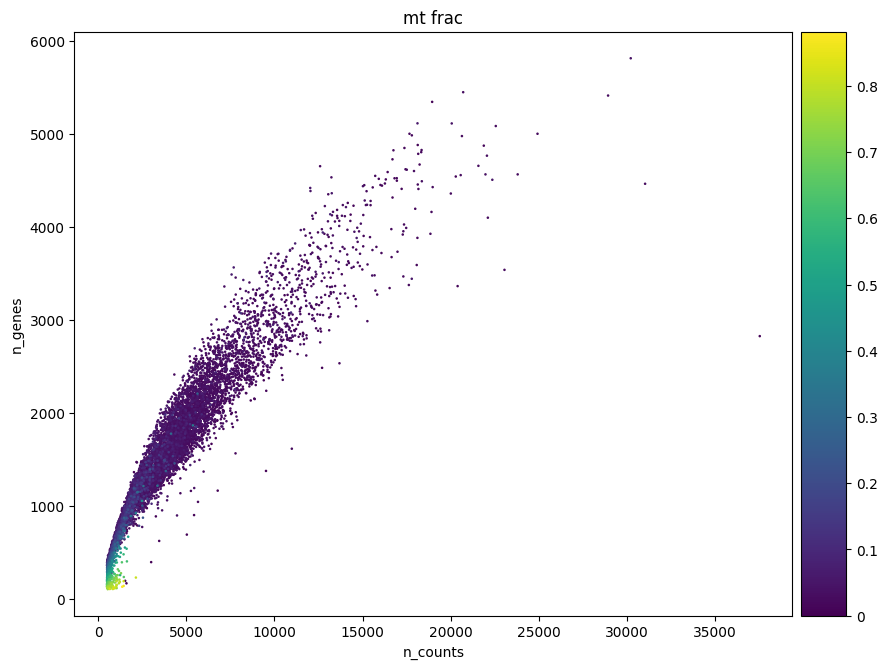

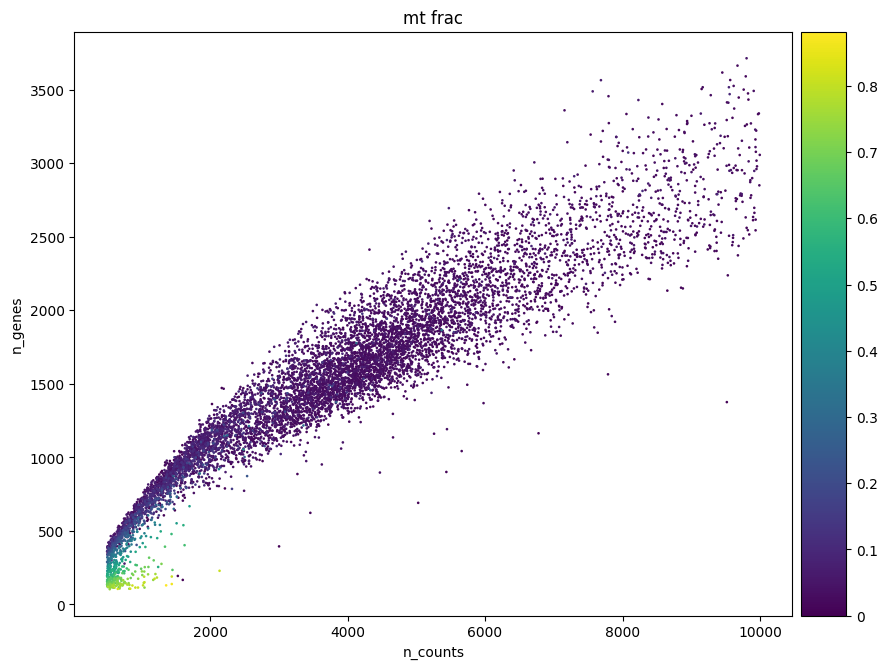

In [22]:
#Data quality summary plots
p1 = sc.pl.scatter(adata_group[1], 'n_counts', 'n_genes', color='mt_frac')
p2 = sc.pl.scatter(adata_group[1][adata_group[1].obs['n_counts']<10000], 'n_counts', 'n_genes', color='mt_frac')

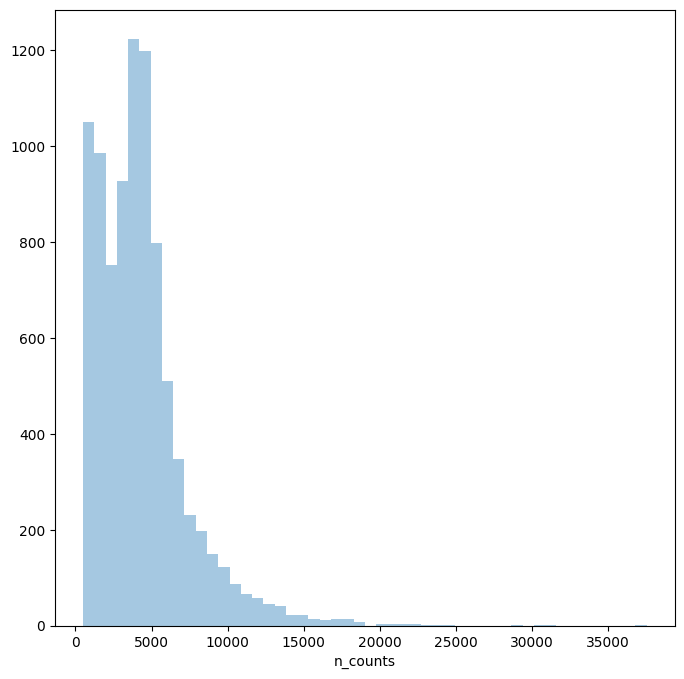

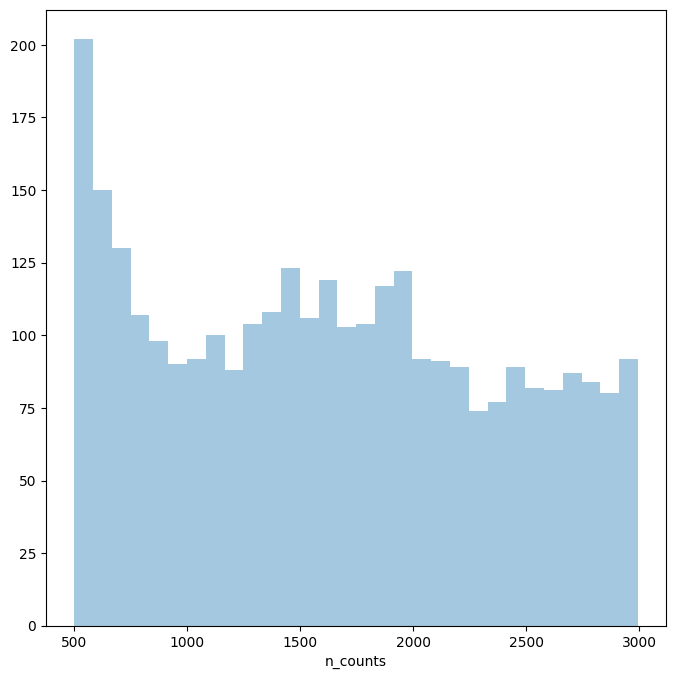

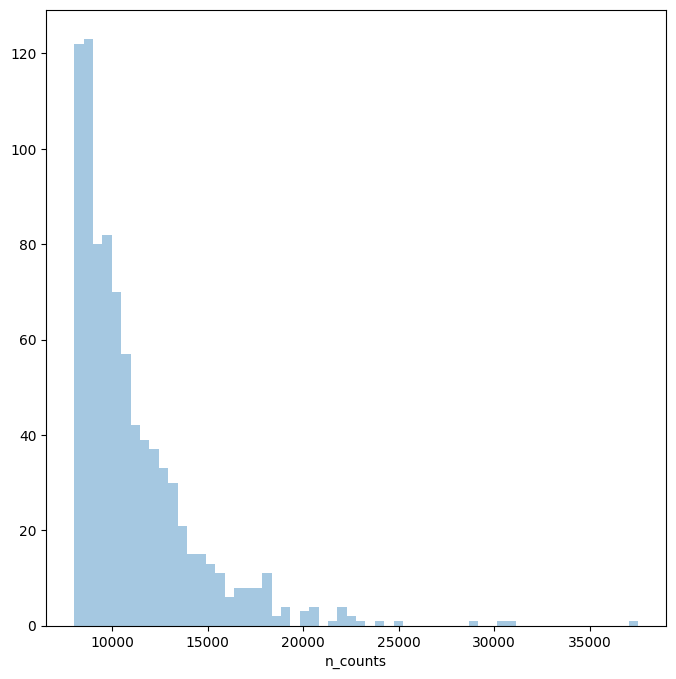

In [24]:
#Thresholding decision: counts
p3 = sns.distplot(adata_group[1].obs['n_counts'], kde=False)
plt.show()

p4 = sns.distplot(adata_group[1].obs['n_counts'][adata_group[1].obs['n_counts']<3000], kde=False, bins=30)
plt.show()

p5 = sns.distplot(adata_group[1].obs['n_counts'][adata_group[1].obs['n_counts']>8000], kde=False, bins=60)
plt.show()

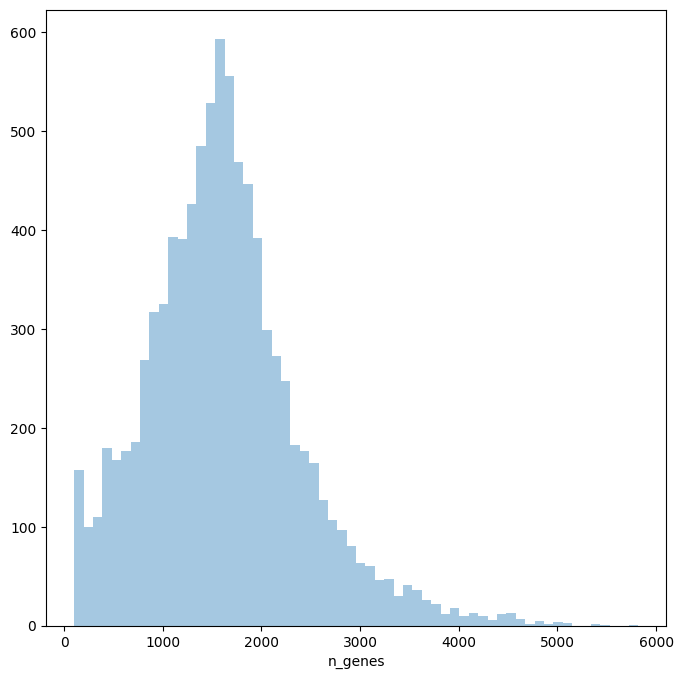

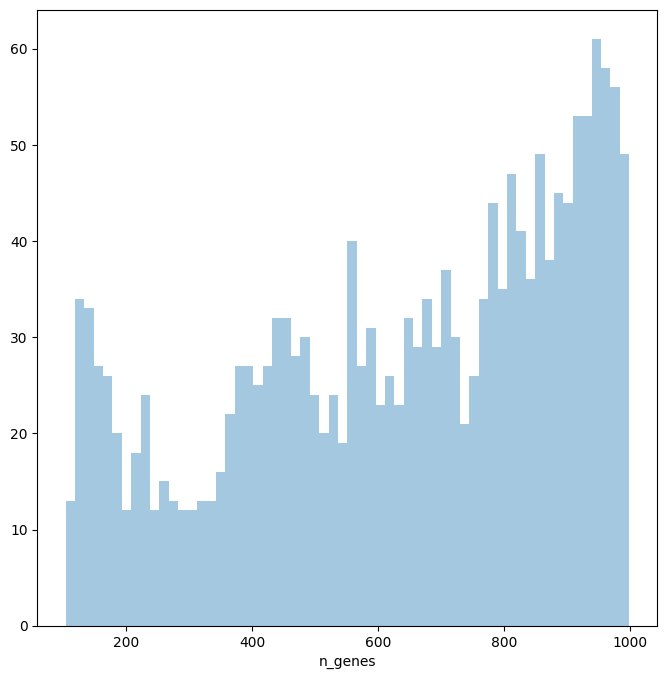

In [25]:
#Thresholding decision: genes
p6 = sns.distplot(adata_group[1].obs['n_genes'], kde=False, bins=60)
plt.show()

p7 = sns.distplot(adata_group[1].obs['n_genes'][adata_group[1].obs['n_genes']<1000], kde=False, bins=60)
plt.show()

In [26]:
# Filter cells according to identified QC thresholds:
print('Total number of cells: {:d}'.format(adata_group[1].n_obs))

sc.pp.filter_cells(adata_group[1], min_counts = 1600)
print('Number of cells after min count filter: {:d}'.format(adata_group[1].n_obs))

adata_group[1] = adata_group[1][adata_group[1].obs['mt_frac'] < 0.2]
print('Number of cells after MT filter: {:d}'.format(adata_group[1].n_obs))

sc.pp.filter_cells(adata_group[1], min_genes = 200)
print('Number of cells after gene filter: {:d}'.format(adata_group[1].n_obs))

Total number of cells: 8915
filtered out 1519 cells that have less than 1600 counts
Number of cells after min count filter: 7396
Number of cells after MT filter: 7365
filtered out 1 cells that have less than 200 genes expressed
Number of cells after gene filter: 7364


In [27]:
clf = doubletdetection.BoostClassifier(n_components = 50, n_top_var_genes = 3000)
# raw_counts is a cells by genes count matrix
labels = clf.fit(adata_group[1].X.A).predict()
# higher means more likely to be doublet
scores = clf.doublet_score()

  0%|          | 0/10 [00:00<?, ?it/s]

computing PCA
Note that scikit-learn's randomized PCA might not be exactly reproducible across different computational platforms. For exact reproducibility, choose `svd_solver='arpack'.`
    with n_comps=50
    finished (0:00:00)
computing PCA
Note that scikit-learn's randomized PCA might not be exactly reproducible across different computational platforms. For exact reproducibility, choose `svd_solver='arpack'.`
    with n_comps=50
    finished (0:00:00)
computing PCA
Note that scikit-learn's randomized PCA might not be exactly reproducible across different computational platforms. For exact reproducibility, choose `svd_solver='arpack'.`
    with n_comps=50
    finished (0:00:00)
computing PCA
Note that scikit-learn's randomized PCA might not be exactly reproducible across different computational platforms. For exact reproducibility, choose `svd_solver='arpack'.`
    with n_comps=50
    finished (0:00:00)
computing PCA
Note that scikit-learn's randomized PCA might not be exactly repro

In [28]:
print('Number of cells before T filter: {:d}'.format(adata_group[1].n_obs))
adata_group[1] = adata_group[1][labels == 0]
print('Number of cells after T filter: {:d}'.format(adata_group[1].n_obs))

Number of cells before T filter: 7364
Number of cells after T filter: 6955


### 5 QC

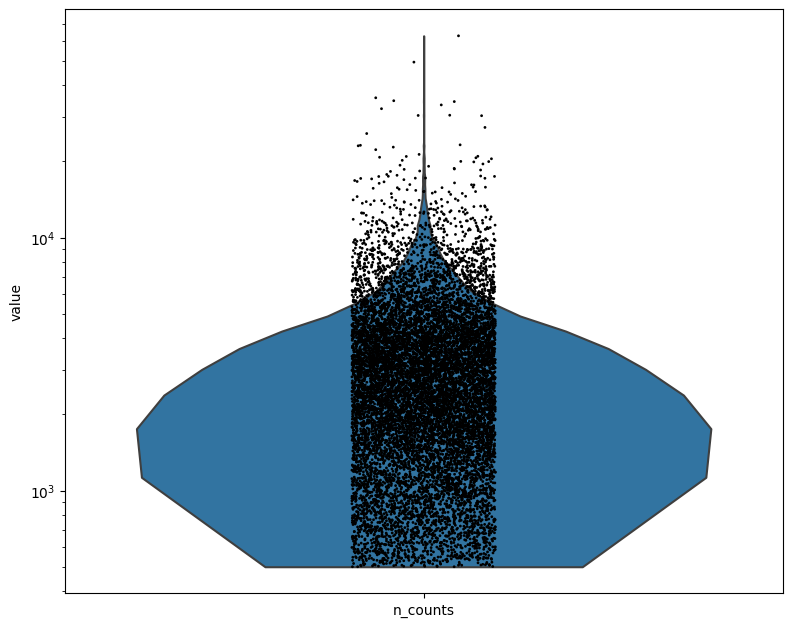

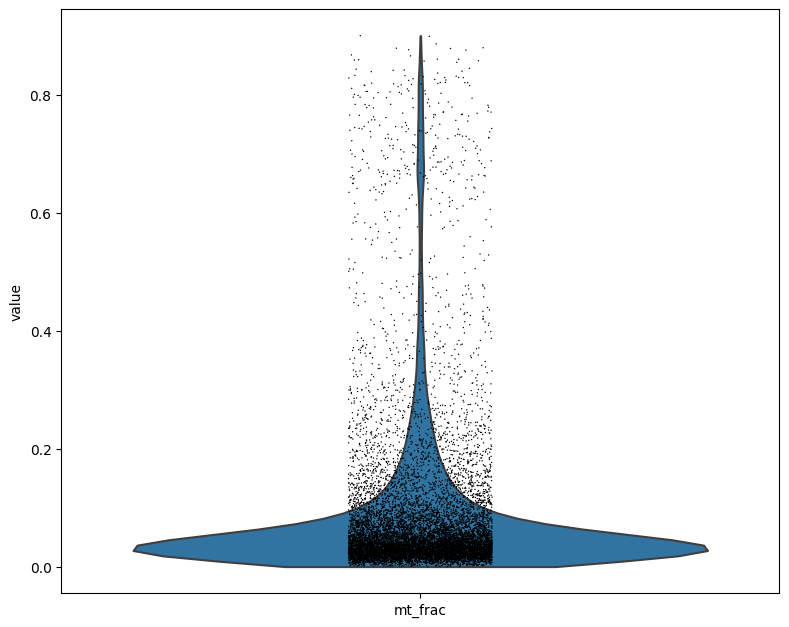

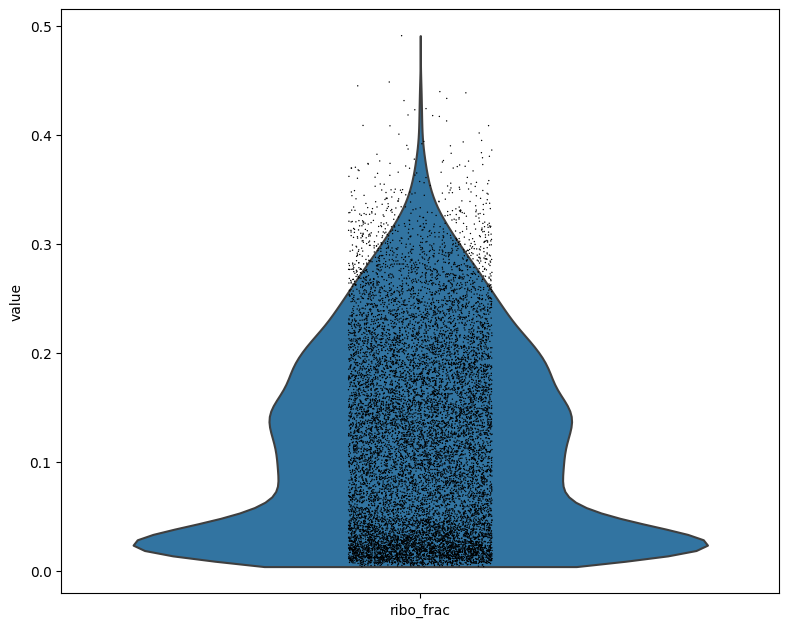

In [29]:
# Quality control - plot QC metrics
t1 = sc.pl.violin(adata_group[2], 'n_counts', size=2, log=True, cut=0)
t2 = sc.pl.violin(adata_group[2], 'mt_frac')
t3 = sc.pl.violin(adata_group[2], 'ribo_frac')


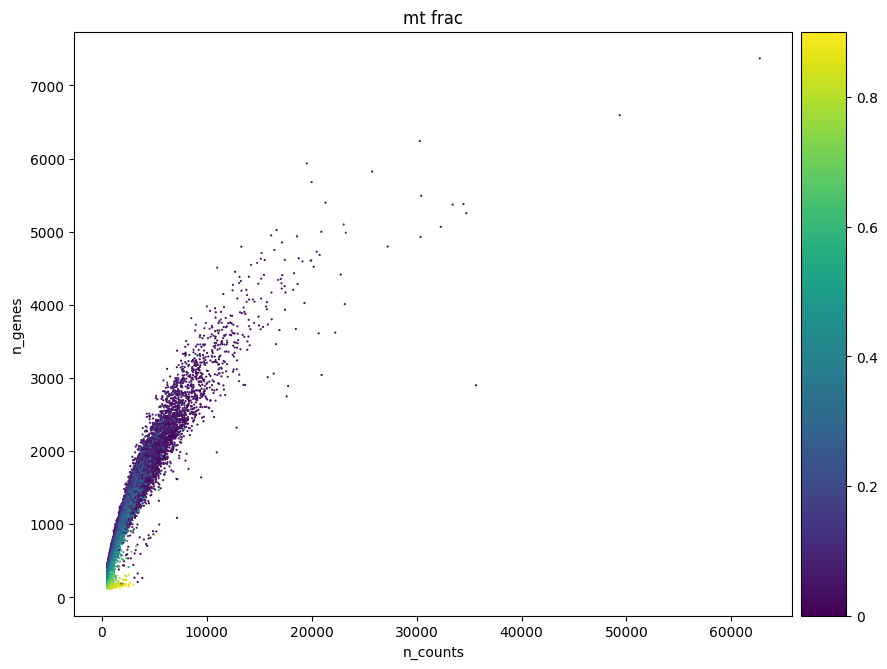

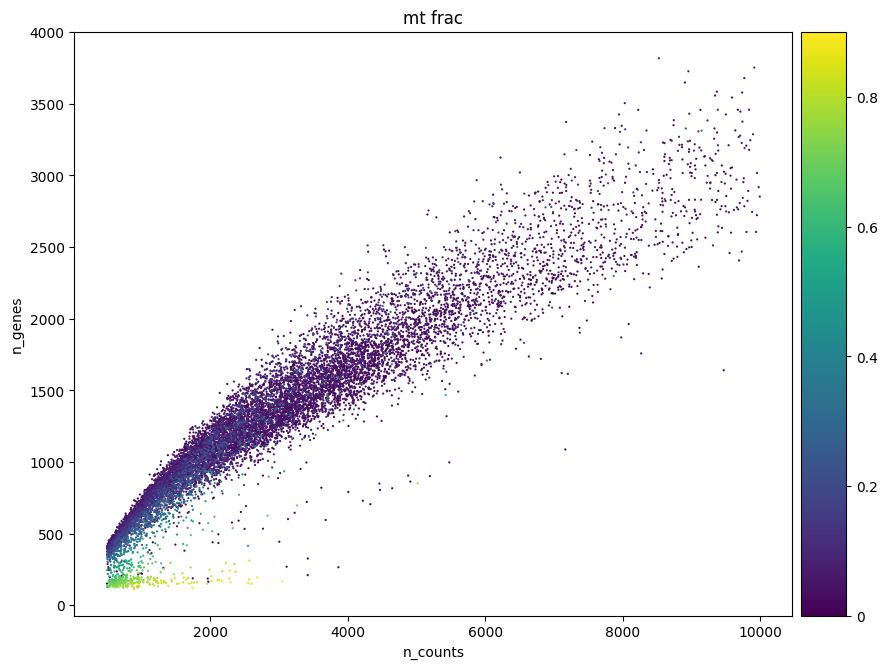

In [30]:
#Data quality summary plots
p1 = sc.pl.scatter(adata_group[2], 'n_counts', 'n_genes', color='mt_frac')
p2 = sc.pl.scatter(adata_group[2][adata_group[2].obs['n_counts']<10000], 'n_counts', 'n_genes', color='mt_frac')

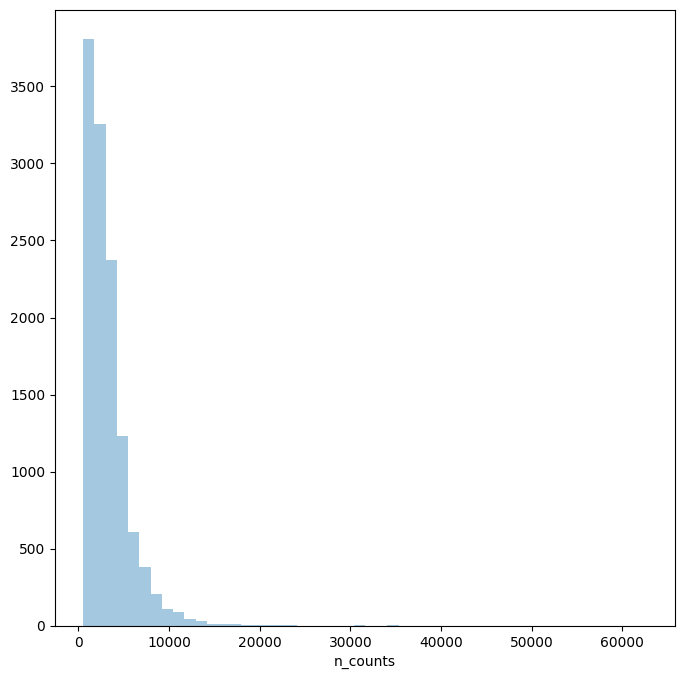

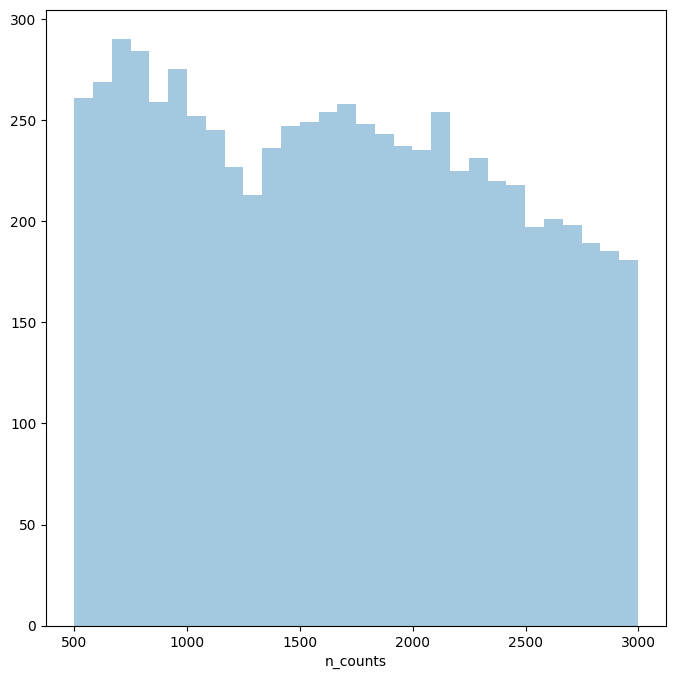

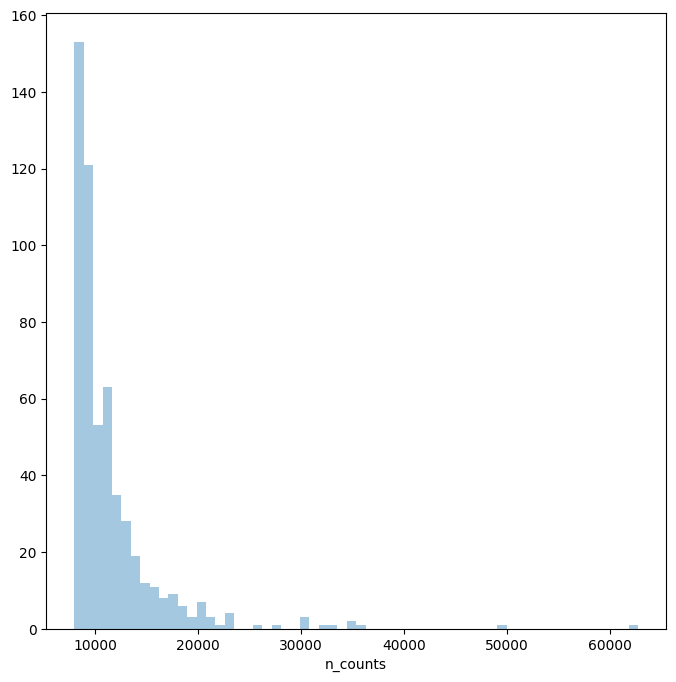

In [31]:
#Thresholding decision: counts
p3 = sns.distplot(adata_group[2].obs['n_counts'], kde=False)
plt.show()

p4 = sns.distplot(adata_group[2].obs['n_counts'][adata_group[2].obs['n_counts']<3000], kde=False, bins=30)
plt.show()

p5 = sns.distplot(adata_group[2].obs['n_counts'][adata_group[2].obs['n_counts']>8000], kde=False, bins=60)
plt.show()

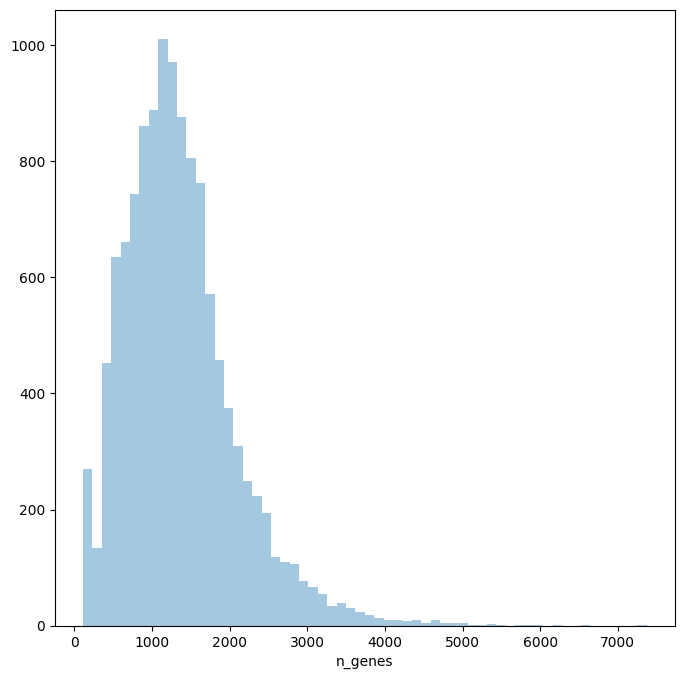

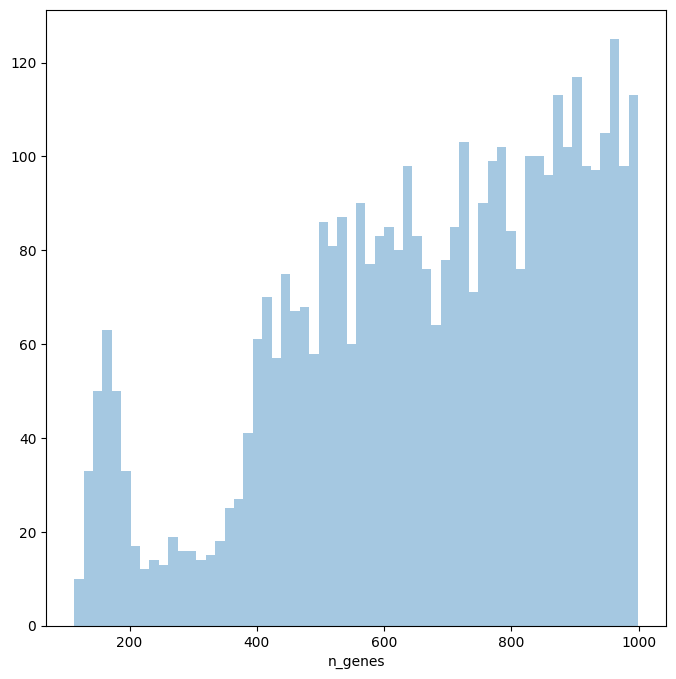

In [32]:
#Thresholding decision: genes
p6 = sns.distplot(adata_group[2].obs['n_genes'], kde=False, bins=60)
plt.show()

p7 = sns.distplot(adata_group[2].obs['n_genes'][adata_group[2].obs['n_genes']<1000], kde=False, bins=60)
plt.show()

In [33]:
# Filter cells according to identified QC thresholds:
print('Total number of cells: {:d}'.format(adata_group[2].n_obs))

sc.pp.filter_cells(adata_group[2], min_counts = 1200)
print('Number of cells after min count filter: {:d}'.format(adata_group[2].n_obs))


adata_group[2] = adata_group[2][adata_group[2].obs['mt_frac'] < 0.2]
print('Number of cells after MT filter: {:d}'.format(adata_group[2].n_obs))

sc.pp.filter_cells(adata_group[2], min_genes = 200)
print('Number of cells after gene filter: {:d}'.format(adata_group[2].n_obs))


Total number of cells: 12211
filtered out 2212 cells that have less than 1200 counts
Number of cells after min count filter: 9999
Number of cells after MT filter: 9455
filtered out 3 cells that have less than 200 genes expressed
Number of cells after gene filter: 9452


In [34]:
clf = doubletdetection.BoostClassifier(n_components = 50, n_top_var_genes = 3000)
# raw_counts is a cells by genes count matrix
labels = clf.fit(adata_group[2].X.A).predict()
# higher means more likely to be doublet
scores = clf.doublet_score()

  0%|          | 0/10 [00:00<?, ?it/s]

computing PCA
Note that scikit-learn's randomized PCA might not be exactly reproducible across different computational platforms. For exact reproducibility, choose `svd_solver='arpack'.`
    with n_comps=50
    finished (0:00:00)
computing PCA
Note that scikit-learn's randomized PCA might not be exactly reproducible across different computational platforms. For exact reproducibility, choose `svd_solver='arpack'.`
    with n_comps=50
    finished (0:00:00)
computing PCA
Note that scikit-learn's randomized PCA might not be exactly reproducible across different computational platforms. For exact reproducibility, choose `svd_solver='arpack'.`
    with n_comps=50
    finished (0:00:00)
computing PCA
Note that scikit-learn's randomized PCA might not be exactly reproducible across different computational platforms. For exact reproducibility, choose `svd_solver='arpack'.`
    with n_comps=50
    finished (0:00:00)
computing PCA
Note that scikit-learn's randomized PCA might not be exactly repro

In [35]:
print('Number of cells before T filter: {:d}'.format(adata_group[2].n_obs))
adata_group[2] = adata_group[2][labels == 0]
print('Number of cells after T filter: {:d}'.format(adata_group[2].n_obs))

Number of cells before T filter: 9452
Number of cells after T filter: 8910


### concat

In [36]:
adata_concat = adata_group[0].concatenate(adata_group[1],adata_group[2], batch_categories=['3', '4','5'])

In [37]:
sc.pp.filter_genes(adata_concat, min_cells = 2)

filtered out 8318 genes that are detected in less than 2 cells


In [38]:
adata_concat.layers['raw_filtered'] = adata_concat.X

In [39]:
adata_concat.obs['n_counts'] = adata_concat.X.sum(1)
adata_concat.obs['log_counts'] = np.log(adata_concat.obs['n_counts'])
adata_concat.obs['n_genes'] = (adata_concat.X > 0).sum(1)
adata_concat.obs['log10GenesPerUMI'] = np.log10(adata_concat.obs['n_genes'])/np.log10(adata_concat.obs['n_counts'])

mt_gene_mask = [gene.startswith('MT-') for gene in adata_concat.var_names]
adata_concat.obs['mt_frac'] = np.array(adata_concat.X[:, mt_gene_mask].sum(1).ravel())[0]/adata_concat.obs['n_counts']
ribo_gene_mask = [gene.startswith('RPL') or gene.startswith('RPS') for gene in adata_concat.var_names]
adata_concat.obs['ribo_frac'] = np.array(adata_concat.X[:, ribo_gene_mask].sum(1).ravel())[0]/adata_concat.obs['n_counts']

In [40]:
adata_forcycle = adata_concat.copy()
sc.pp.normalize_total(adata_forcycle, key_added = 'normalization_factors')
sc.pp.log1p(adata_forcycle)

normalizing counts per cell
    finished (0:00:00)


### Find HVG and proceed to dimesion reduction PCA + UMAP

In [41]:
sc.pp.highly_variable_genes(adata_forcycle, flavor='seurat', n_top_genes=2000)
print('\n','Number of highly variable genes: {:d}'.format(np.sum(adata_forcycle.var['highly_variable'])))

If you pass `n_top_genes`, all cutoffs are ignored.
extracting highly variable genes
    finished (0:00:01)
--> added
    'highly_variable', boolean vector (adata.var)
    'means', float vector (adata.var)
    'dispersions', float vector (adata.var)
    'dispersions_norm', float vector (adata.var)

 Number of highly variable genes: 2000


In [42]:
sc.pp.pca(adata_forcycle, n_comps=50, use_highly_variable=True, svd_solver='arpack')
sc.pp.neighbors(adata_forcycle, n_neighbors = 15, n_pcs = 50)

computing PCA
    on highly variable genes
    with n_comps=50
    finished (0:00:00)
computing neighbors
    using 'X_pca' with n_pcs = 50
    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:00:27)


In [43]:
sc.tl.umap(adata_forcycle, min_dist = 0.2, spread = 1)

computing UMAP
    finished: added
    'X_umap', UMAP coordinates (adata.obsm) (0:00:14)


### Use the cell cycle gene list summarized by Triosh et al. to calculate the cc score

In [47]:
cc_genes = pd.read_excel('F:/Tcell_tissues/Triosh_cc.xlsx')

In [48]:
s_genes = cc_genes['G1/S'].dropna()
g2m_genes = cc_genes['G2/M'].dropna()

s_genes_mm_ens = adata_forcycle.var_names[np.in1d(adata_forcycle.var_names, s_genes)]
g2m_genes_mm_ens = adata_forcycle.var_names[np.in1d(adata_forcycle.var_names, g2m_genes)]

In [49]:
sc.tl.score_genes_cell_cycle(adata_forcycle, s_genes=s_genes_mm_ens, g2m_genes=g2m_genes_mm_ens)

calculating cell cycle phase
computing score 'S_score'
    finished: added
    'S_score', score of gene set (adata.obs).
    504 total control genes are used. (0:00:00)
computing score 'G2M_score'
    finished: added
    'G2M_score', score of gene set (adata.obs).
    503 total control genes are used. (0:00:00)
-->     'phase', cell cycle phase (adata.obs)


### Visualize the cell phases of the co-cultured cells

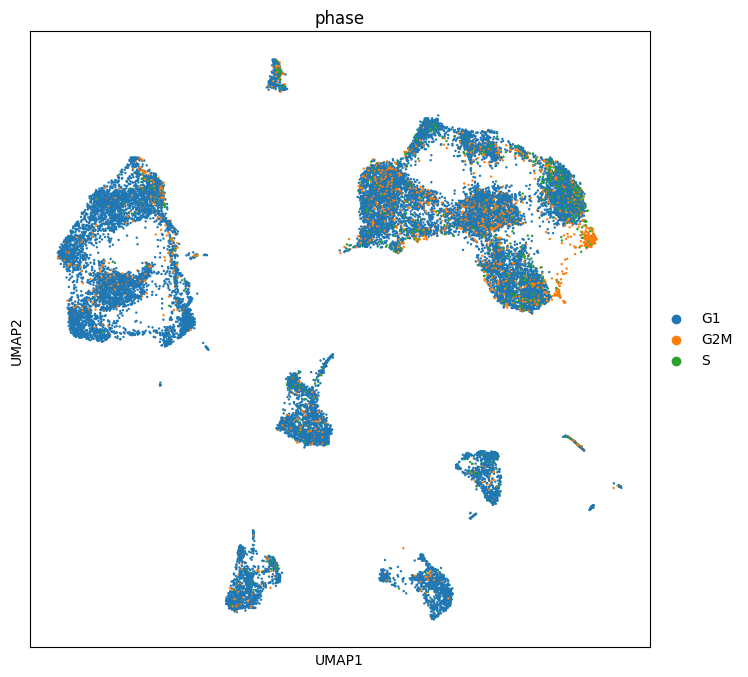

In [50]:
sc.pl.umap(adata_forcycle, color='phase',size = 12)

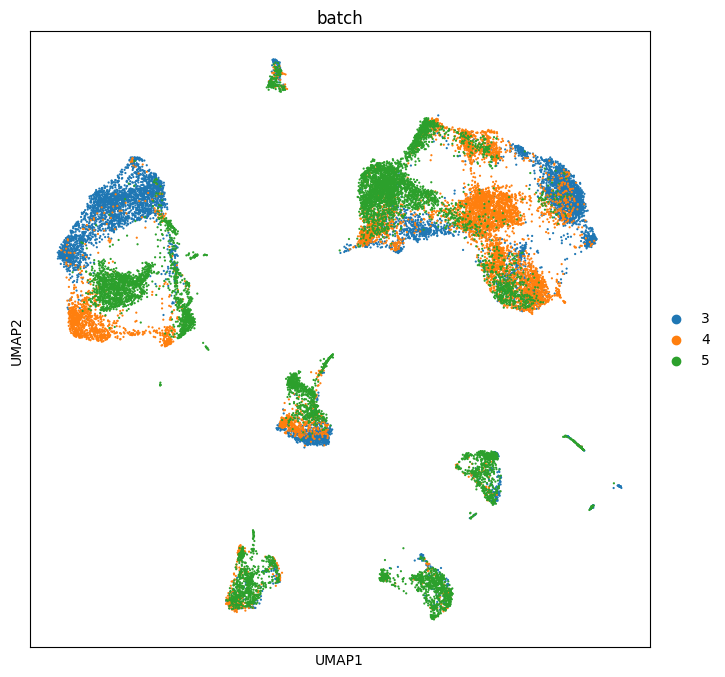

In [51]:
sc.pl.umap(adata_forcycle, color='batch',size = 10)

### Export the result to input it into the Seurat

In [53]:
Sscore = adata_forcycle.obs['S_score'].values.tolist()
G2Mscore = adata_forcycle.obs['G2M_score'].values.tolist()
S_G2M_diff = adata_forcycle.obs['S_score'] - adata_forcycle.obs['G2M_score']
S_G2M_diff = S_G2M_diff.values.tolist()

In [54]:
adata_concat.uns['allgenes'] = list(adata_concat.var_names)
adata_concat.obs['S_score'] = adata_forcycle.obs['S_score']
adata_concat.obs['G2M_score'] = adata_forcycle.obs['G2M_score']
adata_concat.obs['S_G2M_diff'] = adata_concat.obs['S_score'] - adata_concat.obs['G2M_score']
adata_concat.obs['phase'] = adata_forcycle.obs['phase']

In [55]:
colnames = adata_concat.obs_names
rownames = adata_concat.var_names
mt_frac = adata_concat.obs['mt_frac']
batch = adata_concat.obs['batch']
counts = adata_concat.X.T

In [56]:
%%R -i counts -i colnames -i rownames -i S_G2M_diff -i mt_frac -i Sscore -i G2Mscore -i batch
colnames(counts) = colnames
rownames(counts) = rownames

srat <- CreateSeuratObject(counts = counts, project = "gut", min.cells = 0, min.features = 0, assay = "RNA")

srat[["S_G2M_diff"]] = S_G2M_diff
srat[["mt_frac"]] = mt_frac
srat[["Sscore"]] = Sscore
srat[["G2Mscore"]] = G2Mscore
srat[["batch"]] = batch

In [ ]:
%%R
cond.list = SplitObject(srat, split.by = "batch")
d3 <- cond.list[["3"]]
d4 <- cond.list[["4"]]
d5 <- cond.list[["5"]]

d3 = SCTransform(object = d3, verbose = FALSE, vst.flavor = "v2", vars.to.regress = c("G2Mscore","Sscore","mt_frac"),min_cells=0) #c("G2Mscore","Sscore"))

d3 = RunPCA(d3, verbose = FALSE)

d4 = SCTransform(object = d4, verbose = FALSE, vst.flavor = "v2", vars.to.regress = c("G2Mscore","Sscore","mt_frac"),min_cells=0) #c("G2Mscore","Sscore"))

d4 = RunPCA(d4, verbose = FALSE)

d5 = SCTransform(object = d5, verbose = FALSE, vst.flavor = "v2", vars.to.regress = c("G2Mscore","Sscore","mt_frac"),min_cells=0) #c("G2Mscore","Sscore"))

d5 = RunPCA(d5, verbose = FALSE)

In [59]:
%%R
ifnb.list <- list(d3 = d3, d4 = d4, d5 = d5)
features <- SelectIntegrationFeatures(object.list = ifnb.list, nfeatures = 3000)
ifnb.list <- PrepSCTIntegration(object.list = ifnb.list, anchor.features = features)

mod.anchors <- FindIntegrationAnchors(object.list = ifnb.list, normalization.method = "SCT",
    anchor.features = features)
srat_combined <- IntegrateData(anchorset = mod.anchors, normalization.method = "SCT")

  |                                                  | 0 % ~calculating   |+++++++++++++++++                                 | 33% ~05s           |++++++++++++++++++++++++++++++++++                | 67% ~03s           |++++++++++++++++++++++++++++++++++++++++++++++++++| 100% elapsed=08s  
  |                                                  | 0 % ~calculating   |+++++++++++++++++                                 | 33% ~07m 03s       |++++++++++++++++++++++++++++++++++                | 67% ~03m 53s       |++++++++++++++++++++++++++++++++++++++++++++++++++| 100% elapsed=11m 57s
[1] 1
[1] 2
[1] 3


In [60]:
%%R -o HVG -o varExplained -o PCs -o mat -o left_genes

srat_combined = RunPCA(srat_combined,verbose = FALSE)

HVG = VariableFeatures(srat_combined)

mat <- Seurat::GetAssayData(object = srat_combined, slot = 'scale.data')
pca <- srat_combined[["pca"]]

# Get the total variance:
total_variance <- sum(matrixStats::rowVars(mat))

eigValues = (pca@stdev)^2  ## EigenValues
varExplained = eigValues / total_variance

PCs = Loadings(srat_combined, reduction = "pca")
left_genes = rownames(x = srat_combined[["SCT"]])

saveRDS(srat_combined,'F:/Tcell_tissues/srat_combined_liv.rds')

In [61]:
%%R -o X_pca
X_pca = pca@cell.embeddings

In [62]:
%%R -o counts -o logcounts -o residuals

counts = srat_combined[["SCT"]]@counts
logcounts = srat_combined[["SCT"]]@data
residuals = srat_combined[["SCT"]]@scale.data

In [63]:
%R -o srat_combined -o features

In [202]:
import anndata
adata = anndata.AnnData(X = logcounts.T)
adata.var_names = left_genes
adata.obs_names = adata_concat.obs_names
adata.obs = adata_concat.obs
adata.uns['scaled'] = mat.T
adata.layers['counts'] = counts.T
adata.uns['residuals'] = residuals.T
adata.layers['logcounts'] = logcounts.T
adata.layers['raw'] = adata_concat.layers['raw_filtered']
adata.obsm['X_pca'] = X_pca
adata.uns['HVG'] = list(HVG)

In [203]:
adata.obs['n_counts'] = adata.layers['counts'].sum(1)
adata.obs['n_genes'] = (adata.layers['counts'] > 0).sum(1)
adata.var['highly_variable'] = adata.var_names.isin((HVG))
adata.obs['phase'] = adata_concat.obs['phase']
adata.uns['pca'] = dict({'variance_ratio': varExplained})

In [204]:
mt_gene_mask = [gene.startswith('MT-') for gene in adata.var_names]
adata.obs['mt_frac'] = np.array(adata.layers['counts'][:, mt_gene_mask].sum(1).ravel())[0]/adata.obs['n_counts']

In [205]:
ribo_gene_mask = [gene.startswith('RPL') or gene.startswith('RPS') for gene in adata.var_names]
adata.obs['ribo_frac'] = np.array(adata.layers['counts'][:, ribo_gene_mask].sum(1).ravel())[0]/adata.obs['n_counts']

In [206]:
sc.pp.neighbors(adata, n_pcs = 50)

computing neighbors
    using 'X_pca' with n_pcs = 50
    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:00:05)


running Leiden clustering
    finished: found 16 clusters and added
    'leiden', the cluster labels (adata.obs, categorical) (0:00:02)


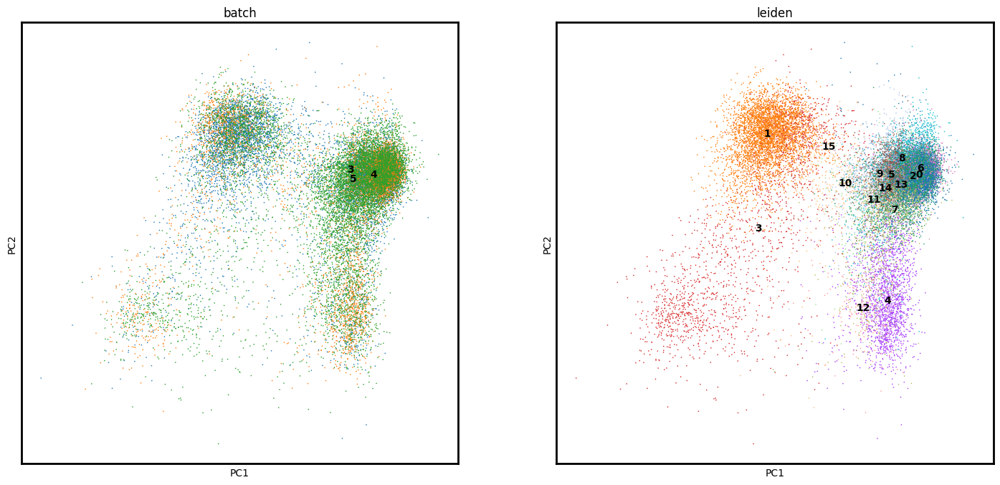

In [207]:
sc.tl.leiden(adata, resolution = 0.3, key_added= 'leiden')
sc.pl.pca(adata, color=['batch','leiden'], legend_loc = 'on data')

running PAGA
    finished: added
    'paga/connectivities', connectivities adjacency (adata.uns)
    'paga/connectivities_tree', connectivities subtree (adata.uns) (0:00:00)
--> added 'pos', the PAGA positions (adata.uns['paga'])


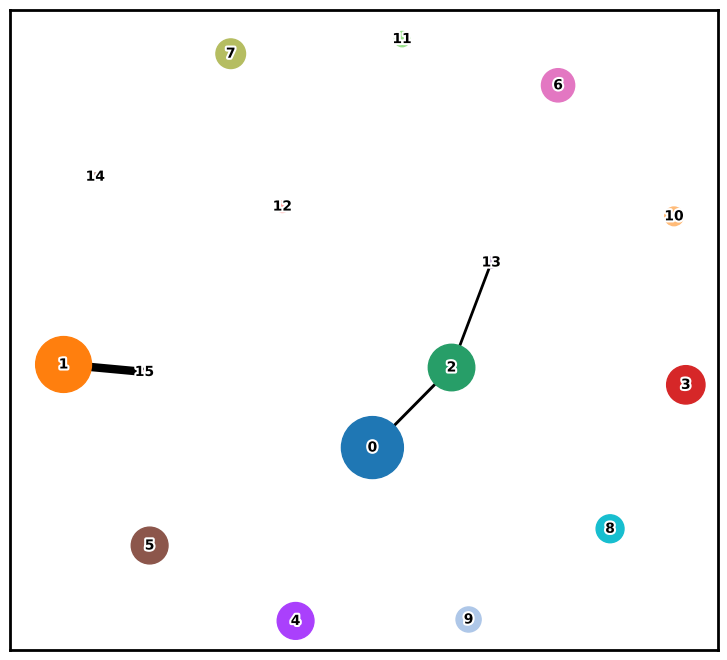

In [208]:
sc.tl.paga(adata, groups='leiden')
sc.pl.paga(adata,threshold = 0.2, labels=None, fontsize = 10, fontoutline = 3,node_size_scale = 3,node_size_power = 1,random_state = 0)

In [209]:
%matplotlib inline
sc.tl.umap(adata, min_dist = 0.001, spread = 1.5,init_pos = 'paga')

computing UMAP
    finished: added
    'X_umap', UMAP coordinates (adata.obsm) (0:00:14)


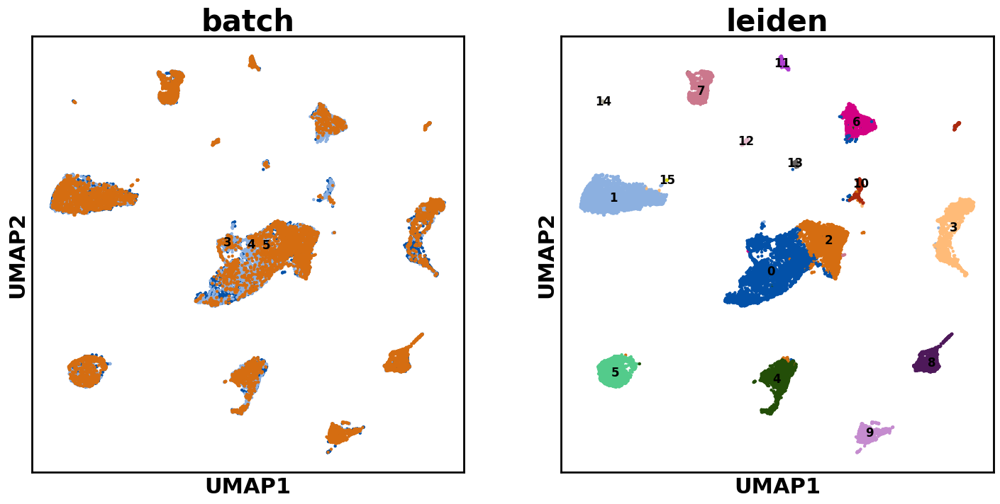

In [210]:
#plt.close()
plt.rcParams['axes.linewidth'] = 2
fig = sc.pl.umap(adata, color = ['batch','leiden'],
                 size = 40, legend_loc = 'on data', palette  = my_palette, ncols = 4, cmap = my_cmap, return_fig = True, legend_fontsize = 'large')
ax = fig.get_axes()
for i in range(0,len(ax)):
    ax[i].xaxis.label.set_fontsize(22)
    ax[i].xaxis.label.set_fontweight('bold')
    ax[i].yaxis.label.set_fontsize(22)
    ax[i].title.set_fontsize(30)
    ax[i].yaxis.label.set_fontweight('bold')
    ax[i].title.set_fontweight('bold')
#plt.savefig('overall_map_withunmatched.png')

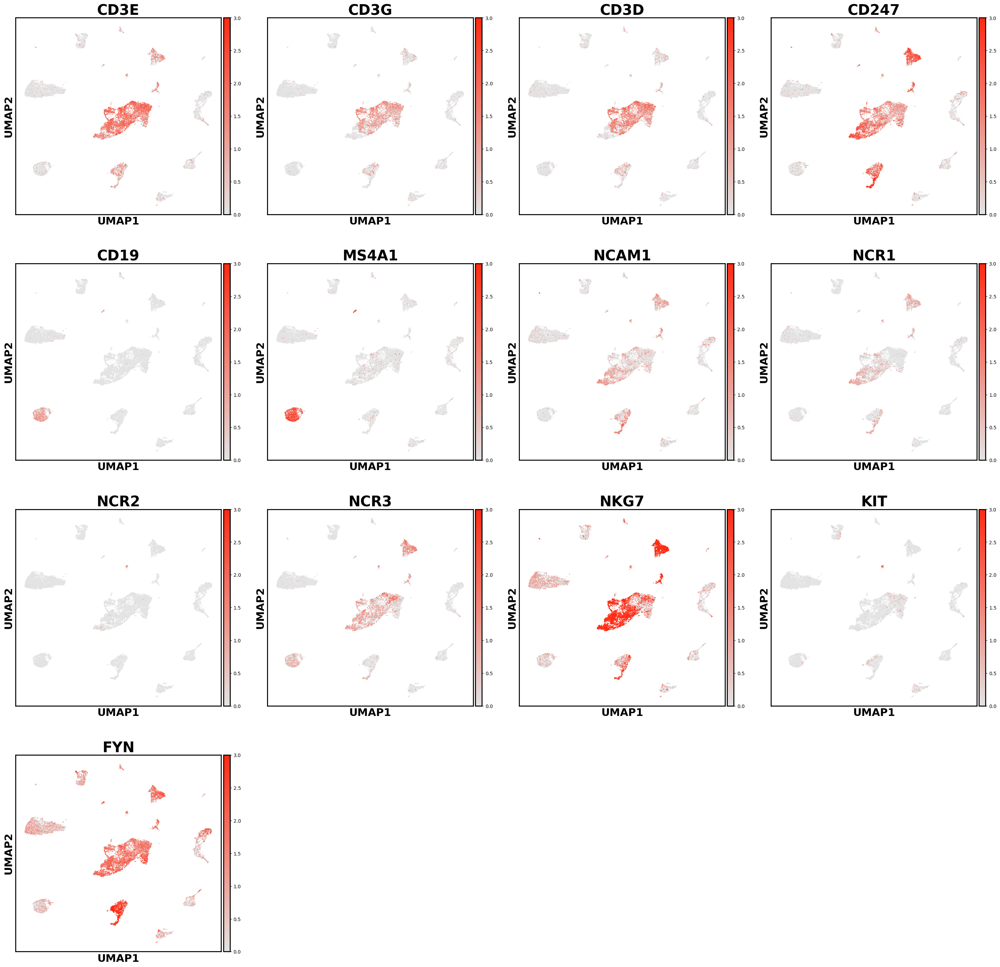

In [211]:
fig = sc.pl.umap(adata, color = ['CD3E','CD3G','CD3D','CD247','CD19','MS4A1','NCAM1','NCR1','NCR2','NCR3','NKG7','KIT','FYN'] ,
                 size = 10, legend_loc = 'on data', palette  = my_palette, ncols = 4, vmax = 3, cmap = my_cmap, return_fig = True, legend_fontsize = 'large')
ax = fig.get_axes()
for i in range(0,len(ax)):
    ax[i].xaxis.label.set_fontsize(22)
    ax[i].xaxis.label.set_fontweight('bold')
    ax[i].yaxis.label.set_fontsize(22)
    ax[i].title.set_fontsize(30)
    ax[i].yaxis.label.set_fontweight('bold')
    ax[i].title.set_fontweight('bold')
#plt.savefig('overall_map_withunmatched.png')

## Subclustering

### Cluster 0

In [ ]:
subclustering = adata[adata.obs['leiden'].isin(['0']),:]

In [ ]:
del subclustering.uns

In [ ]:
subclustering =subclustering[:,~np.isnan(subclustering.X.A).any(axis=0)]

In [ ]:
sc.pp.neighbors(subclustering, n_neighbors = 15, n_pcs = 50)
sc.tl.leiden(subclustering, resolution = 1, key_added= 'leiden')                                                 

In [ ]:
sc.tl.tsne(subclustering)

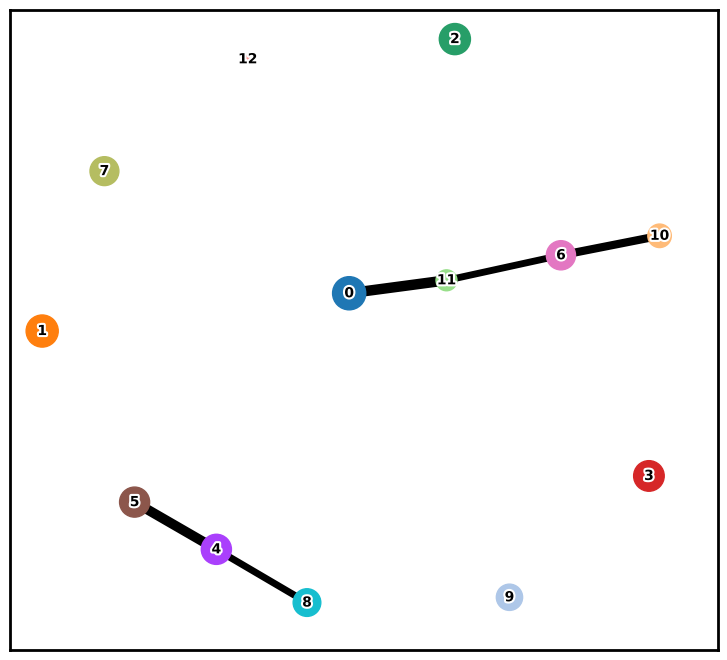

In [ ]:
sc.tl.paga(subclustering, groups='leiden')
sc.pl.paga(subclustering,threshold = 0.6, labels=None, fontsize = 10, fontoutline = 3,node_size_scale = 3,node_size_power = 1,random_state = 0)
sc.tl.umap(subclustering, min_dist = 0.001, spread = 1.5,init_pos = 'paga')

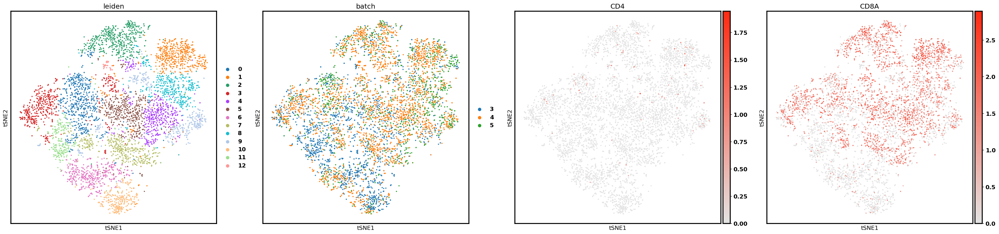

In [ ]:
sc.pl.tsne(subclustering, color = ['leiden','batch','CD4','CD8A'],cmap = my_cmap)

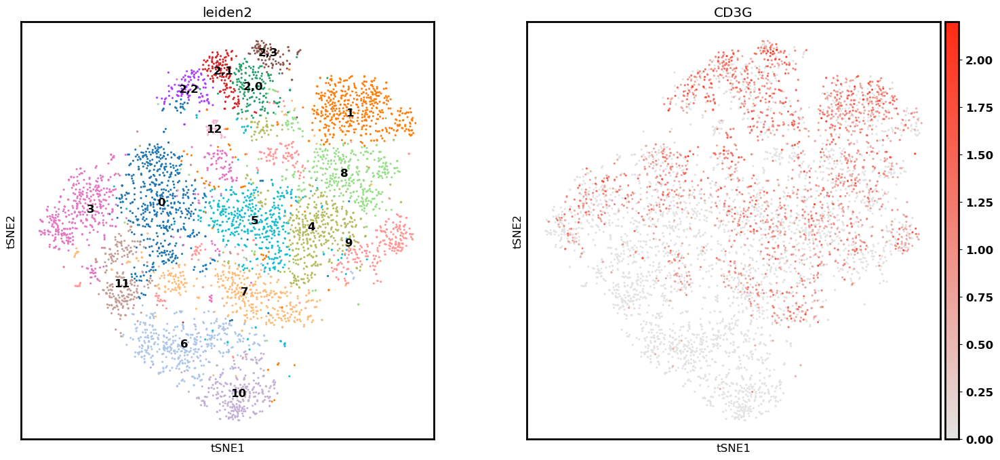

In [ ]:
plt.rcParams['figure.figsize'] = [8,8]
sc.tl.leiden(subclustering, restrict_to = ('leiden', ['2']), resolution = 0.6, key_added= 'leiden2')
sc.pl.tsne(subclustering, color=['leiden2','CD3G'], size = 20, legend_loc = 'on data', cmap = my_cmap)
#go back to the DE section to make sure this subcluster make sense

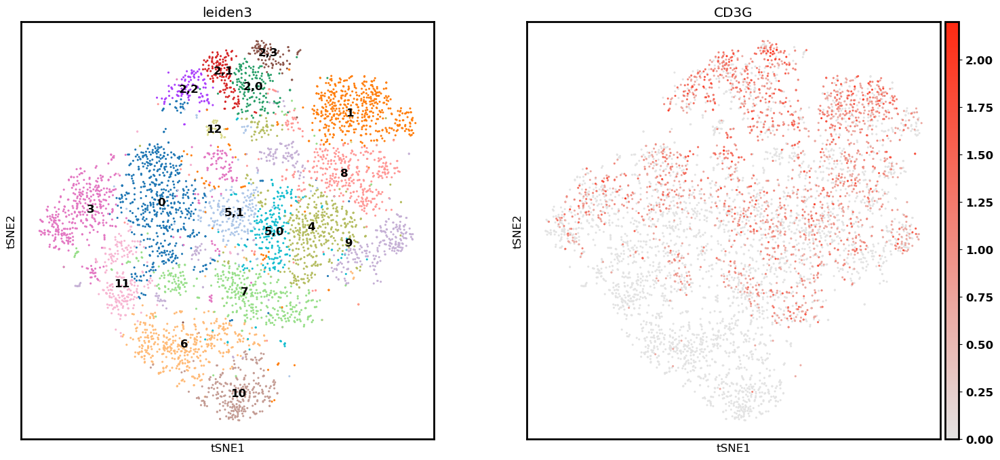

In [ ]:
plt.rcParams['figure.figsize'] = [8,8]
sc.tl.leiden(subclustering, restrict_to = ('leiden2', ['5']), resolution = 0.3, key_added= 'leiden3')
sc.pl.tsne(subclustering, color=['leiden3','CD3G'], size = 20, legend_loc = 'on data', cmap = my_cmap)
#go back to the DE section to make sure this subcluster make sense

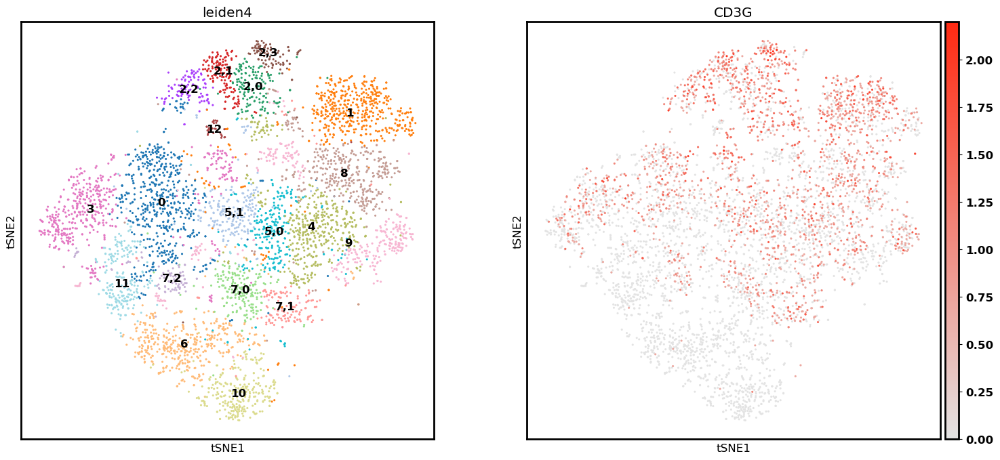

In [ ]:
plt.rcParams['figure.figsize'] = [8,8]
sc.tl.leiden(subclustering, restrict_to = ('leiden3', ['7']), resolution = 0.25, key_added= 'leiden4')
sc.pl.tsne(subclustering, color=['leiden4','CD3G'], size = 20, legend_loc = 'on data', cmap = my_cmap)
#go back to the DE section to make sure this subcluster make sense

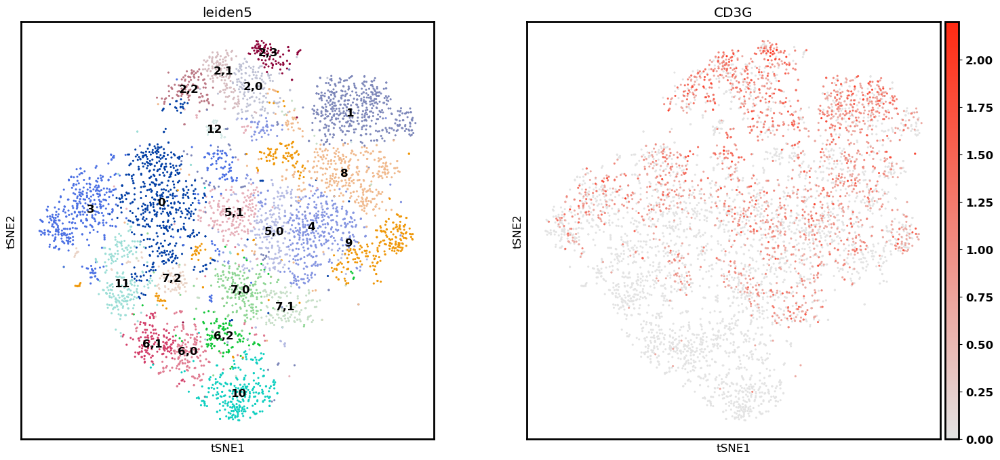

In [ ]:
plt.rcParams['figure.figsize'] = [8,8]
sc.tl.leiden(subclustering, restrict_to = ('leiden4', ['6']), resolution = 0.3, key_added= 'leiden5')
sc.pl.tsne(subclustering, color=['leiden5','CD3G'], size = 20, legend_loc = 'on data', cmap = my_cmap)
#go back to the DE section to make sure this subcluster make sense

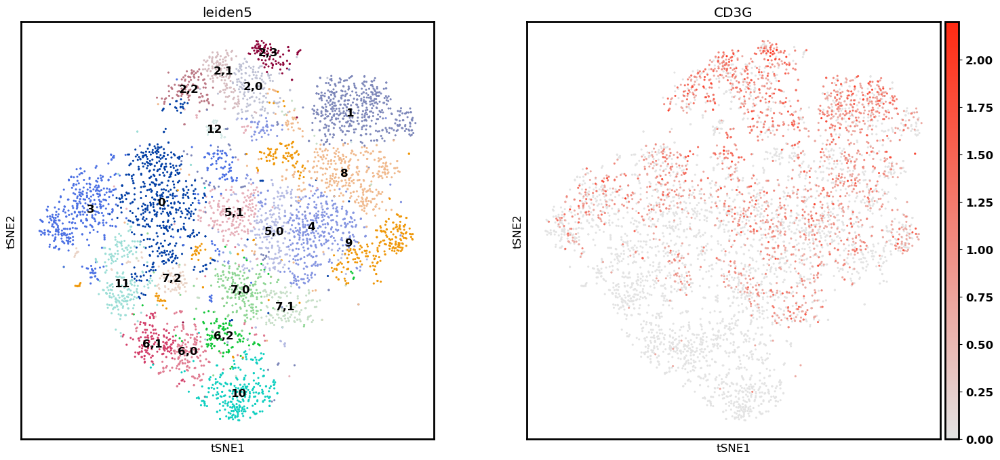

In [ ]:
plt.rcParams['figure.figsize'] = [8,8]
sc.tl.leiden(subclustering, restrict_to = ('leiden4', ['6']), resolution = 0.3, key_added= 'leiden5')
sc.pl.tsne(subclustering, color=['leiden5','CD3G'], size = 20, legend_loc = 'on data', cmap = my_cmap)
#go back to the DE section to make sure this subcluster make sense

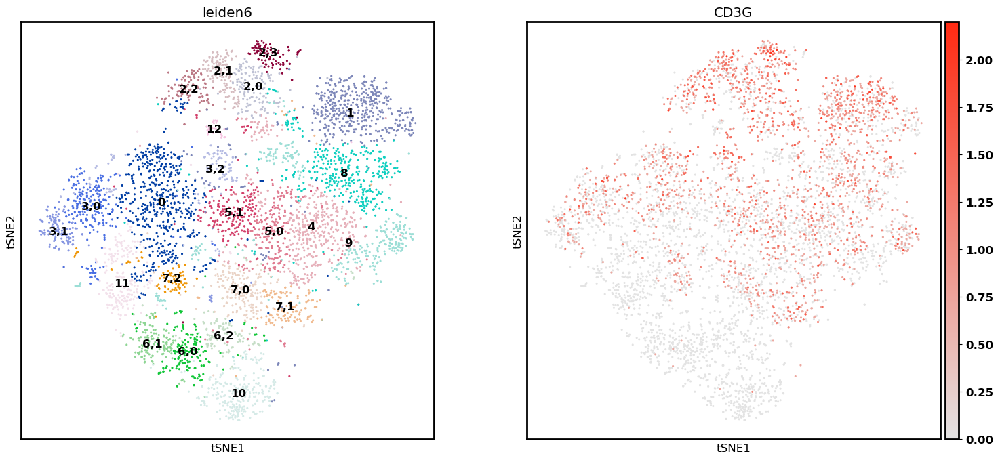

In [ ]:
plt.rcParams['figure.figsize'] = [8,8]
sc.tl.leiden(subclustering, restrict_to = ('leiden5', ['3']), resolution = 0.3, key_added= 'leiden6')
sc.pl.tsne(subclustering, color=['leiden6','CD3G'], size = 20, legend_loc = 'on data', cmap = my_cmap)
#go back to the DE section to make sure this subcluster make sense

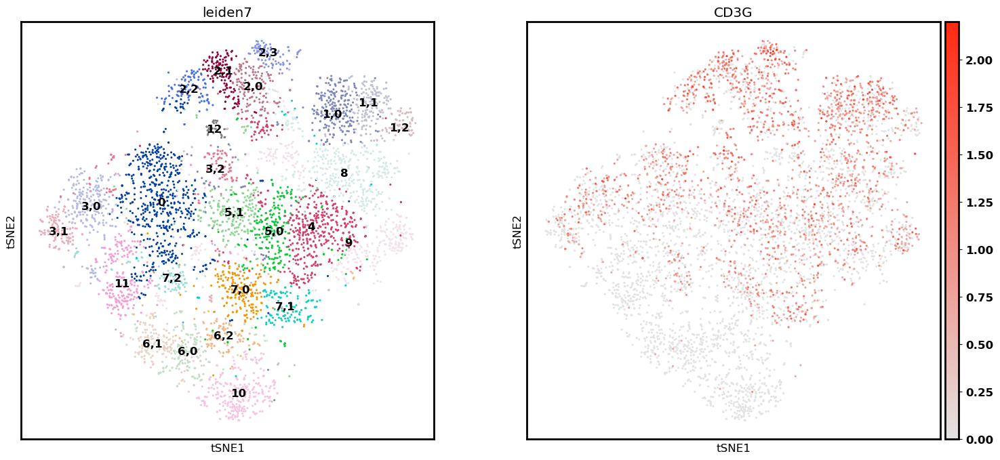

In [ ]:
plt.rcParams['figure.figsize'] = [8,8]
sc.tl.leiden(subclustering, restrict_to = ('leiden6', ['1']), resolution = 0.4, key_added= 'leiden7')
sc.pl.tsne(subclustering, color=['leiden7','CD3G'], size = 20, legend_loc = 'on data', cmap = my_cmap)
#go back to the DE section to make sure this subcluster make sense

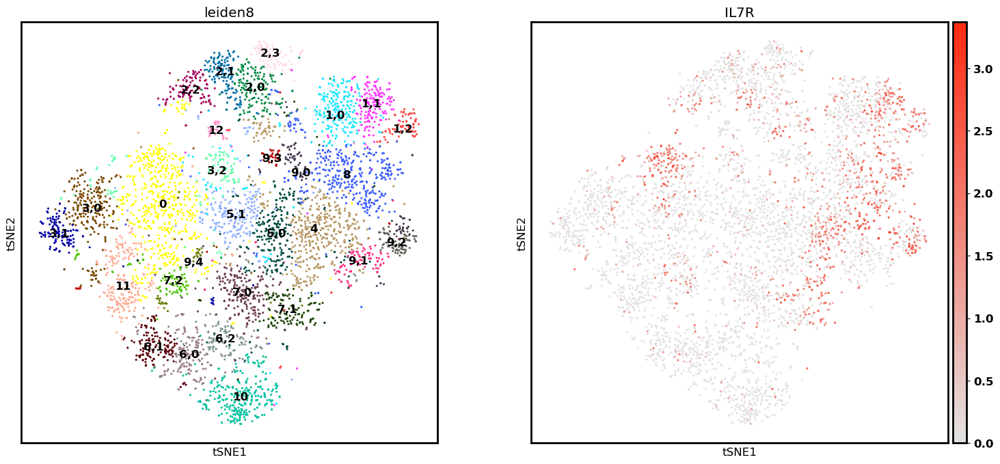

In [ ]:
plt.rcParams['figure.figsize'] = [8,8]
sc.tl.leiden(subclustering, restrict_to = ('leiden7', ['9']), resolution = 0.5, key_added= 'leiden8')
sc.pl.tsne(subclustering, color=['leiden8','IL7R'], size = 20, legend_loc = 'on data', cmap = my_cmap)
#go back to the DE section to make sure this subcluster make sense

In [ ]:
subclustering.obs['cluster_blind'] = subclustering.obs.groupby('leiden8').ngroup().astype('str')

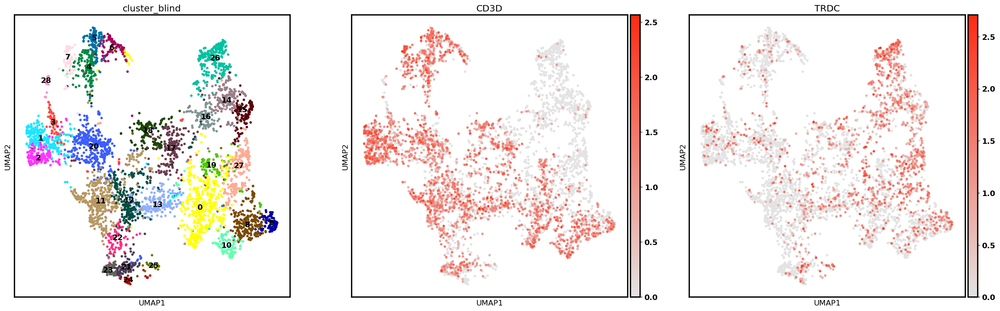

In [ ]:
sc.pl.umap(subclustering, color=['cluster_blind','CD3D','TRDC'], size = 60, legend_loc = 'on data', cmap = my_cmap)

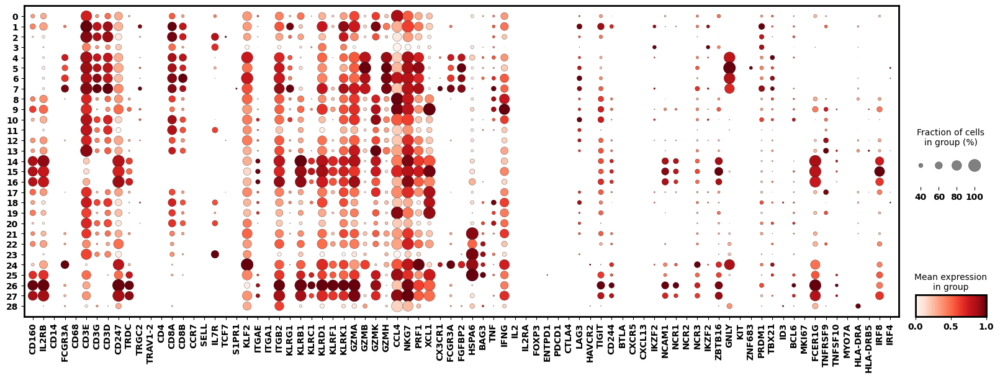

In [ ]:
plt.rcParams.update({'font.size': 12, 'font.weight': 'heavy','axes.linewidth':2})
#plt.rcParams.update(plt.rcParamsDefault)

gene_list = ['CD160','IL2RB','CD14','FCGR3A','CD68','CD3E','CD3G','CD3D','CD247','TRDC','TRGC2','TRAV1-2','CD4','CD8A','CD8B','CCR7','SELL','IL7R','TCF7','S1PR1','KLF2',
                    'ITGAE','ITGA1','ITGB2','KLRG1','KLRB1','KLRC1','KLRD1','KLRF1','KLRK1','GZMA','GZMB','GZMK','GZMH','CCL4','NKG7','PRF1',
                         'XCL1','CX3CR1','FCGR3A','FGFBP2','HSPA6','BAG3','TNF','IFNG','IL2','IL2RA','FOXP3','ENTPD1','PDCD1','CTLA4','LAG3','HAVCR2','TIGIT',
             'CD244','BTLA','CXCR5','CXCL13','IKZF2','NCAM1','NCR1','NCR2','NCR3','IKZF2','ZBTB16',
             'GNLY','KIT','ZNF683','PRDM1','TBX21','ID3','BCL6','MKI67','FCER1G','TNFRSF9','TNFSF10','MYO7A','HLA-DRA','HLA-DRB5','IRF8','IRF4']
sc.pl.dotplot(subclustering,gene_list,groupby = 'cluster_blind' , vmax = 1, 
              swap_axes = False ,dot_min = 0.2,standard_scale = 'var',figsize = (20,6.5))

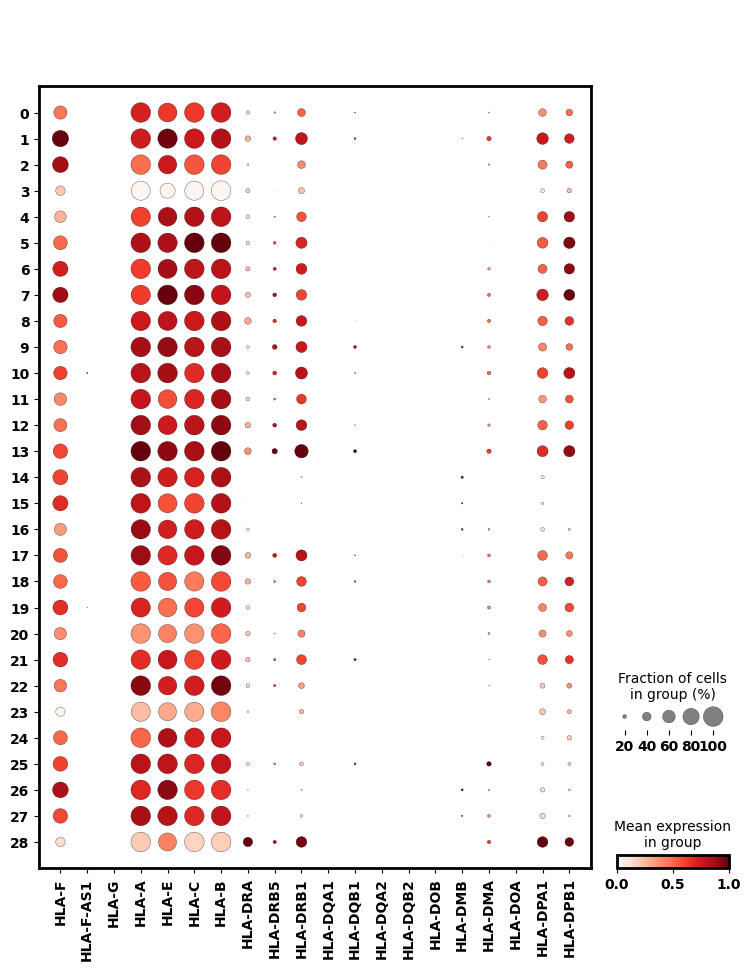

In [ ]:
# plt.rcParams.update({'font.size': 15, 'font.weight': 'heavy','axes.linewidth':2})
#plt.rcParams.update(plt.rcParamsDefault)
gamma_genesmask = [gene.startswith("HLA") for gene in subclustering.var_names]
gamma_genes = subclustering.var_names[gamma_genesmask]

sc.pl.dotplot(subclustering,gamma_genes,groupby = 'cluster_blind' , vmax = 1, swap_axes = False, dot_min =0.1, dot_max =1,standard_scale = 'var')

In [ ]:
subclustering.obs['cell type'] = subclustering.obs['cluster_blind']
subclustering.obs['cell type'] = subclustering.obs['cell type'].astype('str')

TRM = np.array([0,18,11,19,20])
TRM = [str(i) for i in TRM]

TEM = np.array([2,3,5,23])
TEM = [str(i) for i in TEM]

effector = np.array([1,4,5,6,7,8,9,10,12,13,17,21,22,28])
effector = [str(i) for i in effector]

NK = np.array([24,25,26,27,14,15,16])
NK = [str(i) for i in NK]


for c_id in set(subclustering.obs['cluster_blind']):
    if c_id in TRM:
        subclustering.obs = subclustering.obs.replace({'cell type' : { c_id: 'TRM'}})
    if c_id in TEM:
        subclustering.obs = subclustering.obs.replace({'cell type' : { c_id: 'TEM'}})
    if c_id in effector:
        subclustering.obs = subclustering.obs.replace({'cell type' : { c_id: 'effector'}})
    if c_id in NK:
        subclustering.obs = subclustering.obs.replace({'cell type' : { c_id: 'NK'}})

subclustering.obs['cell type'] = subclustering.obs['cell type'].astype('category')

In [ ]:
subclustering.obs['T type'] = subclustering.obs['cluster_blind']
subclustering.obs['T type'] = subclustering.obs['T type'].astype('str')

gdT = np.array([0,8,9,12,13,17,21])
gdT = [str(i) for i in gdT]

NK = np.array([24,25,26,27,14,15,16])
NK = [str(i) for i in NK]


for c_id in set(subclustering.obs['cluster_blind']):
    if c_id in gdT:
        subclustering.obs = subclustering.obs.replace({'T type' : { c_id: 'TCRgd'}})
    if c_id in NK:
        subclustering.obs = subclustering.obs.replace({'T type' : { c_id: ''}})
    else:
        subclustering.obs = subclustering.obs.replace({'T type' : { c_id: 'TCRab CD8'}})

subclustering.obs['T type'] = subclustering.obs['T type'].astype('category')

In [ ]:
subclustering.obs['Detailed Cell Type'] = subclustering.obs['T type'].astype(str).map(str) + ' ' +subclustering.obs['cell type'].astype(str).map(str)

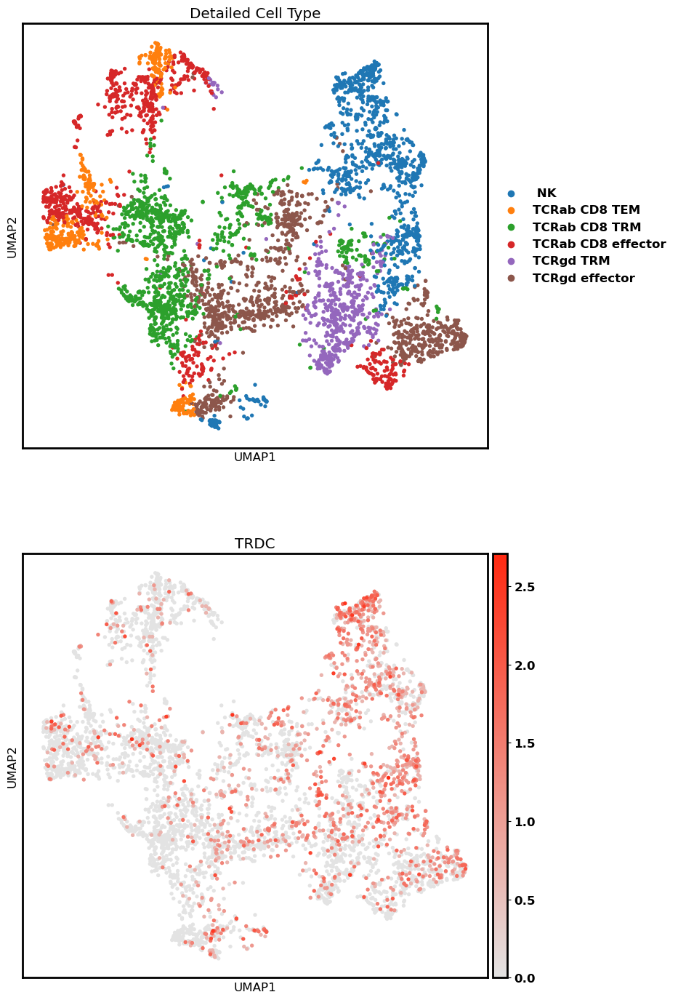

In [ ]:
sc.pl.umap(subclustering, color=['Detailed Cell Type','TRDC'],ncols=1, size = 60,cmap = my_cmap)

In [ ]:
subclustering.write('cluster0.h5ad')

In [ ]:
subclustering = sc.read_h5ad('cluster0.h5ad')

In [ ]:
df_0 = subclustering.obs[['cell type','T type','Detailed Cell Type']]

### Cluster 2

In [ ]:
subclustering = adata[adata.obs['leiden'].isin(['2']),:]

In [ ]:
subclustering =subclustering[:,~np.isnan(subclustering.X.A).any(axis=0)]

In [ ]:
del subclustering.uns

In [ ]:
sc.pp.neighbors(subclustering, n_neighbors = 15, n_pcs = 50)
sc.tl.leiden(subclustering, resolution = 1, key_added= 'leiden')                                                 

In [ ]:
sc.tl.tsne(subclustering)

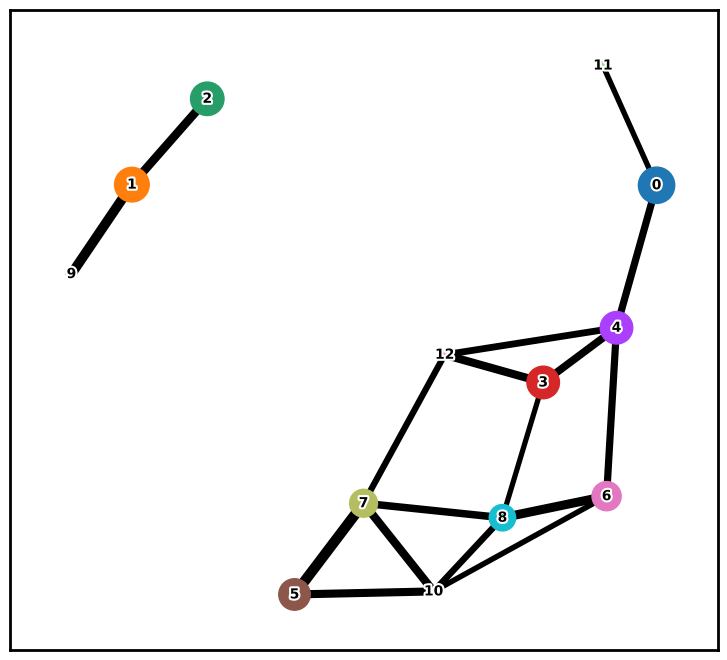

In [ ]:
sc.tl.paga(subclustering, groups='leiden')
sc.pl.paga(subclustering,threshold = 0.5, labels=None, fontsize = 10, fontoutline = 3,node_size_scale = 3,node_size_power = 1,random_state = 0)
sc.tl.umap(subclustering, min_dist = 0.001, spread = 1.5,init_pos = 'paga')

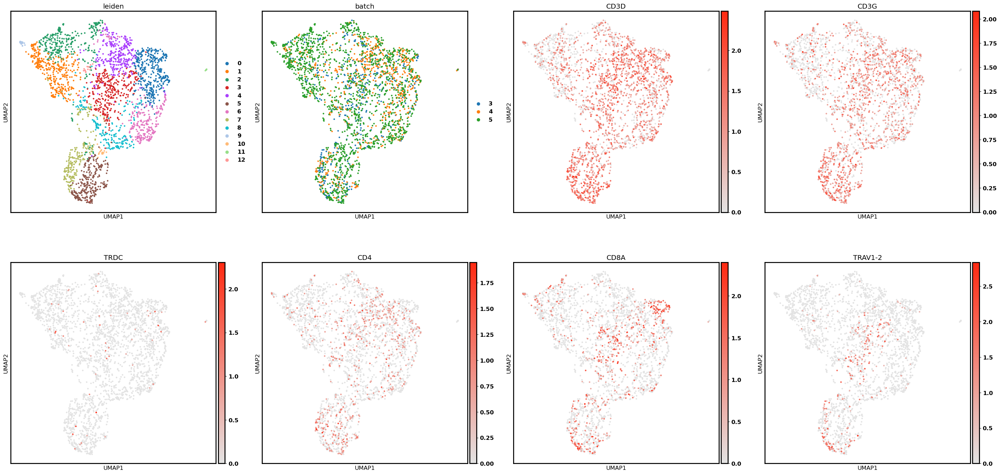

In [ ]:
sc.pl.umap(subclustering, color = ['leiden','batch','CD3D','CD3G','TRDC','CD4','CD8A','TRAV1-2'],cmap = my_cmap)

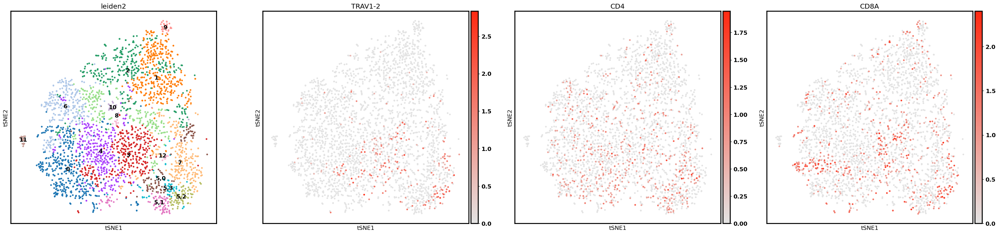

In [ ]:
plt.rcParams['figure.figsize'] = [8,8]
sc.tl.leiden(subclustering, restrict_to = ('leiden', ['5']), resolution = 0.5, key_added= 'leiden2')
sc.pl.tsne(subclustering, color=['leiden2','TRAV1-2','CD4','CD8A'], size = 50, legend_loc = 'on data', cmap = my_cmap)
#go back to the DE section to make sure this subcluster make sense

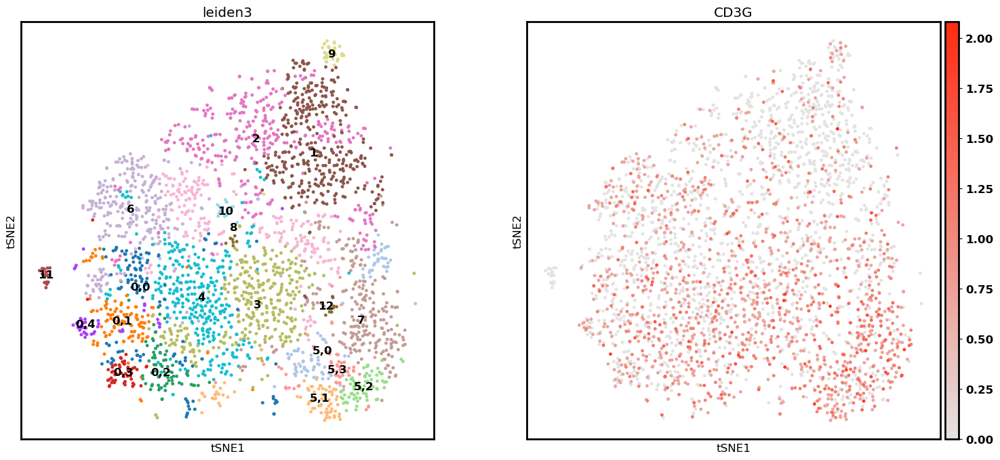

In [ ]:
plt.rcParams['figure.figsize'] = [8,8]
sc.tl.leiden(subclustering, restrict_to = ('leiden2', ['0']), resolution = 0.6, key_added= 'leiden3')
sc.pl.tsne(subclustering, color=['leiden3','CD3G'], size = 50, legend_loc = 'on data', cmap = my_cmap)
#go back to the DE section to make sure this subcluster make sense

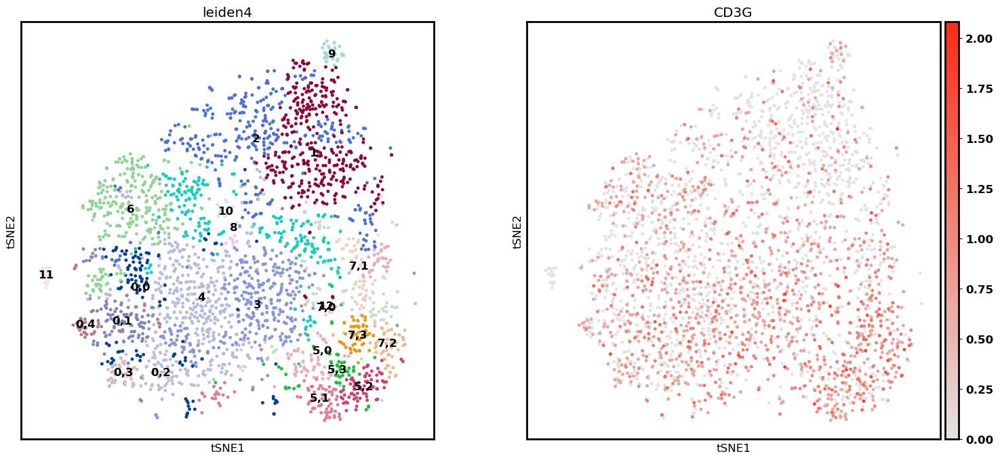

In [ ]:
plt.rcParams['figure.figsize'] = [8,8]
sc.tl.leiden(subclustering, restrict_to = ('leiden3', ['7']), resolution = 0.4, key_added= 'leiden4')
sc.pl.tsne(subclustering, color=['leiden4','CD3G'], size = 50, legend_loc = 'on data', cmap = my_cmap)
#go back to the DE section to make sure this subcluster make sense

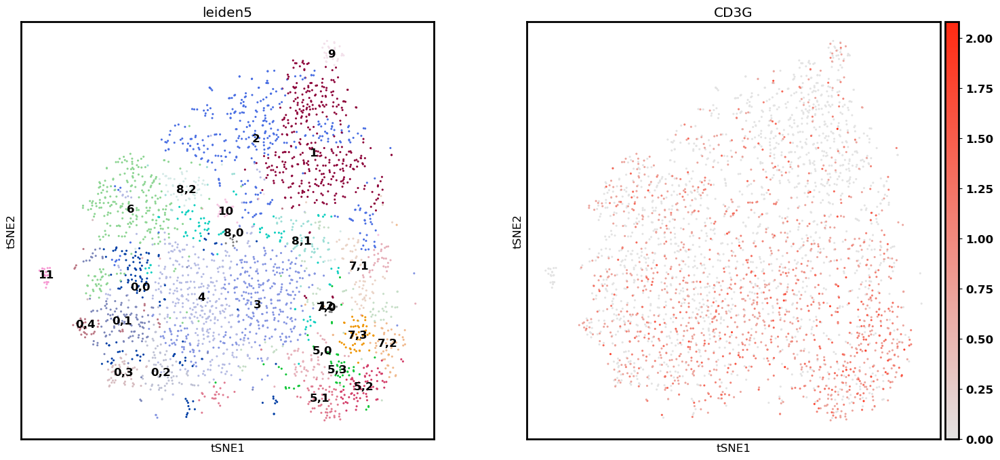

In [ ]:
plt.rcParams['figure.figsize'] = [8,8]
sc.tl.leiden(subclustering, restrict_to = ('leiden4', ['8']), resolution = 0.3, key_added= 'leiden5')
sc.pl.tsne(subclustering, color=['leiden5','CD3G'], size = 20, legend_loc = 'on data', cmap = my_cmap)
#go back to the DE section to make sure this subcluster make sense

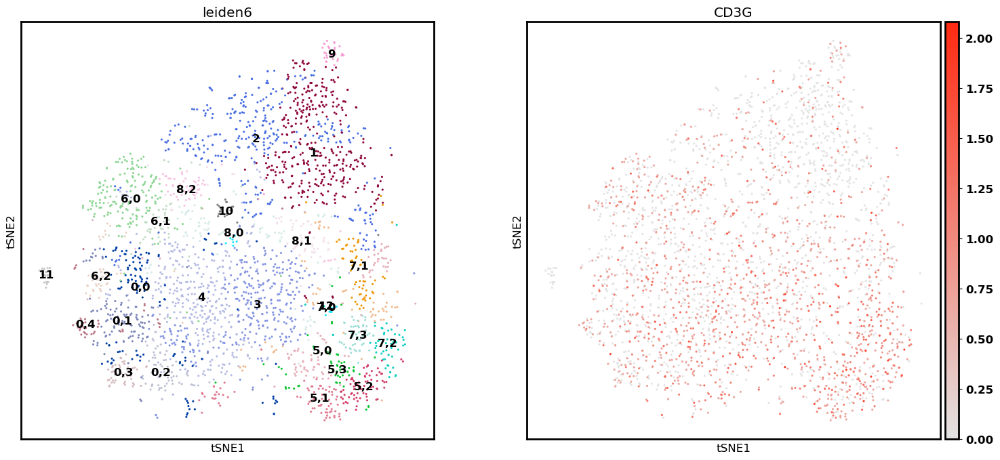

In [ ]:
plt.rcParams['figure.figsize'] = [8,8]
sc.tl.leiden(subclustering, restrict_to = ('leiden5', ['6']), resolution = 0.3, key_added= 'leiden6')
sc.pl.tsne(subclustering, color=['leiden6','CD3G'], size = 20, legend_loc = 'on data', cmap = my_cmap)
#go back to the DE section to make sure this subcluster make sense

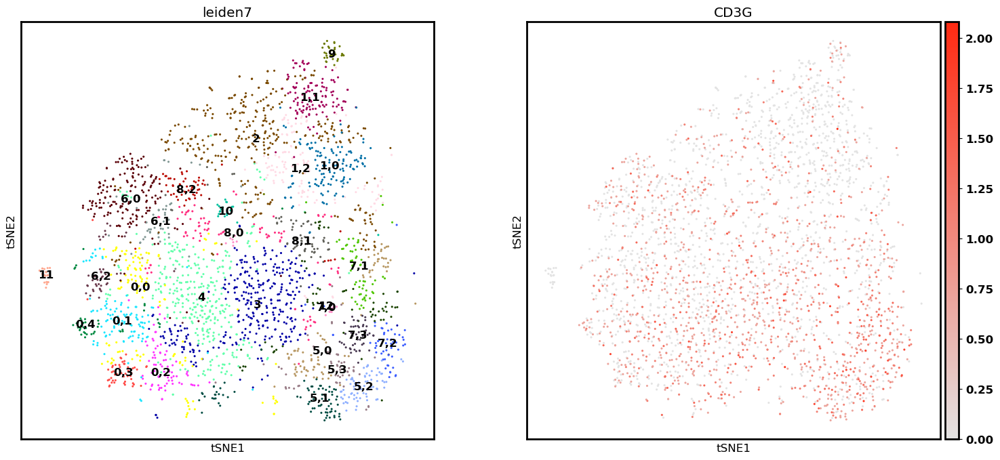

In [ ]:
plt.rcParams['figure.figsize'] = [8,8]
sc.tl.leiden(subclustering, restrict_to = ('leiden6', ['1']), resolution = 0.45, key_added= 'leiden7')
sc.pl.tsne(subclustering, color=['leiden7','CD3G'], size = 20, legend_loc = 'on data', cmap = my_cmap)
#go back to the DE section to make sure this subcluster make sense

In [ ]:
subclustering.obs['cluster_blind'] = subclustering.obs.groupby('leiden7').ngroup().astype('str')

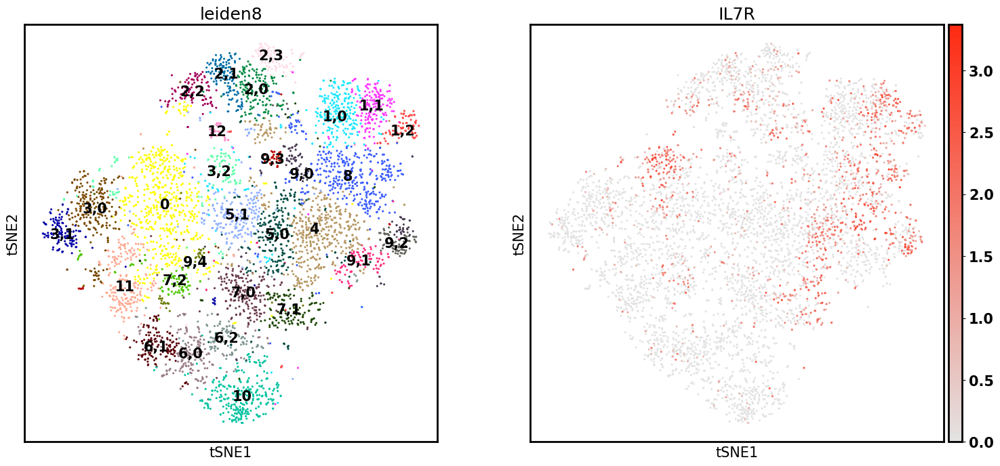

In [ ]:
plt.rcParams['figure.figsize'] = [8,8]
sc.tl.leiden(subclustering, restrict_to = ('leiden7', ['9']), resolution = 0.5, key_added= 'leiden8')
sc.pl.tsne(subclustering, color=['leiden8','IL7R'], size = 20, legend_loc = 'on data', cmap = my_cmap)
#go back to the DE section to make sure this subcluster make sense

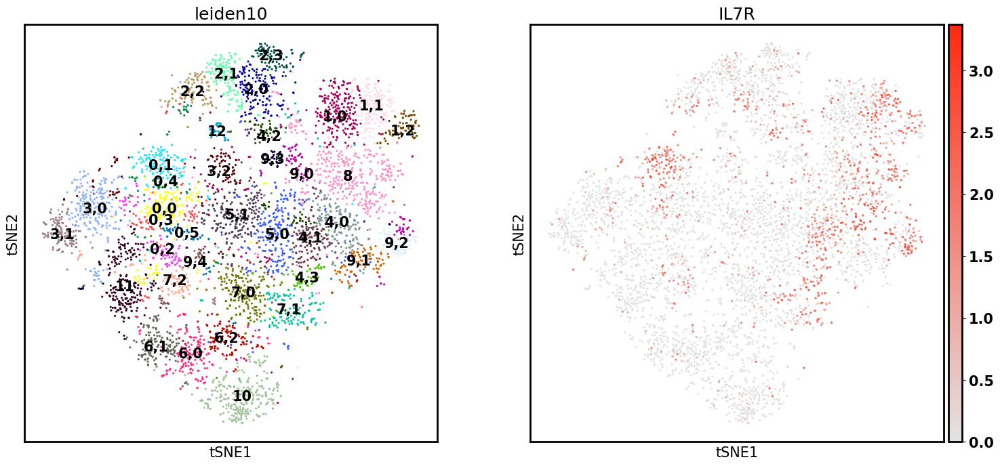

In [ ]:
plt.rcParams['figure.figsize'] = [8,8]
sc.tl.leiden(subclustering, restrict_to = ('leiden9', ['4']), resolution = 0.6, key_added= 'leiden10')
sc.pl.tsne(subclustering, color=['leiden10','IL7R'], size = 20, legend_loc = 'on data', cmap = my_cmap)
#go back to the DE section to make sure this subcluster make sense

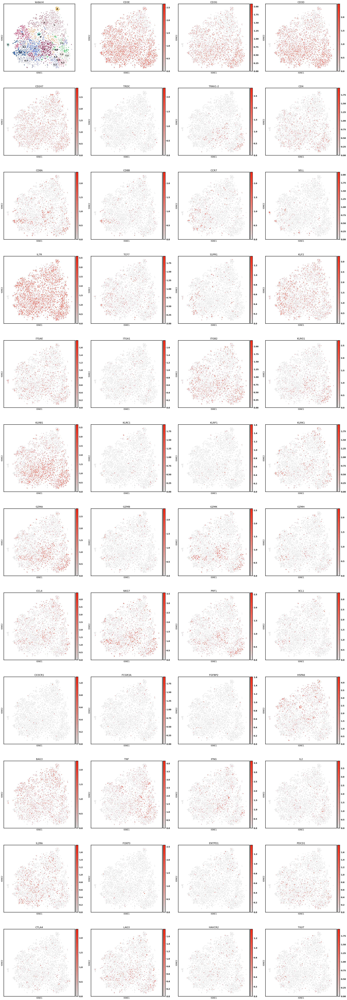

In [ ]:
sc.pl.tsne(subclustering, color = ['leiden4','CD3E','CD3G','CD3D','CD247','TRDC','TRAV1-2','CD4','CD8A','CD8B','CCR7','SELL','IL7R','TCF7','S1PR1','KLF2',
                    'ITGAE','ITGA1','ITGB2','KLRG1','KLRB1','KLRC1','KLRF1','KLRK1','GZMA','GZMB','GZMK','GZMH','CCL4','NKG7','PRF1',
                         'XCL1','CX3CR1','FCGR3A','FGFBP2','HSPA6','BAG3','TNF','IFNG','IL2','IL2RA','FOXP3','ENTPD1','PDCD1','CTLA4','LAG3','HAVCR2','TIGIT'],
           cmap = my_cmap,legend_loc = 'on data',size = 50)

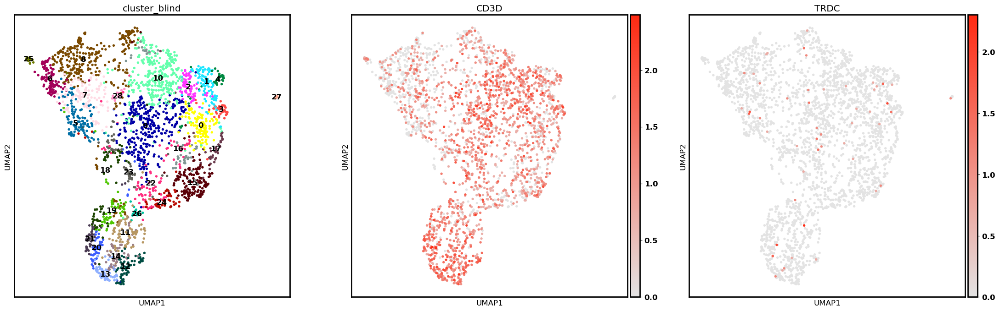

In [ ]:
sc.pl.umap(subclustering, color=['cluster_blind','CD3D','TRDC'], size = 60, legend_loc = 'on data', cmap = my_cmap)

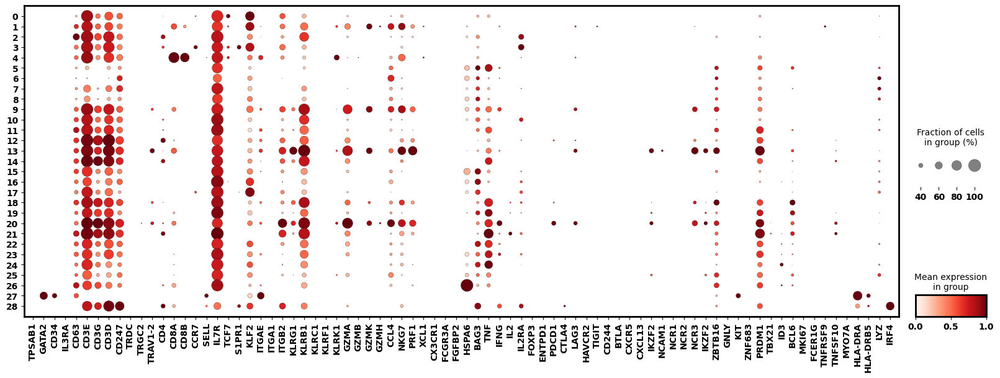

In [ ]:
plt.rcParams.update({'font.size': 12, 'font.weight': 'heavy','axes.linewidth':2})
#plt.rcParams.update(plt.rcParamsDefault)

gene_list = ['TPSAB1','GATA2','CD34','IL3RA','CD63','CD3E','CD3G','CD3D','CD247','TRDC','TRGC2','TRAV1-2','CD4','CD8A','CD8B','CCR7','SELL','IL7R','TCF7','S1PR1','KLF2',
                    'ITGAE','ITGA1','ITGB2','KLRG1','KLRB1','KLRC1','KLRF1','KLRK1','GZMA','GZMB','GZMK','GZMH','CCL4','NKG7','PRF1',
                         'XCL1','CX3CR1','FCGR3A','FGFBP2','HSPA6','BAG3','TNF','IFNG','IL2','IL2RA','FOXP3','ENTPD1','PDCD1','CTLA4','LAG3','HAVCR2','TIGIT',
             'CD244','BTLA','CXCR5','CXCL13','IKZF2','NCAM1','NCR1','NCR2','NCR3','IKZF2','ZBTB16',
             'GNLY','KIT','ZNF683','PRDM1','TBX21','ID3','BCL6','MKI67','FCER1G','TNFRSF9','TNFSF10','MYO7A','HLA-DRA','HLA-DRB5','LYZ','IRF4']
sc.pl.dotplot(subclustering,gene_list,groupby = 'cluster_blind' , vmax = 1, 
              swap_axes = False ,dot_min = 0.2,standard_scale = 'var',figsize = (20,6.5))

In [ ]:
subclustering.obs['cell type'] = subclustering.obs['cluster_blind']
subclustering.obs['cell type'] = subclustering.obs['cell type'].astype('str')

DNT = np.array([5,6,7,8,15,16,17])
DNT = [str(i) for i in DNT]

TCM = np.array([0,1,2,3,4,17,28])
TCM = [str(i) for i in TCM]

MAIT = np.array([20,18,13,9])
MAIT = [str(i) for i in MAIT]

Mast_prog = np.array([27])
Mast_prog = [str(i) for i in Mast_prog]

for c_id in set(subclustering.obs['cluster_blind']):
    if c_id in DNT:
        subclustering.obs = subclustering.obs.replace({'cell type' : { c_id: 'DNT'}})
    if c_id in TCM:
        subclustering.obs = subclustering.obs.replace({'cell type' : { c_id: 'TCM'}})
    if c_id in MAIT:
        subclustering.obs = subclustering.obs.replace({'cell type' : { c_id: 'MAIT'}})
    if c_id in Basophil:
        subclustering.obs = subclustering.obs.replace({'cell type' : { c_id: 'Mast Progenitor'}})
    else:
        subclustering.obs = subclustering.obs.replace({'cell type' : { c_id: 'TRM'}})

subclustering.obs['cell type'] = subclustering.obs['cell type'].astype('category')

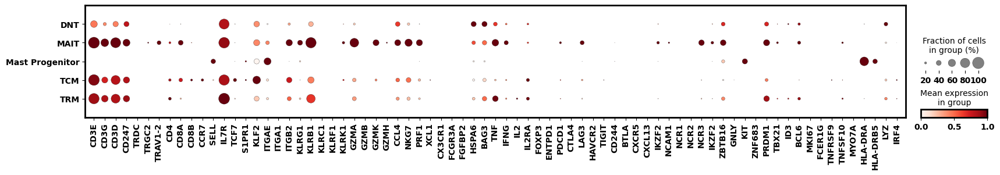

In [ ]:
plt.rcParams.update({'font.size': 12, 'font.weight': 'heavy','axes.linewidth':2})
#plt.rcParams.update(plt.rcParamsDefault)

gene_list = ['CD3E','CD3G','CD3D','CD247','TRDC','TRGC2','TRAV1-2','CD4','CD8A','CD8B','CCR7','SELL','IL7R','TCF7','S1PR1','KLF2',
                    'ITGAE','ITGA1','ITGB2','KLRG1','KLRB1','KLRC1','KLRF1','KLRK1','GZMA','GZMB','GZMK','GZMH','CCL4','NKG7','PRF1',
                         'XCL1','CX3CR1','FCGR3A','FGFBP2','HSPA6','BAG3','TNF','IFNG','IL2','IL2RA','FOXP3','ENTPD1','PDCD1','CTLA4','LAG3','HAVCR2','TIGIT',
             'CD244','BTLA','CXCR5','CXCL13','IKZF2','NCAM1','NCR1','NCR2','NCR3','IKZF2','ZBTB16',
             'GNLY','KIT','ZNF683','PRDM1','TBX21','ID3','BCL6','MKI67','FCER1G','TNFRSF9','TNFSF10','MYO7A','HLA-DRA','HLA-DRB5','LYZ','IRF4']
sc.pl.dotplot(subclustering,gene_list,groupby = 'cell type' , vmax = 1, 
              swap_axes = False ,dot_min = 0.1,standard_scale = 'var',figsize = (20,2.5))

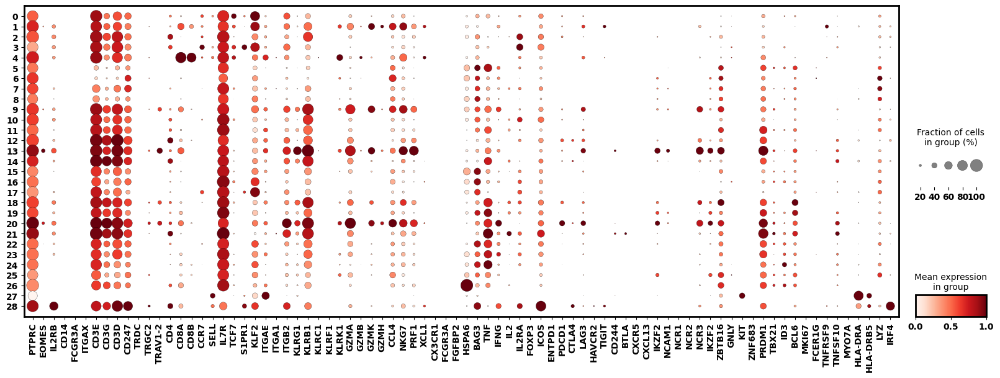

In [ ]:
plt.rcParams.update({'font.size': 12, 'font.weight': 'heavy','axes.linewidth':2})
#plt.rcParams.update(plt.rcParamsDefault)

gene_list = ['PTPRC','EOMES','IL2RB','CD14','FCGR3A','ITGAX','CD3E','CD3G','CD3D','CD247','TRDC','TRGC2','TRAV1-2','CD4','CD8A','CD8B','CCR7','SELL','IL7R','TCF7','S1PR1','KLF2',
                    'ITGAE','ITGA1','ITGB2','KLRG1','KLRB1','KLRC1','KLRF1','KLRK1','GZMA','GZMB','GZMK','GZMH','CCL4','NKG7','PRF1',
                         'XCL1','CX3CR1','FCGR3A','FGFBP2','HSPA6','BAG3','TNF','IFNG','IL2','IL2RA','FOXP3','ICOS','ENTPD1','PDCD1','CTLA4','LAG3','HAVCR2','TIGIT',
             'CD244','BTLA','CXCR5','CXCL13','IKZF2','NCAM1','NCR1','NCR2','NCR3','IKZF2','ZBTB16',
             'GNLY','KIT','ZNF683','PRDM1','TBX21','ID3','BCL6','MKI67','FCER1G','TNFRSF9','TNFSF10','MYO7A','HLA-DRA','HLA-DRB5','LYZ','IRF4']
sc.pl.dotplot(subclustering,gene_list,groupby = 'cluster_blind' , vmax = 1, 
              swap_axes = False ,dot_min = 0.1,standard_scale = 'var',figsize = (20,6.5))

In [ ]:
subclustering.obs['T type'] = subclustering.obs['cluster_blind']
subclustering.obs['T type'] = subclustering.obs['T type'].astype('str')

CD8 = np.array([1,4,9,13,18,19,20,26])
CD8 = [str(i) for i in CD8]

CD4 = np.array([0,2,3,10,11,12,14,19,21,22,23,24,25,26,28])
CD4 = [str(i) for i in CD4]

DNT = np.array([5,6,7,8,15,16,17])
DNT = [str(i) for i in DNT]

for c_id in set(subclustering.obs['cluster_blind']):
    if c_id in CD4:
        subclustering.obs = subclustering.obs.replace({'T type' : { c_id: 'TCRab CD4'}})
    elif c_id in CD8:
        subclustering.obs = subclustering.obs.replace({'T type' : { c_id: 'TCRab CD8'}})
    elif c_id in DNT:
        subclustering.obs = subclustering.obs.replace({'T type' : { c_id: 'TCRab'}})
    else:
        subclustering.obs = subclustering.obs.replace({'T type' : { c_id: ''}})

subclustering.obs['T type'] = subclustering.obs['T type'].astype('category')

In [ ]:
subclustering.obs['Detailed Cell Type'] = subclustering.obs['T type'].astype(str).map(str) + ' ' +subclustering.obs['cell type'].astype(str).map(str)

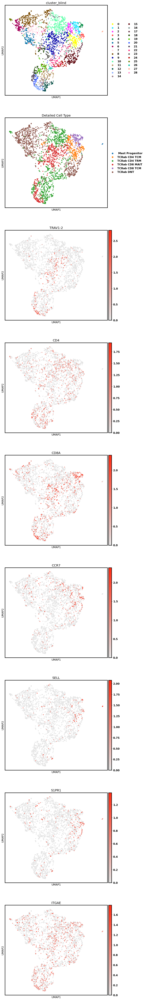

In [ ]:
sc.pl.umap(subclustering, color=['cluster_blind','Detailed Cell Type','TRAV1-2','CD4','CD8A','CCR7','SELL','S1PR1','ITGAE'], ncols = 1, size = 60, cmap = my_cmap)

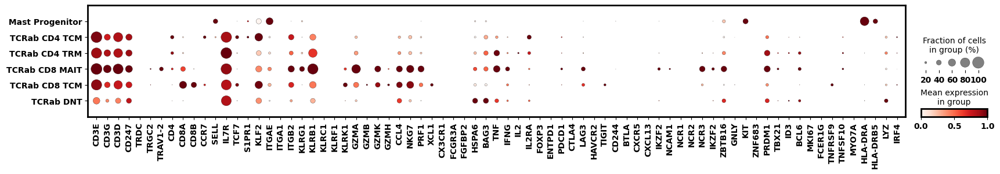

In [ ]:
plt.rcParams.update({'font.size': 12, 'font.weight': 'heavy','axes.linewidth':2})
#plt.rcParams.update(plt.rcParamsDefault)

gene_list = ['CD3E','CD3G','CD3D','CD247','TRDC','TRGC2','TRAV1-2','CD4','CD8A','CD8B','CCR7','SELL','IL7R','TCF7','S1PR1','KLF2',
                    'ITGAE','ITGA1','ITGB2','KLRG1','KLRB1','KLRC1','KLRF1','KLRK1','GZMA','GZMB','GZMK','GZMH','CCL4','NKG7','PRF1',
                         'XCL1','CX3CR1','FCGR3A','FGFBP2','HSPA6','BAG3','TNF','IFNG','IL2','IL2RA','FOXP3','ENTPD1','PDCD1','CTLA4','LAG3','HAVCR2','TIGIT',
             'CD244','BTLA','CXCR5','CXCL13','IKZF2','NCAM1','NCR1','NCR2','NCR3','IKZF2','ZBTB16',
             'GNLY','KIT','ZNF683','PRDM1','TBX21','ID3','BCL6','MKI67','FCER1G','TNFRSF9','TNFSF10','MYO7A','HLA-DRA','HLA-DRB5','LYZ','IRF4']
sc.pl.dotplot(subclustering,gene_list,groupby = 'Detailed Cell Type' , vmax = 1, 
              swap_axes = False ,dot_min = 0.1,standard_scale = 'var',figsize = (20,2.5))

In [ ]:
subclustering.write('cluster2.h5ad')

In [ ]:
subclustering = sc.read_h5ad('cluster2.h5ad')

In [ ]:
df_2 = subclustering.obs[['cell type','T type','Detailed Cell Type']]

### Cluster 4

In [ ]:
subclustering = adata[adata.obs['leiden'].isin(['4']),:]

In [ ]:
subclustering =subclustering[:,~np.isnan(subclustering.X.A).any(axis=0)]

In [ ]:
del subclustering.uns

In [ ]:
sc.pp.neighbors(subclustering, n_neighbors = 15, n_pcs = 50)
sc.tl.leiden(subclustering, resolution = 1, key_added= 'leiden')                                                 

In [ ]:
sc.tl.tsne(subclustering)

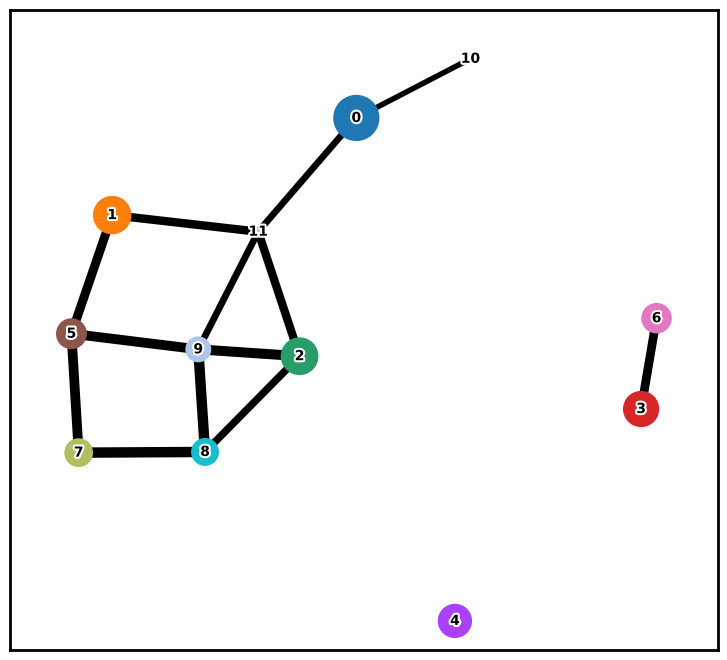

In [ ]:
sc.tl.paga(subclustering, groups='leiden')
sc.pl.paga(subclustering,threshold = 0.5, labels=None, fontsize = 10, fontoutline = 3,node_size_scale = 3,node_size_power = 1,random_state = 0)
sc.tl.umap(subclustering, min_dist = 0.001, spread = 1.5,init_pos = 'paga')

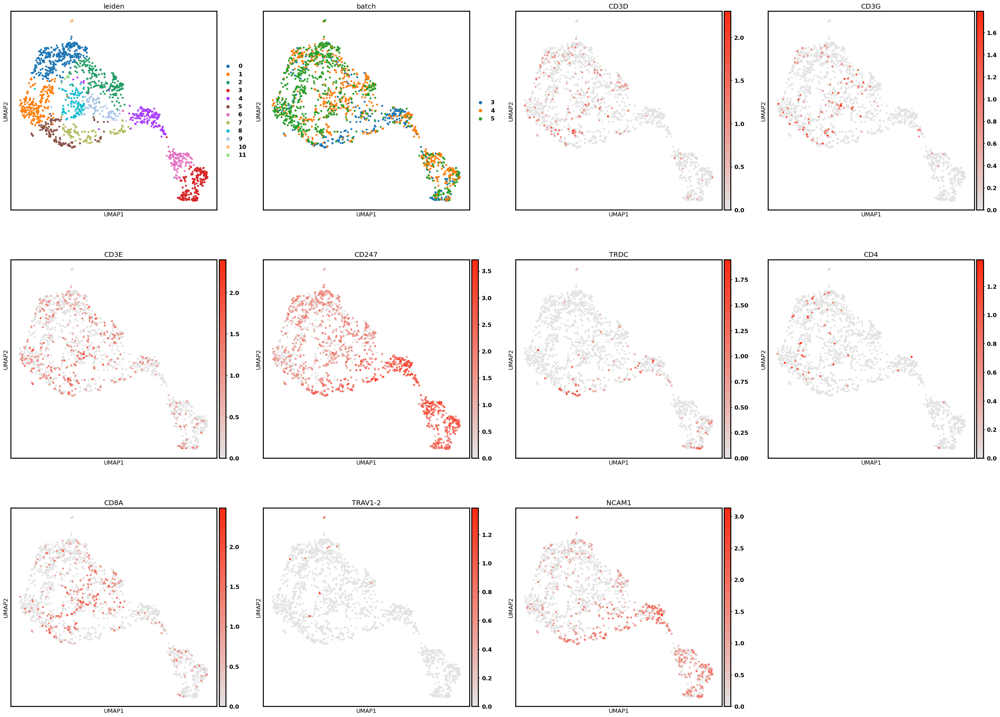

In [ ]:
sc.pl.umap(subclustering, color = ['leiden','batch','CD3D','CD3G','CD3E','CD247','TRDC','CD4','CD8A','TRAV1-2','NCAM1'],cmap = my_cmap)

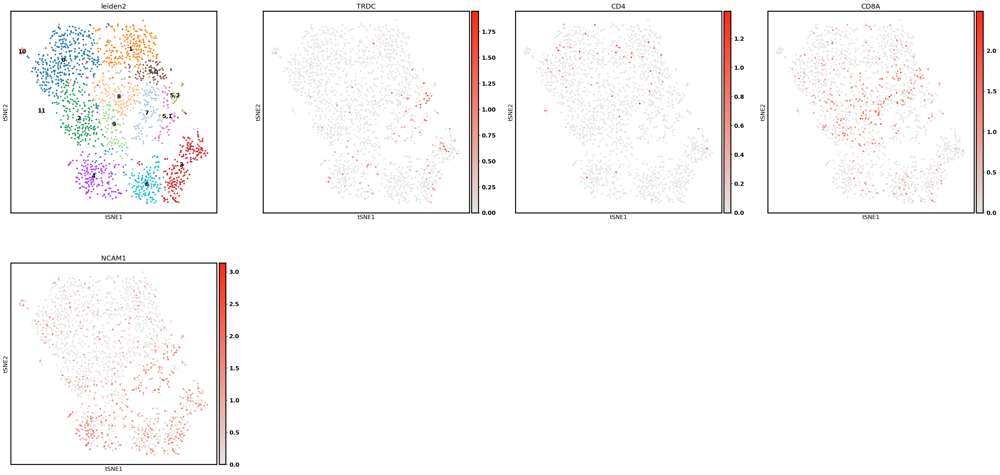

In [ ]:
plt.rcParams['figure.figsize'] = [8,8]
sc.tl.leiden(subclustering, restrict_to = ('leiden', ['5']), resolution = 0.5, key_added= 'leiden2')
sc.pl.tsne(subclustering, color=['leiden2','TRDC','CD4','CD8A','NCAM1'], size = 50, legend_loc = 'on data', cmap = my_cmap)
#go back to the DE section to make sure this subcluster make sense

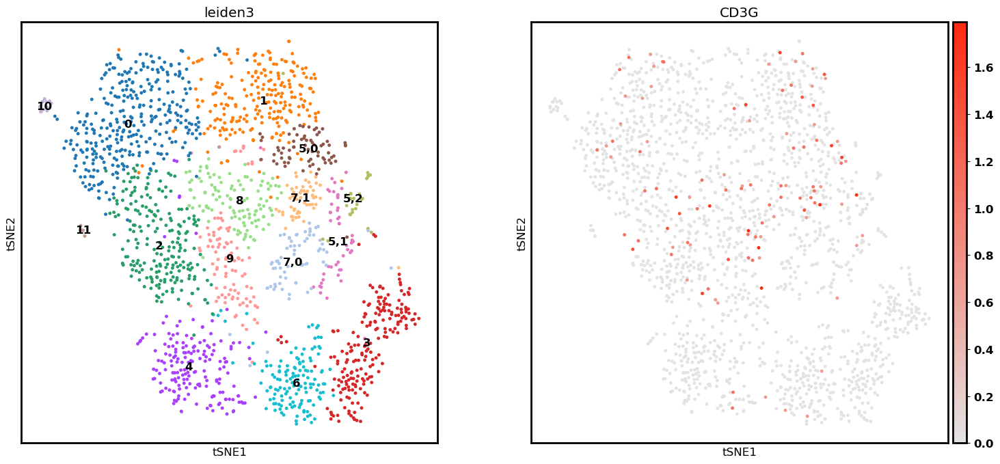

In [ ]:
plt.rcParams['figure.figsize'] = [8,8]
sc.tl.leiden(subclustering, restrict_to = ('leiden2', ['7']), resolution = 0.2, key_added= 'leiden3')
sc.pl.tsne(subclustering, color=['leiden3','CD3G'], size = 50, legend_loc = 'on data', cmap = my_cmap)
#go back to the DE section to make sure this subcluster make sense

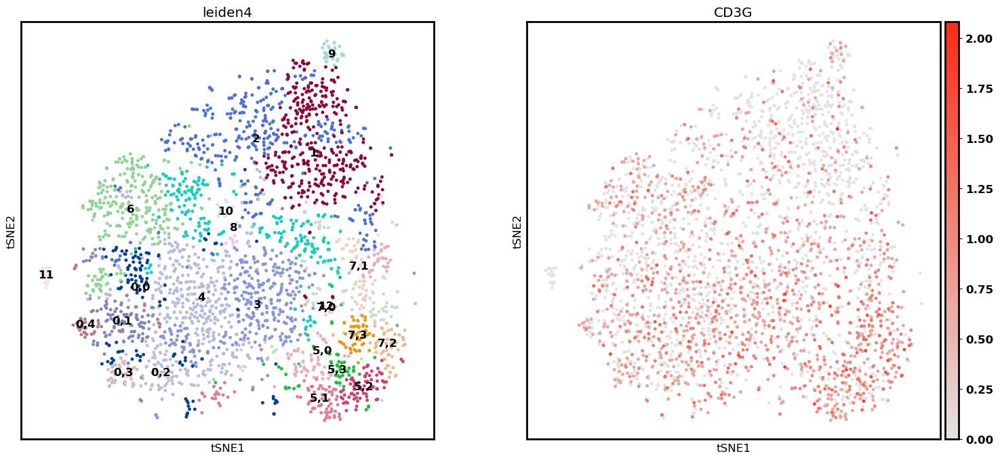

In [ ]:
plt.rcParams['figure.figsize'] = [8,8]
sc.tl.leiden(subclustering, restrict_to = ('leiden3', ['7']), resolution = 0.4, key_added= 'leiden4')
sc.pl.tsne(subclustering, color=['leiden4','CD3G'], size = 50, legend_loc = 'on data', cmap = my_cmap)
#go back to the DE section to make sure this subcluster make sense

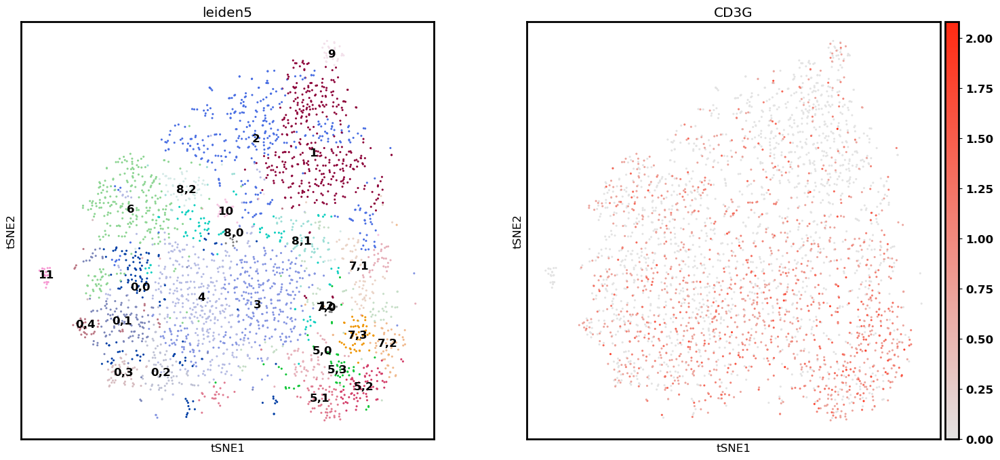

In [ ]:
plt.rcParams['figure.figsize'] = [8,8]
sc.tl.leiden(subclustering, restrict_to = ('leiden4', ['8']), resolution = 0.3, key_added= 'leiden5')
sc.pl.tsne(subclustering, color=['leiden5','CD3G'], size = 20, legend_loc = 'on data', cmap = my_cmap)
#go back to the DE section to make sure this subcluster make sense

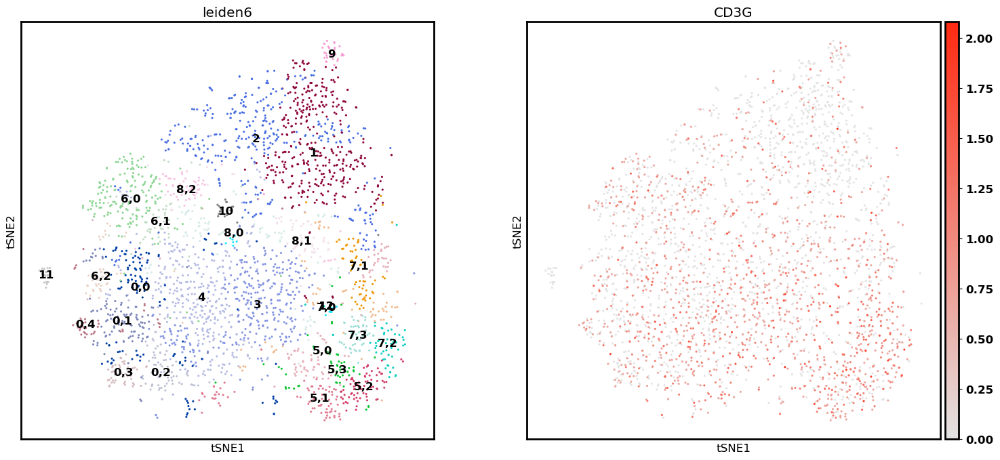

In [ ]:
plt.rcParams['figure.figsize'] = [8,8]
sc.tl.leiden(subclustering, restrict_to = ('leiden5', ['6']), resolution = 0.3, key_added= 'leiden6')
sc.pl.tsne(subclustering, color=['leiden6','CD3G'], size = 20, legend_loc = 'on data', cmap = my_cmap)
#go back to the DE section to make sure this subcluster make sense

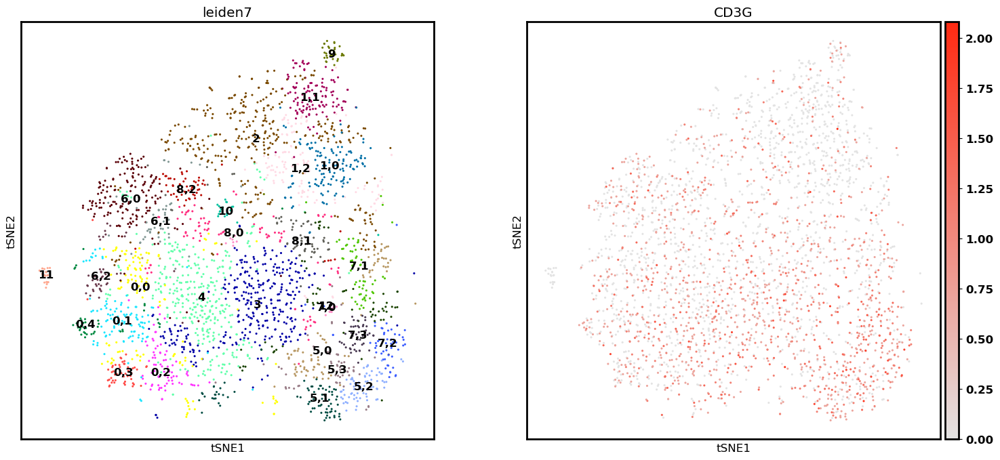

In [ ]:
plt.rcParams['figure.figsize'] = [8,8]
sc.tl.leiden(subclustering, restrict_to = ('leiden6', ['1']), resolution = 0.45, key_added= 'leiden7')
sc.pl.tsne(subclustering, color=['leiden7','CD3G'], size = 20, legend_loc = 'on data', cmap = my_cmap)
#go back to the DE section to make sure this subcluster make sense

In [ ]:
subclustering.obs['cluster_blind'] = subclustering.obs.groupby('leiden3').ngroup().astype('str')

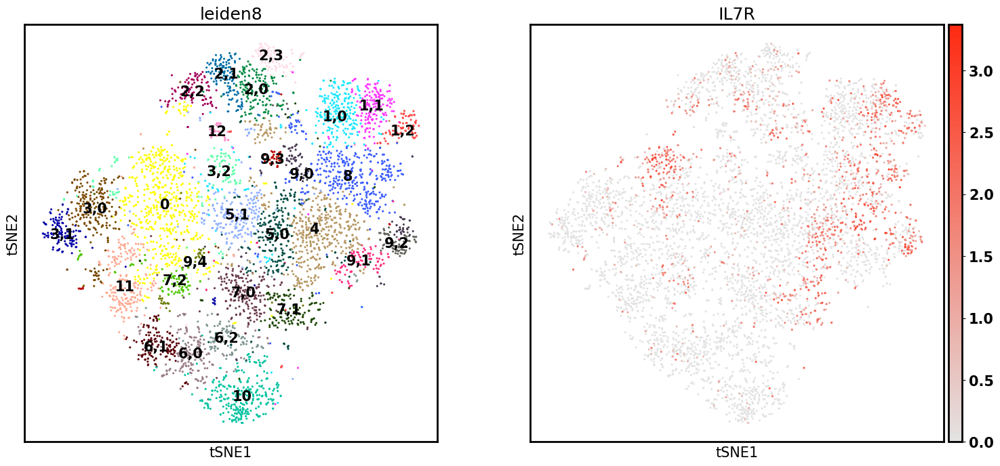

In [ ]:
plt.rcParams['figure.figsize'] = [8,8]
sc.tl.leiden(subclustering, restrict_to = ('leiden7', ['9']), resolution = 0.5, key_added= 'leiden8')
sc.pl.tsne(subclustering, color=['leiden8','IL7R'], size = 20, legend_loc = 'on data', cmap = my_cmap)
#go back to the DE section to make sure this subcluster make sense

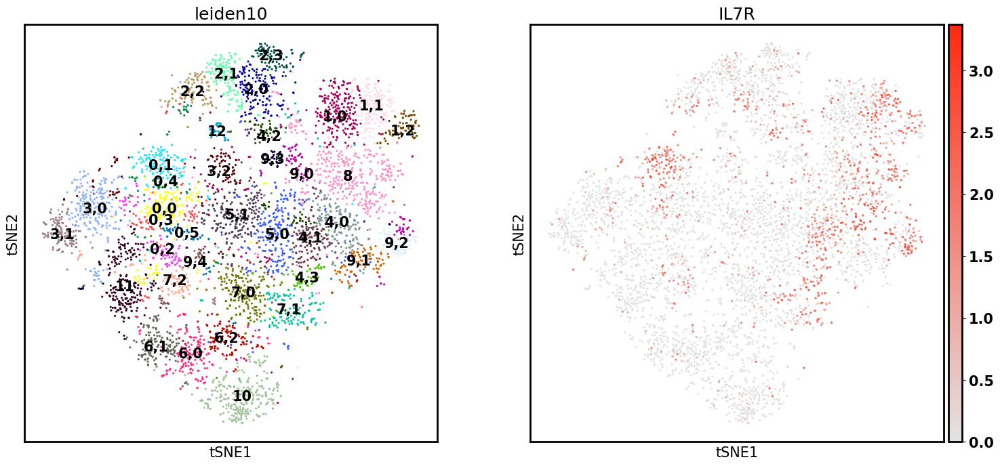

In [ ]:
plt.rcParams['figure.figsize'] = [8,8]
sc.tl.leiden(subclustering, restrict_to = ('leiden9', ['4']), resolution = 0.6, key_added= 'leiden10')
sc.pl.tsne(subclustering, color=['leiden10','IL7R'], size = 20, legend_loc = 'on data', cmap = my_cmap)
#go back to the DE section to make sure this subcluster make sense

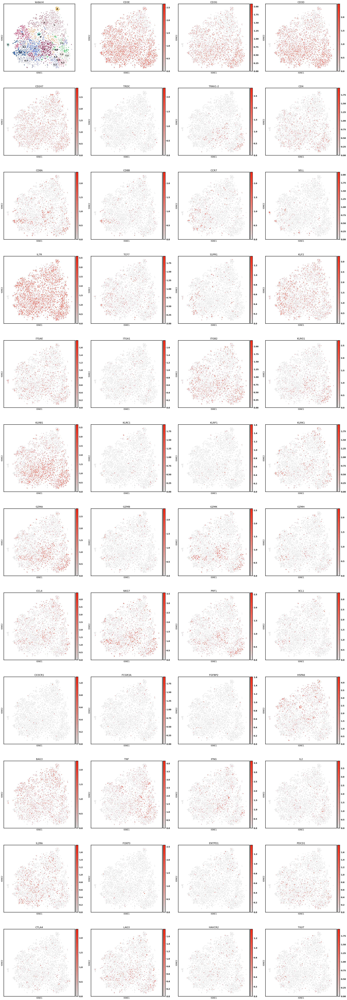

In [ ]:
sc.pl.tsne(subclustering, color = ['leiden4','CD3E','CD3G','CD3D','CD247','TRDC','TRAV1-2','CD4','CD8A','CD8B','CCR7','SELL','IL7R','TCF7','S1PR1','KLF2',
                    'ITGAE','ITGA1','ITGB2','KLRG1','KLRB1','KLRC1','KLRF1','KLRK1','GZMA','GZMB','GZMK','GZMH','CCL4','NKG7','PRF1',
                         'XCL1','CX3CR1','FCGR3A','FGFBP2','HSPA6','BAG3','TNF','IFNG','IL2','IL2RA','FOXP3','ENTPD1','PDCD1','CTLA4','LAG3','HAVCR2','TIGIT'],
           cmap = my_cmap,legend_loc = 'on data',size = 50)

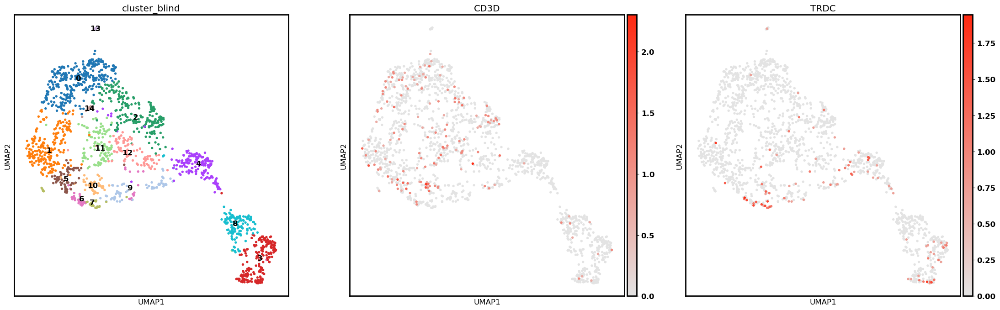

In [ ]:
sc.pl.umap(subclustering, color=['cluster_blind','CD3D','TRDC'], size = 60, legend_loc = 'on data', cmap = my_cmap)

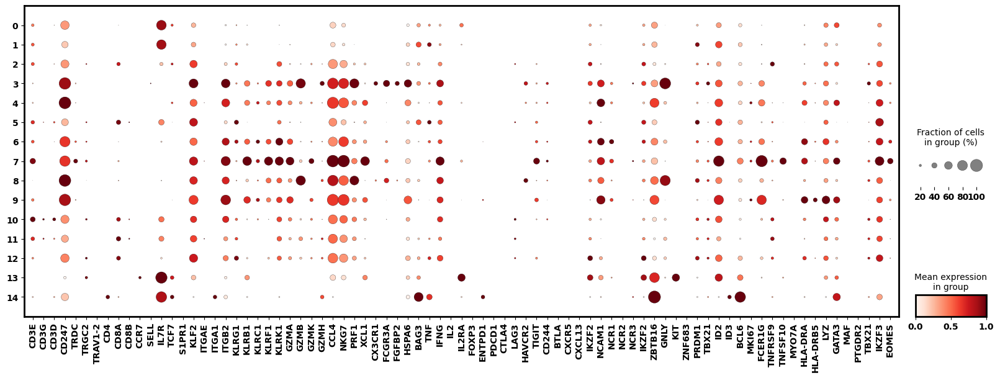

In [ ]:
plt.rcParams.update({'font.size': 12, 'font.weight': 'heavy','axes.linewidth':2})
#plt.rcParams.update(plt.rcParamsDefault)

gene_list = ['CD3E','CD3G','CD3D','CD247','TRDC','TRGC2','TRAV1-2','CD4','CD8A','CD8B','CCR7','SELL','IL7R','TCF7','S1PR1','KLF2',
                    'ITGAE','ITGA1','ITGB2','KLRG1','KLRB1','KLRC1','KLRF1','KLRK1','GZMA','GZMB','GZMK','GZMH','CCL4','NKG7','PRF1',
                         'XCL1','CX3CR1','FCGR3A','FGFBP2','HSPA6','BAG3','TNF','IFNG','IL2','IL2RA','FOXP3','ENTPD1','PDCD1','CTLA4','LAG3','HAVCR2','TIGIT',
             'CD244','BTLA','CXCR5','CXCL13','IKZF2','NCAM1','NCR1','NCR2','NCR3','IKZF2','ZBTB16',
             'GNLY','KIT','ZNF683','PRDM1','TBX21','ID2','ID3','BCL6','MKI67','FCER1G','TNFRSF9','TNFSF10','MYO7A','HLA-DRA','HLA-DRB5','LYZ','GATA3','MAF','PTGDR2','TBX21','IKZF3','EOMES']
sc.pl.dotplot(subclustering,gene_list,groupby = 'cluster_blind' , vmax = 1, 
              swap_axes = False ,dot_min = 0.1,standard_scale = 'var',figsize = (20,6.5))

In [ ]:
subclustering.obs['cell type'] = subclustering.obs['cluster_blind']
subclustering.obs['cell type'] = subclustering.obs['cell type'].astype('str')

NK = np.array([3,4,6,7,8,9])
NK = [str(i) for i in NK]

ILC1 = np.array([2,5,10,11,12])
ILC1 = [str(i) for i in ILC1]

ILC3 = np.array([0,1,13,14])
ILC3 = [str(i) for i in ILC3]

for c_id in set(subclustering.obs['cluster_blind']):
    if c_id in NK:
        subclustering.obs = subclustering.obs.replace({'cell type' : { c_id: 'NK'}})
    if c_id in ILC1:
        subclustering.obs = subclustering.obs.replace({'cell type' : { c_id: 'ILC1-like Cells'}})
    if c_id in ILC3:
        subclustering.obs = subclustering.obs.replace({'cell type' : { c_id: 'KIT- ILC3-like Cells'}})

subclustering.obs['cell type'] = subclustering.obs['cell type'].astype('category')

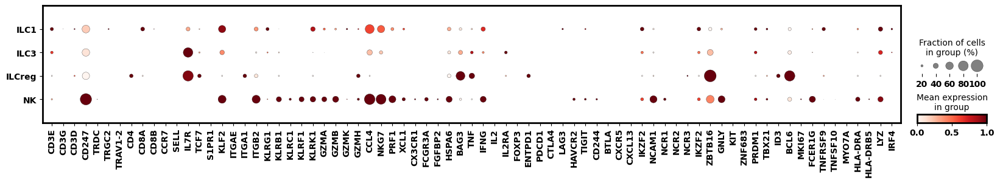

In [ ]:
plt.rcParams.update({'font.size': 12, 'font.weight': 'heavy','axes.linewidth':2})
#plt.rcParams.update(plt.rcParamsDefault)

gene_list = ['CD3E','CD3G','CD3D','CD247','TRDC','TRGC2','TRAV1-2','CD4','CD8A','CD8B','CCR7','SELL','IL7R','TCF7','S1PR1','KLF2',
                    'ITGAE','ITGA1','ITGB2','KLRG1','KLRB1','KLRC1','KLRF1','KLRK1','GZMA','GZMB','GZMK','GZMH','CCL4','NKG7','PRF1',
                         'XCL1','CX3CR1','FCGR3A','FGFBP2','HSPA6','BAG3','TNF','IFNG','IL2','IL2RA','FOXP3','ENTPD1','PDCD1','CTLA4','LAG3','HAVCR2','TIGIT',
             'CD244','BTLA','CXCR5','CXCL13','IKZF2','NCAM1','NCR1','NCR2','NCR3','IKZF2','ZBTB16',
             'GNLY','KIT','ZNF683','PRDM1','TBX21','ID3','BCL6','MKI67','FCER1G','TNFRSF9','TNFSF10','MYO7A','HLA-DRA','HLA-DRB5','LYZ','IRF4']
sc.pl.dotplot(subclustering,gene_list,groupby = 'cell type' , vmax = 1, 
              swap_axes = False ,dot_min = 0.1,standard_scale = 'var',figsize = (20,2.5))

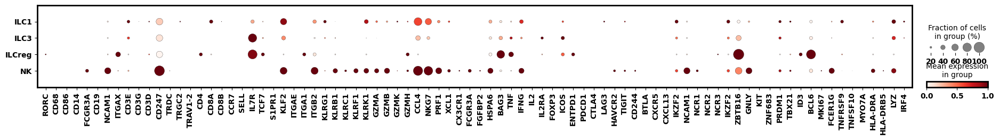

In [ ]:
plt.rcParams.update({'font.size': 12, 'font.weight': 'heavy','axes.linewidth':2})
#plt.rcParams.update(plt.rcParamsDefault)

gene_list = ['RORC','CD68','CD86','CD14','FCGR3A','CD19','NCAM1','ITGAX','CD3E','CD3G','CD3D','CD247','TRDC','TRGC2','TRAV1-2','CD4','CD8A','CD8B','CCR7','SELL','IL7R','TCF7','S1PR1','KLF2',
                    'ITGAE','ITGA1','ITGB2','KLRG1','KLRB1','KLRC1','KLRF1','KLRK1','GZMA','GZMB','GZMK','GZMH','CCL4','NKG7','PRF1',
                         'XCL1','CX3CR1','FCGR3A','FGFBP2','HSPA6','BAG3','TNF','IFNG','IL2','IL2RA','FOXP3','ICOS','ENTPD1','PDCD1','CTLA4','LAG3','HAVCR2','TIGIT',
             'CD244','BTLA','CXCR5','CXCL13','IKZF2','NCAM1','NCR1','NCR2','NCR3','IKZF2','ZBTB16',
             'GNLY','KIT','ZNF683','PRDM1','TBX21','ID3','BCL6','MKI67','FCER1G','TNFRSF9','TNFSF10','MYO7A','HLA-DRA','HLA-DRB5','LYZ','IRF4']
sc.pl.dotplot(subclustering,gene_list,groupby = 'cell type' , vmax = 1, 
              swap_axes = False ,dot_min = 0.1,standard_scale = 'var',figsize = (23,2))

In [ ]:
subclustering.obs['T type'] = ''
subclustering.obs['T type'] = subclustering.obs['T type'].astype('category')

In [ ]:
subclustering.obs['Detailed Cell Type'] = subclustering.obs['T type'].astype(str).map(str) + ' ' +subclustering.obs['cell type'].astype(str).map(str)

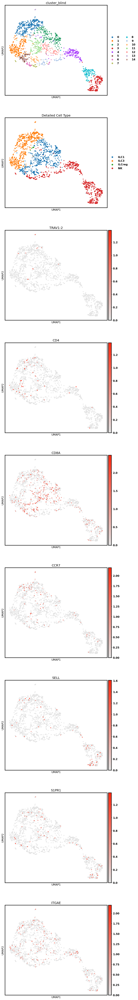

In [ ]:
sc.pl.umap(subclustering, color=['cluster_blind','Detailed Cell Type','TRAV1-2','CD4','CD8A','CCR7','SELL','S1PR1','ITGAE'], ncols = 1, size = 60, cmap = my_cmap)

In [ ]:
subclustering.write('cluster4.h5ad')

In [ ]:
subclustering = sc.read_h5ad('cluster4.h5ad')

In [ ]:
df_4 = subclustering.obs[['cell type','T type','Detailed Cell Type']]

### Cluster 1

In [ ]:
subclustering = adata[adata.obs['leiden'].isin(['1']),:]

In [ ]:
subclustering =subclustering[:,~np.isnan(subclustering.X.A).any(axis=0)]

In [ ]:
del subclustering.uns

In [ ]:
sc.pp.neighbors(subclustering, n_neighbors = 15, n_pcs = 50)
sc.tl.leiden(subclustering, resolution = 0.9, key_added= 'leiden')                                                 

In [ ]:
sc.tl.tsne(subclustering)

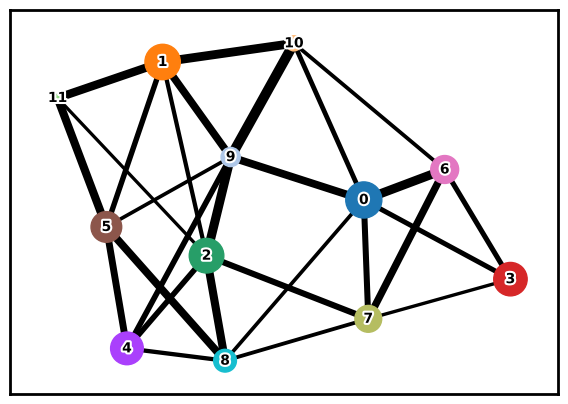

In [ ]:
sc.tl.paga(subclustering, groups='leiden')
sc.pl.paga(subclustering,threshold = 0.3, labels=None, fontsize = 10, fontoutline = 3,node_size_scale = 3,node_size_power = 1,random_state = 0)
sc.tl.umap(subclustering, min_dist = 0.001, spread = 1.5,init_pos = 'paga')

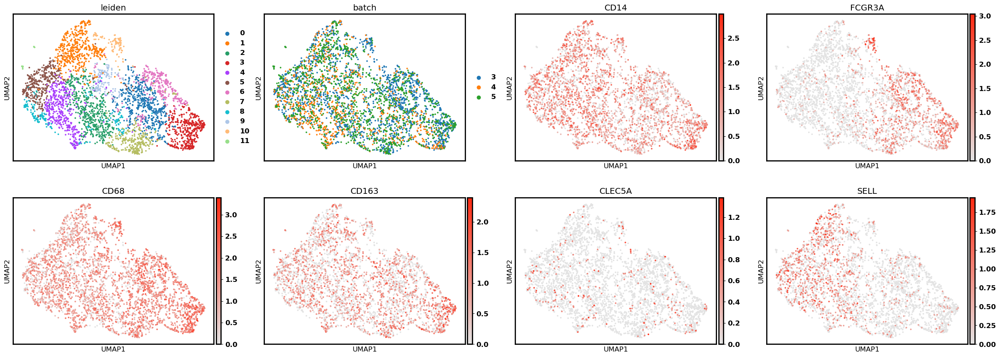

In [ ]:
sc.pl.umap(subclustering, color = ['leiden','batch','CD14','FCGR3A','CD68','CD163','CLEC5A','SELL'],cmap = my_cmap)

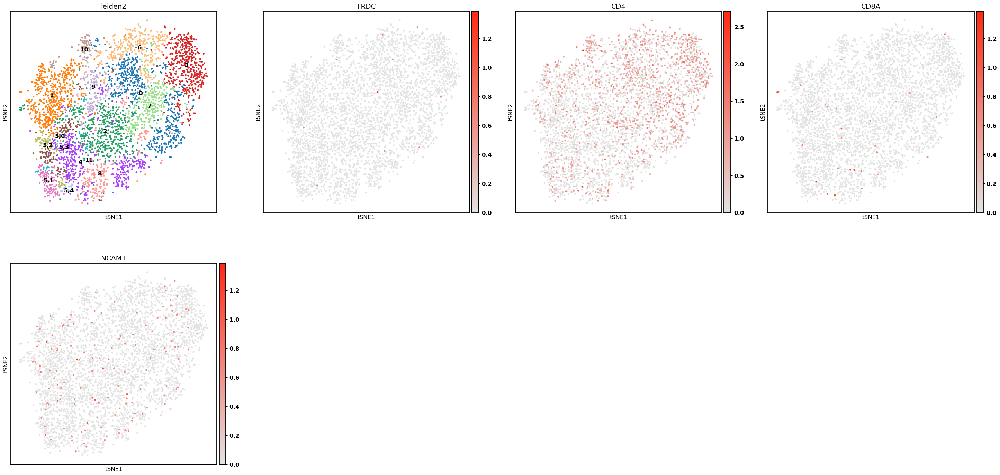

In [ ]:
plt.rcParams['figure.figsize'] = [8,8]
sc.tl.leiden(subclustering, restrict_to = ('leiden', ['5']), resolution = 0.5, key_added= 'leiden2')
sc.pl.tsne(subclustering, color=['leiden2','TRDC','CD4','CD8A','NCAM1'], size = 50, legend_loc = 'on data', cmap = my_cmap)
#go back to the DE section to make sure this subcluster make sense

In [ ]:
subclustering.obs['cluster_blind'] = subclustering.obs.groupby('leiden').ngroup().astype('str')

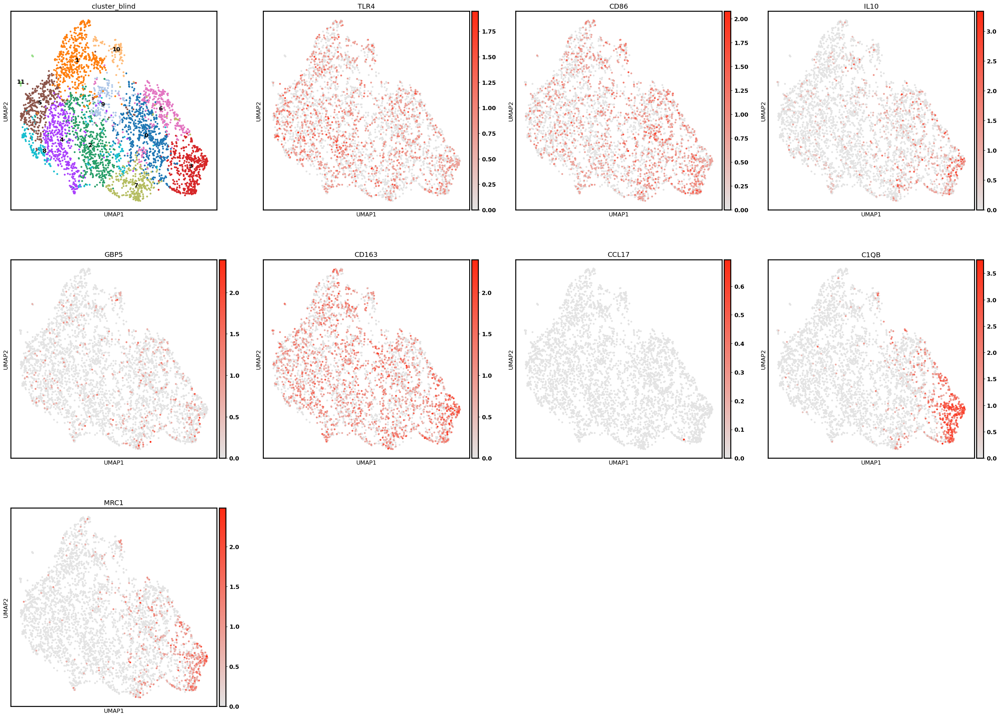

In [ ]:
sc.pl.umap(subclustering, color=['cluster_blind','TLR4','CD86','IL10','GBP5','CD163','CCL17','C1QB','MRC1'], size = 60, legend_loc = 'on data', cmap = my_cmap)

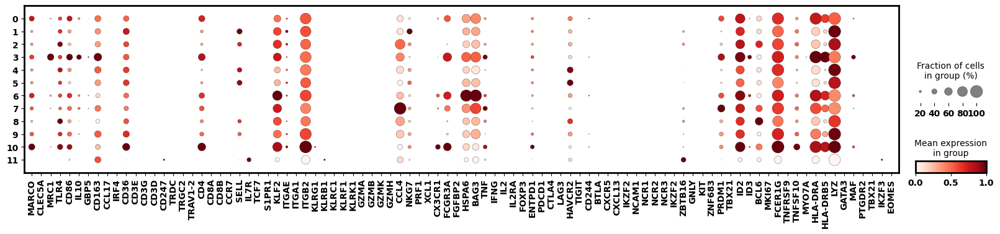

In [ ]:
plt.rcParams.update({'font.size': 12, 'font.weight': 'heavy','axes.linewidth':2})
#plt.rcParams.update(plt.rcParamsDefault)

gene_list = ['MARCO','CLEC5A','MRC1','TLR4','CD86','IL10','GBP5','CD163','CCL17','IRF4','CD36','CD3E','CD3G','CD3D','CD247','TRDC','TRGC2','TRAV1-2','CD4','CD8A','CD8B','CCR7','SELL','IL7R','TCF7','S1PR1','KLF2',
                    'ITGAE','ITGA1','ITGB2','KLRG1','KLRB1','KLRC1','KLRF1','KLRK1','GZMA','GZMB','GZMK','GZMH','CCL4','NKG7','PRF1',
                         'XCL1','CX3CR1','FCGR3A','FGFBP2','HSPA6','BAG3','TNF','IFNG','IL2','IL2RA','FOXP3','ENTPD1','PDCD1','CTLA4','LAG3','HAVCR2','TIGIT',
             'CD244','BTLA','CXCR5','CXCL13','IKZF2','NCAM1','NCR1','NCR2','NCR3','IKZF2','ZBTB16',
             'GNLY','KIT','ZNF683','PRDM1','TBX21','ID2','ID3','BCL6','MKI67','FCER1G','TNFRSF9','TNFSF10','MYO7A','HLA-DRA','HLA-DRB5','LYZ','GATA3','MAF','PTGDR2','TBX21','IKZF3','EOMES']
sc.pl.dotplot(subclustering,gene_list,groupby = 'leiden' , vmax = 1, 
              swap_axes = False ,dot_min = 0.1,standard_scale = 'var',figsize = (20,3.5))

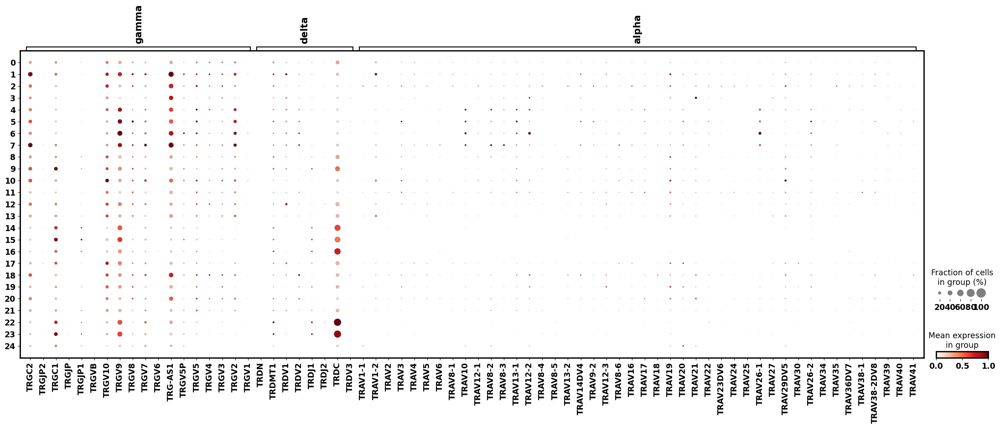

In [ ]:
plt.rcParams.update({'font.size': 15, 'font.weight': 'heavy','axes.linewidth':2})
#plt.rcParams.update(plt.rcParamsDefault)
gamma_genesmask = [gene.startswith("TRG") for gene in subclustering.var_names]
gamma_genes = subclustering.var_names[gamma_genesmask]
delta_genesmask = [gene.startswith("TRD") for gene in subclustering.var_names]
delta_genes = subclustering.var_names[delta_genesmask]
alpha_genesmask = [gene.startswith("TRAV") for gene in subclustering.var_names]
alpha_genes = subclustering.var_names[alpha_genesmask]
TCR_exp_set ={
"gamma": gamma_genes, "delta": delta_genes, "alpha": alpha_genes
}



sc.pl.dotplot(subclustering,TCR_exp_set,groupby = 'cluster_blind' , vmax = 1, swap_axes = False, dot_min =0, dot_max =1,standard_scale = 'var')

In [ ]:
subclustering.obs['cell type'] = subclustering.obs['leiden']
subclustering.obs['cell type'] = subclustering.obs['cell type'].astype('str')

M1 = np.array([0,6,7,10,11])
M1 = [str(i) for i in M1]

for c_id in set(subclustering.obs['cluster_blind']):
    if c_id in M1:
        subclustering.obs = subclustering.obs.replace({'cell type' : { c_id: 'M1-like CD16+ Macrophage'}})
    if c_id in ['3']:
        subclustering.obs = subclustering.obs.replace({'cell type' : { c_id: 'M2-like CD16+ Macrophage'}})
    else:
        subclustering.obs = subclustering.obs.replace({'cell type' : { c_id: 'CD16- Macrophage'}})

subclustering.obs['cell type'] = subclustering.obs['cell type'].astype('category')

In [ ]:
subclustering.obs['T type'] = ''
subclustering.obs['T type'] = subclustering.obs['T type'].astype('category')

In [ ]:
subclustering.obs['Detailed Cell Type'] = subclustering.obs['T type'].astype(str).map(str) + ' ' +subclustering.obs['cell type'].astype(str).map(str)

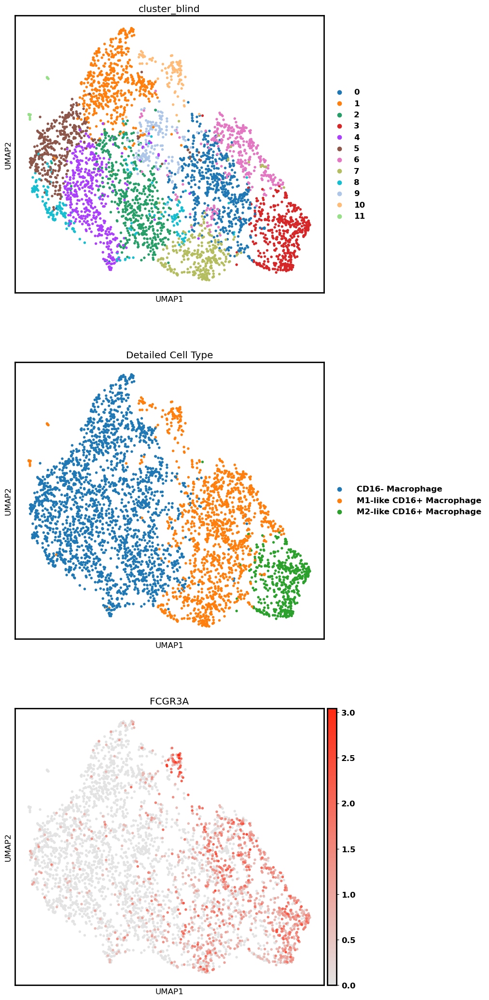

In [ ]:
sc.pl.umap(subclustering, color=['cluster_blind','Detailed Cell Type','FCGR3A'], ncols = 1, size = 60, cmap = my_cmap)

In [ ]:
subclustering.write('cluster1.h5ad')

In [ ]:
subclustering = sc.read_h5ad('cluster1.h5ad')

In [ ]:
df_1 = subclustering.obs[['cell type','T type','Detailed Cell Type']]

In [ ]:
df_1

,cell type,T type,Detailed Cell Type
AAACCTGAGCGATATA-1-3,M1-like CD16+ Macrophage,,M1-like CD16+ Macrophage
AAACCTGCAGAGCCAA-1-3,CD16- Macrophage,,CD16- Macrophage
AAACCTGTCGTTACAG-1-3,CD16- Macrophage,,CD16- Macrophage
AAACGGGCAACTGGCC-1-3,CD16- Macrophage,,CD16- Macrophage
AAACGGGGTATGCTTG-1-3,CD16- Macrophage,,CD16- Macrophage
...,...,...,...
TTTGTCAAGACATAAC-1-5,CD16- Macrophage,,CD16- Macrophage
TTTGTCACAATCGGTT-1-5,M1-like CD16+ Macrophage,,M1-like CD16+ Macrophage
TTTGTCACAGTCTTCC-1-5,M1-like CD16+ Macrophage,,M1-like CD16+ Macrophage
TTTGTCACATGCAACT-1-5,M2-like CD16+ Macrophage,,M2-like CD16+ Macrophage


### Cluster 3

In [ ]:
subclustering = adata[adata.obs['leiden'].isin(['3']),:]

In [ ]:
subclustering =subclustering[:,~np.isnan(subclustering.X.A).any(axis=0)]

In [ ]:
del subclustering.uns

In [ ]:
sc.pp.neighbors(subclustering, n_neighbors = 15, n_pcs = 50)
sc.tl.leiden(subclustering, resolution = 1, key_added= 'leiden')                                                 

In [ ]:
sc.tl.tsne(subclustering)

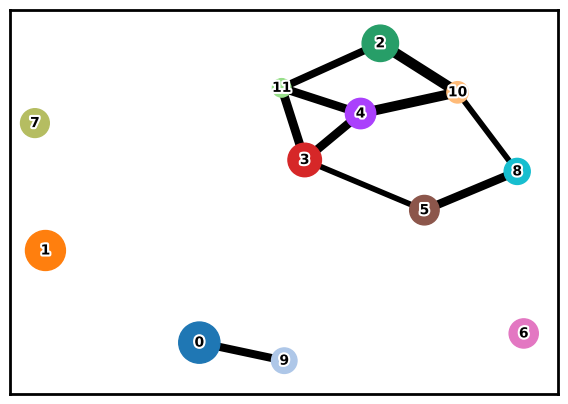

In [ ]:
sc.tl.paga(subclustering, groups='leiden')
sc.pl.paga(subclustering,threshold = 0.5, labels=None, fontsize = 10, fontoutline = 3,node_size_scale = 3,node_size_power = 1,random_state = 0)
sc.tl.umap(subclustering, min_dist = 0.001, spread = 1.5,init_pos = 'paga')

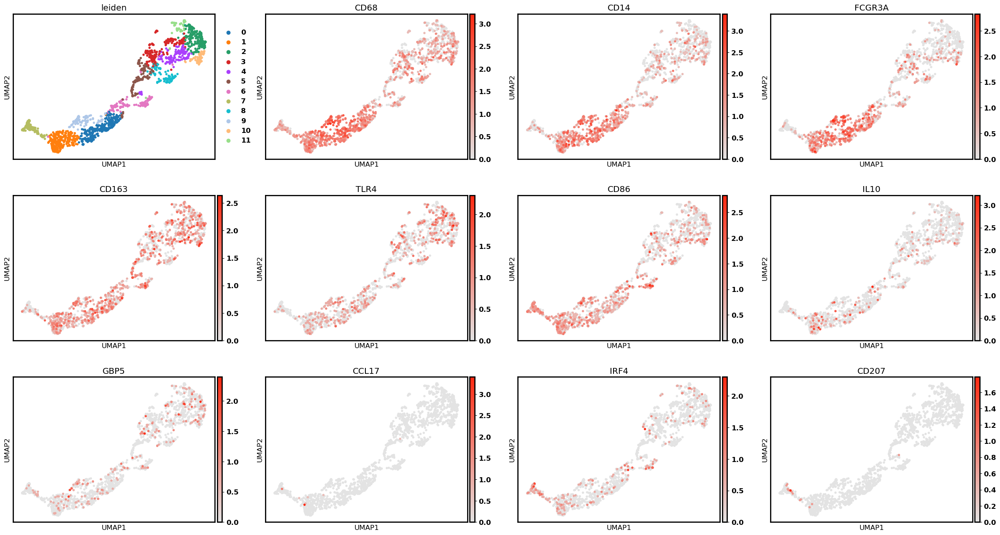

In [ ]:
sc.pl.umap(subclustering, color = ['leiden','CD68','CD14','FCGR3A','CD163','TLR4','CD86','IL10','GBP5','CCL17','IRF4','CD207',],cmap = my_cmap)

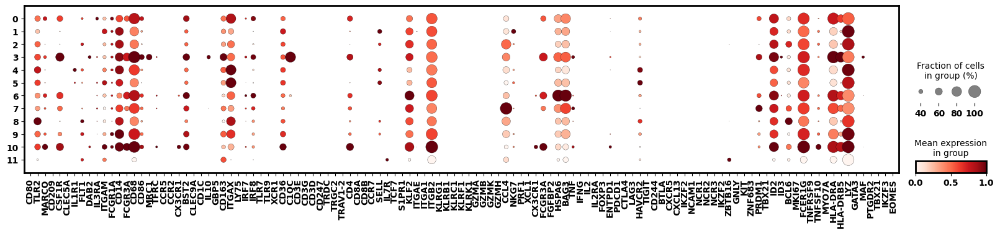

In [ ]:
plt.rcParams.update({'font.size': 12, 'font.weight': 'heavy','axes.linewidth':2})
#plt.rcParams.update(plt.rcParamsDefault)

gene_list = ['CD80','TLR2','MARCO','CD209','CSF1R','CLEC5A','IL1R1','FLT1','DAB2','IL3RA','ITGAM','FCGR1A','CD14','FCGR3A','CD68','CD86','MRC1','TFRC','CCR5','CCR2','CX3CR1','BST2','CLEC9A','CD1C','IL10','GBP5','CD163','ITGAX','LY75','IRF7','IRF8','TLR7','TLR9','XCR1','CD36','C1QC','CD3E','CD3G','CD3D','CD247','TRDC','TRGC2','TRAV1-2','CD4','CD8A','CD8B','CCR7','SELL','IL7R','TCF7','S1PR1','KLF2',
                    'ITGAE','ITGA1','ITGB2','KLRG1','KLRB1','KLRC1','KLRF1','KLRK1','GZMA','GZMB','GZMK','GZMH','CCL4','NKG7','PRF1',
                         'XCL1','CX3CR1','FCGR3A','FGFBP2','HSPA6','BAG3','TNF','IFNG','IL2','IL2RA','FOXP3','ENTPD1','PDCD1','CTLA4','LAG3','HAVCR2','TIGIT',
             'CD244','BTLA','CXCR5','CXCL13','IKZF2','NCAM1','NCR1','NCR2','NCR3','IKZF2','ZBTB16',
             'GNLY','KIT','ZNF683','PRDM1','TBX21','ID2','ID3','BCL6','MKI67','FCER1G','TNFRSF9','TNFSF10','MYO7A','HLA-DRA','HLA-DRB5','LYZ','GATA3','MAF','PTGDR2','TBX21','IKZF3','EOMES']
sc.pl.dotplot(subclustering,gene_list,groupby = 'leiden' , vmax = 1, 
              swap_axes = False ,dot_min = 0.2,standard_scale = 'var',figsize = (20,3.5))

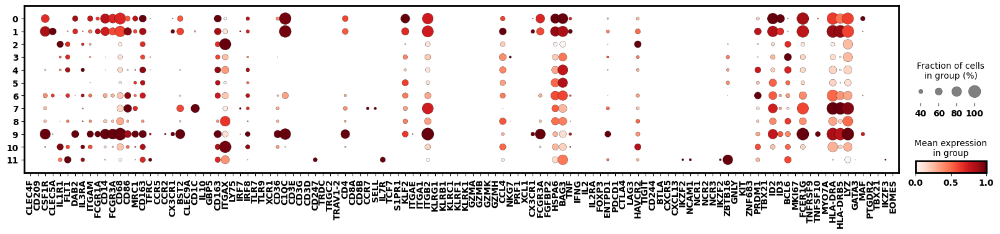

In [ ]:
plt.rcParams.update({'font.size': 12, 'font.weight': 'heavy','axes.linewidth':2})
#plt.rcParams.update(plt.rcParamsDefault)

gene_list = ['CLEC4F','CD209','CSF1R','CLEC5A','IL1R1','FLT1','DAB2','IL3RA','ITGAM','FCGR1A','CD14','FCGR3A','CD68','CD86','MRC1','CD163','TFRC','CCR5','CCR2','CX3CR1','BST2','CLEC9A','CD1C','IL10','GBP5','CD163','ITGAX','LY75','IRF7','IRF8','TLR7','TLR9','XCR1','CD36','C1QC','CD3E','CD3G','CD3D','CD247','TRDC','TRGC2','TRAV1-2','CD4','CD8A','CD8B','CCR7','SELL','IL7R','TCF7','S1PR1','KLF2',
                    'ITGAE','ITGA1','ITGB2','KLRG1','KLRB1','KLRC1','KLRF1','KLRK1','GZMA','GZMB','GZMK','GZMH','CCL4','NKG7','PRF1',
                         'XCL1','CX3CR1','FCGR3A','FGFBP2','HSPA6','BAG3','TNF','IFNG','IL2','IL2RA','FOXP3','ENTPD1','PDCD1','CTLA4','LAG3','HAVCR2','TIGIT',
             'CD244','BTLA','CXCR5','CXCL13','IKZF2','NCAM1','NCR1','NCR2','NCR3','IKZF2','ZBTB16',
             'GNLY','KIT','ZNF683','PRDM1','TBX21','ID2','ID3','BCL6','MKI67','FCER1G','TNFRSF9','TNFSF10','MYO7A','HLA-DRA','HLA-DRB5','LYZ','GATA3','MAF','PTGDR2','TBX21','IKZF3','EOMES']
sc.pl.dotplot(subclustering,gene_list,groupby = 'leiden' , vmax = 1, 
              swap_axes = False ,dot_min = 0.2,standard_scale = 'var',figsize = (20,3.5))

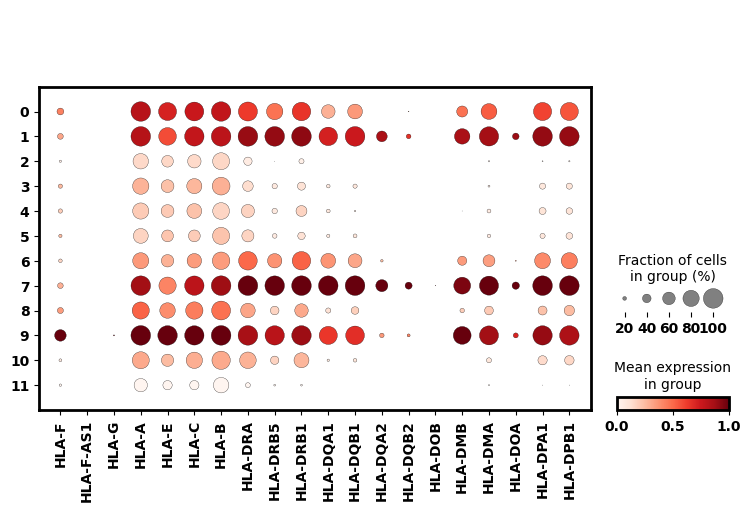

In [ ]:
# plt.rcParams.update({'font.size': 15, 'font.weight': 'heavy','axes.linewidth':2})
#plt.rcParams.update(plt.rcParamsDefault)
gamma_genesmask = [gene.startswith("HLA") for gene in subclustering.var_names]
gamma_genes = subclustering.var_names[gamma_genesmask]

sc.pl.dotplot(subclustering,gamma_genes,groupby = 'leiden' , vmax = 1, swap_axes = False, dot_min =0.1, dot_max =1,standard_scale = 'var')

In [ ]:
subclustering.obs['cell type'] = subclustering.obs['leiden']
subclustering.obs['cell type'] = subclustering.obs['cell type'].astype('str')

NK = np.array([11])
NK = [str(i) for i in NK]

Macrophage = np.array([0,1,6,9])
Macrophage = [str(i) for i in Macrophage]

pDC = ['7']


for c_id in set(subclustering.obs['leiden']):
    if c_id in NK:
        subclustering.obs = subclustering.obs.replace({'cell type' : { c_id: 'NK'}})
    if c_id in Macrophage:
        subclustering.obs = subclustering.obs.replace({'cell type' : { c_id: 'M2-like CD16+ Macrophage'}})
    if c_id in pDC:
        subclustering.obs = subclustering.obs.replace({'cell type' : { c_id: 'pDC'}})
    else:
        subclustering.obs = subclustering.obs.replace({'cell type' : { c_id: 'Immature DC'}})

subclustering.obs['cell type'] = subclustering.obs['cell type'].astype('category')

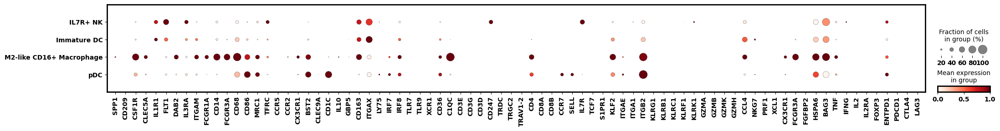

In [ ]:
# plt.rcParams.update({'font.size': 12, 'font.weight': 'heavy','axes.linewidth':2})
#plt.rcParams.update(plt.rcParamsDefault)

gene_list = ['SPP1','CD209','CSF1R','CLEC5A','IL1R1','FLT1','DAB2','IL3RA','ITGAM','FCGR1A','CD14','FCGR3A','CD68','CD86','MRC1','TFRC','CCR5','CCR2','CX3CR1','BST2','CLEC9A','CD1C','IL10','GBP5','CD163','ITGAX','LY75','IRF7','IRF8','TLR7','TLR9','XCR1','CD36','C1QC','CD3E','CD3G','CD3D','CD247','TRDC','TRGC2','TRAV1-2','CD4','CD8A','CD8B','CCR7','SELL','IL7R','TCF7','S1PR1','KLF2',
                    'ITGAE','ITGA1','ITGB2','KLRG1','KLRB1','KLRC1','KLRF1','KLRK1','GZMA','GZMB','GZMK','GZMH','CCL4','NKG7','PRF1',
                         'XCL1','CX3CR1','FCGR3A','FGFBP2','HSPA6','BAG3','TNF','IFNG','IL2','IL2RA','FOXP3','ENTPD1','PDCD1','CTLA4','LAG3']
sc.pl.dotplot(subclustering,gene_list,groupby = 'cell type' , vmax = 1, 
              swap_axes = False ,dot_min = 0.1,standard_scale = 'var',figsize = (25,2.5))

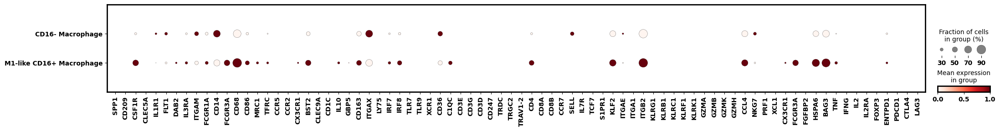

In [ ]:
# plt.rcParams.update({'font.size': 12, 'font.weight': 'heavy','axes.linewidth':2})
#plt.rcParams.update(plt.rcParamsDefault)

gene_list = ['SPP1','CD209','CSF1R','CLEC5A','IL1R1','FLT1','DAB2','IL3RA','ITGAM','FCGR1A','CD14','FCGR3A','CD68','CD86','MRC1','TFRC','CCR5','CCR2','CX3CR1','BST2','CLEC9A','CD1C','IL10','GBP5','CD163','ITGAX','LY75','IRF7','IRF8','TLR7','TLR9','XCR1','CD36','C1QC','CD3E','CD3G','CD3D','CD247','TRDC','TRGC2','TRAV1-2','CD4','CD8A','CD8B','CCR7','SELL','IL7R','TCF7','S1PR1','KLF2',
                    'ITGAE','ITGA1','ITGB2','KLRG1','KLRB1','KLRC1','KLRF1','KLRK1','GZMA','GZMB','GZMK','GZMH','CCL4','NKG7','PRF1',
                         'XCL1','CX3CR1','FCGR3A','FGFBP2','HSPA6','BAG3','TNF','IFNG','IL2','IL2RA','FOXP3','ENTPD1','PDCD1','CTLA4','LAG3']
sc.pl.dotplot(subclustering,gene_list,groupby = 'cell type' , vmax = 1, 
              swap_axes = False ,dot_min = 0.1,standard_scale = 'var',figsize = (25,2.5))

In [ ]:
subclustering.obs['T type'] = ''
subclustering.obs['T type'] = subclustering.obs['T type'].astype('category')

In [ ]:
subclustering.obs['Detailed Cell Type'] = subclustering.obs['T type'].astype(str).map(str) + ' ' +subclustering.obs['cell type'].astype(str).map(str)

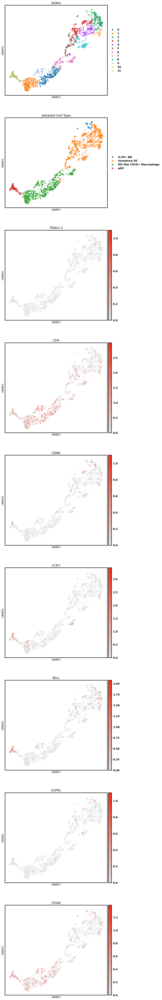

In [ ]:
sc.pl.umap(subclustering, color=['leiden','Detailed Cell Type','TRAV1-2','CD4','CD8A','CCR7','SELL','S1PR1','ITGAE'], ncols = 1, size = 60, cmap = my_cmap)

In [ ]:
subclustering.write('cluster3.h5ad')

In [ ]:
subclustering = sc.read_h5ad('cluster3.h5ad')

In [ ]:
df_3 = subclustering.obs[['cell type','T type','Detailed Cell Type']]

### Cluster 5

In [ ]:
subclustering = adata[adata.obs['leiden'].isin(['5']),:]

In [ ]:
subclustering =subclustering[:,~np.isnan(subclustering.X.A).any(axis=0)]

In [ ]:
del subclustering.uns

In [ ]:
sc.pp.neighbors(subclustering, n_neighbors = 15, n_pcs = 50)
sc.tl.leiden(subclustering, resolution = 1, key_added= 'leiden')                                                 

In [ ]:
sc.tl.tsne(subclustering)

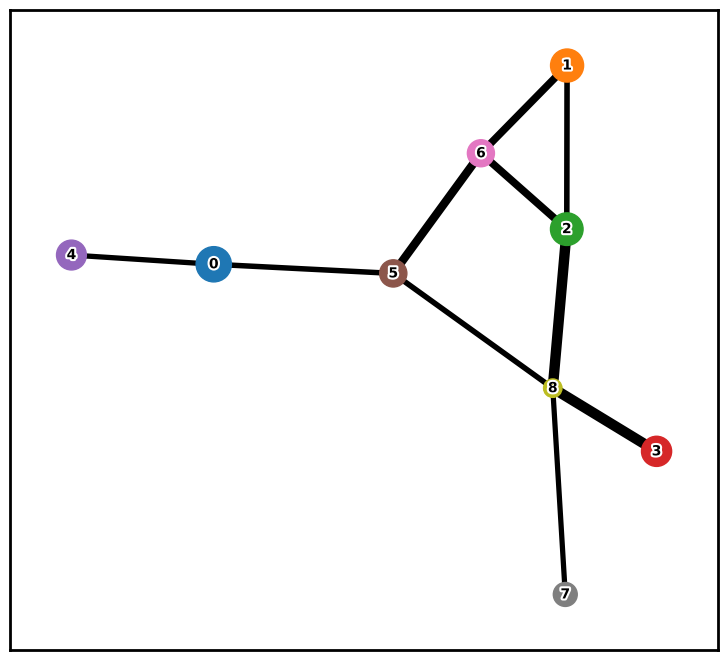

In [ ]:
sc.tl.paga(subclustering, groups='leiden')
sc.pl.paga(subclustering,threshold = 0.5, labels=None, fontsize = 10, fontoutline = 3,node_size_scale = 3,node_size_power = 1,random_state = 0)
sc.tl.umap(subclustering, min_dist = 0.001, spread = 1.5,init_pos = 'paga')

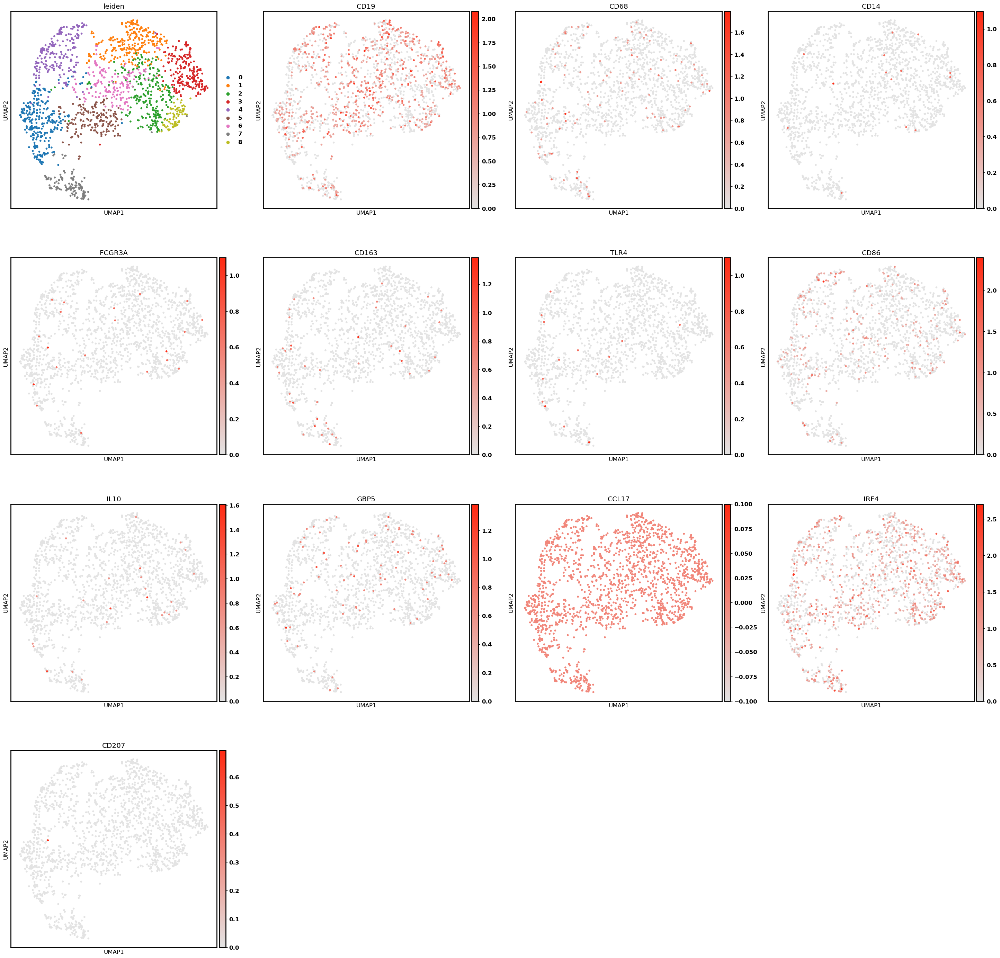

In [ ]:
sc.pl.umap(subclustering, color = ['leiden','CD19','CD68','CD14','FCGR3A','CD163','TLR4','CD86','IL10','GBP5','CCL17','IRF4','CD207',],cmap = my_cmap)

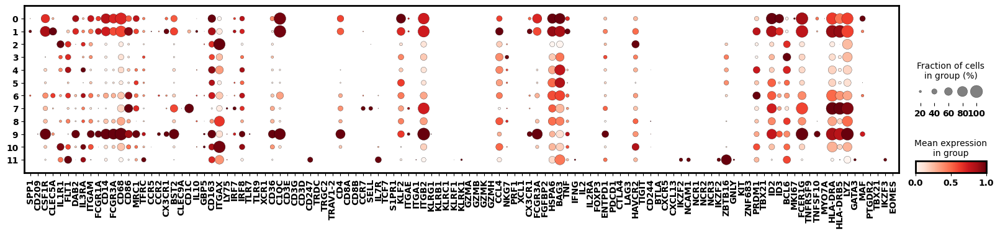

In [ ]:
plt.rcParams.update({'font.size': 12, 'font.weight': 'heavy','axes.linewidth':2})
#plt.rcParams.update(plt.rcParamsDefault)

gene_list = ['SPP1','CD209','CSF1R','CLEC5A','IL1R1','FLT1','DAB2','IL3RA','ITGAM','FCGR1A','CD14','FCGR3A','CD68','CD86','MRC1','TFRC','CCR5','CCR2','CX3CR1','BST2','CLEC9A','CD1C','IL10','GBP5','CD163','ITGAX','LY75','IRF7','IRF8','TLR7','TLR9','XCR1','CD36','C1QC','CD3E','CD3G','CD3D','CD247','TRDC','TRGC2','TRAV1-2','CD4','CD8A','CD8B','CCR7','SELL','IL7R','TCF7','S1PR1','KLF2',
                    'ITGAE','ITGA1','ITGB2','KLRG1','KLRB1','KLRC1','KLRF1','KLRK1','GZMA','GZMB','GZMK','GZMH','CCL4','NKG7','PRF1',
                         'XCL1','CX3CR1','FCGR3A','FGFBP2','HSPA6','BAG3','TNF','IFNG','IL2','IL2RA','FOXP3','ENTPD1','PDCD1','CTLA4','LAG3','HAVCR2','TIGIT',
             'CD244','BTLA','CXCR5','CXCL13','IKZF2','NCAM1','NCR1','NCR2','NCR3','IKZF2','ZBTB16',
             'GNLY','KIT','ZNF683','PRDM1','TBX21','ID2','ID3','BCL6','MKI67','FCER1G','TNFRSF9','TNFSF10','MYO7A','HLA-DRA','HLA-DRB5','LYZ','GATA3','MAF','PTGDR2','TBX21','IKZF3','EOMES']
sc.pl.dotplot(subclustering,gene_list,groupby = 'leiden' , vmax = 1, 
              swap_axes = False ,dot_min = 0.1,standard_scale = 'var',figsize = (20,3.5))

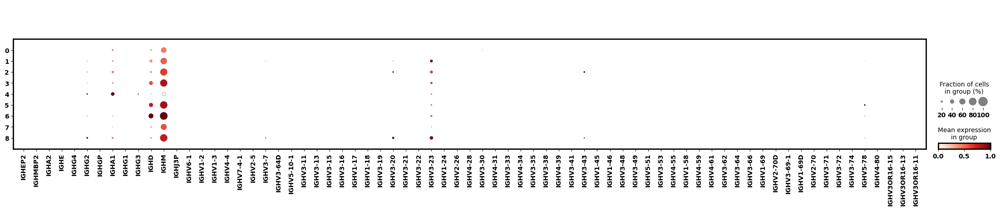

In [ ]:
# plt.rcParams.update({'font.size': 15, 'font.weight': 'heavy','axes.linewidth':2})
#plt.rcParams.update(plt.rcParamsDefault)
gamma_genesmask = [gene.startswith("IGH") for gene in subclustering.var_names]
gamma_genes = subclustering.var_names[gamma_genesmask]

sc.pl.dotplot(subclustering,gamma_genes,groupby = 'leiden' , vmax = 1, swap_axes = False, dot_min =0.1, dot_max =1,standard_scale = 'var')

In [ ]:
subclustering.obs['cell type'] = subclustering.obs['leiden']
subclustering.obs['cell type'] = subclustering.obs['cell type'].astype('str')

IgAp = ['4']
IgM = ['7','8']


for c_id in set(subclustering.obs['leiden']):
    if c_id in IgAp:
        subclustering.obs = subclustering.obs.replace({'cell type' : { c_id: 'Plasma'}})
    if c_id in IgM:
        subclustering.obs = subclustering.obs.replace({'cell type' : { c_id: 'IgM Naive B'}})
    else:
        subclustering.obs = subclustering.obs.replace({'cell type' : { c_id: 'IgD IgM Naive B'}})

subclustering.obs['cell type'] = subclustering.obs['cell type'].astype('category')

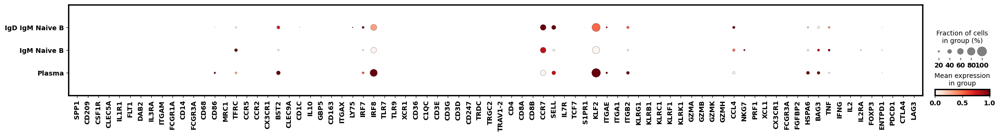

In [ ]:
# plt.rcParams.update({'font.size': 12, 'font.weight': 'heavy','axes.linewidth':2})
#plt.rcParams.update(plt.rcParamsDefault)

gene_list = ['SPP1','CD209','CSF1R','CLEC5A','IL1R1','FLT1','DAB2','IL3RA','ITGAM','FCGR1A','CD14','FCGR3A','CD68','CD86','MRC1','TFRC','CCR5','CCR2','CX3CR1','BST2','CLEC9A','CD1C','IL10','GBP5','CD163','ITGAX','LY75','IRF7','IRF8','TLR7','TLR9','XCR1','CD36','C1QC','CD3E','CD3G','CD3D','CD247','TRDC','TRGC2','TRAV1-2','CD4','CD8A','CD8B','CCR7','SELL','IL7R','TCF7','S1PR1','KLF2',
                    'ITGAE','ITGA1','ITGB2','KLRG1','KLRB1','KLRC1','KLRF1','KLRK1','GZMA','GZMB','GZMK','GZMH','CCL4','NKG7','PRF1',
                         'XCL1','CX3CR1','FCGR3A','FGFBP2','HSPA6','BAG3','TNF','IFNG','IL2','IL2RA','FOXP3','ENTPD1','PDCD1','CTLA4','LAG3']
sc.pl.dotplot(subclustering,gene_list,groupby = 'cell type' , vmax = 1, 
              swap_axes = False ,dot_min = 0.1,standard_scale = 'var',figsize = (25,2.5))

In [ ]:
subclustering.obs['T type'] = ''
subclustering.obs['T type'] = subclustering.obs['T type'].astype('category')

In [ ]:
subclustering.obs['Detailed Cell Type'] = subclustering.obs['T type'].astype(str).map(str) + ' ' +subclustering.obs['cell type'].astype(str).map(str)

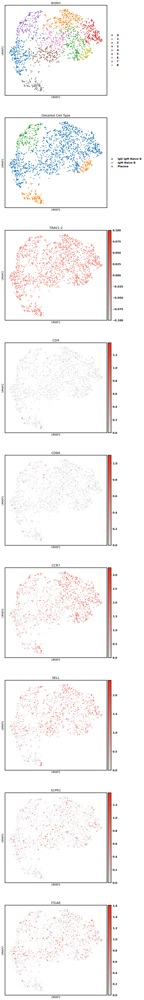

In [ ]:
sc.pl.umap(subclustering, color=['leiden','Detailed Cell Type','TRAV1-2','CD4','CD8A','CCR7','SELL','S1PR1','ITGAE'], ncols = 1, size = 60, cmap = my_cmap)

In [ ]:
subclustering.write('cluster5.h5ad')

In [ ]:
subclustering = sc.read_h5ad('cluster5.h5ad')

In [ ]:
df_5 = subclustering.obs[['cell type','T type','Detailed Cell Type']]

In [ ]:
df_5

,cell type,T type,Detailed Cell Type
AAACGGGTCACTGGGC-1-3,IgD IgM Naive B,,IgD IgM Naive B
AAAGATGGTAAGCACG-1-3,IgD IgM Naive B,,IgD IgM Naive B
AAAGCAATCCTTCAAT-1-3,IgD IgM Naive B,,IgD IgM Naive B
AAAGTAGGTGATGATA-1-3,IgD IgM Naive B,,IgD IgM Naive B
AAAGTAGGTGTAACGG-1-3,IgD IgM Naive B,,IgD IgM Naive B
...,...,...,...
TTGTAGGCACAAGTAA-1-5,IgD IgM Naive B,,IgD IgM Naive B
TTTCCTCGTCAGAATA-1-5,IgD IgM Naive B,,IgD IgM Naive B
TTTGCGCAGAACAATC-1-5,IgD IgM Naive B,,IgD IgM Naive B
TTTGCGCGTTCCCTTG-1-5,IgD IgM Naive B,,IgD IgM Naive B


### Cluster 6 (That's relatively pure NK)

In [ ]:
subclustering = adata[adata.obs['leiden'].isin(['6']),:]

In [ ]:
subclustering =subclustering[:,~np.isnan(subclustering.X.A).any(axis=0)]

In [ ]:
del subclustering.uns

In [ ]:
sc.pp.neighbors(subclustering, n_neighbors = 15, n_pcs = 50)
sc.tl.leiden(subclustering, resolution = 1, key_added= 'leiden')                                                 

In [ ]:
sc.tl.tsne(subclustering)

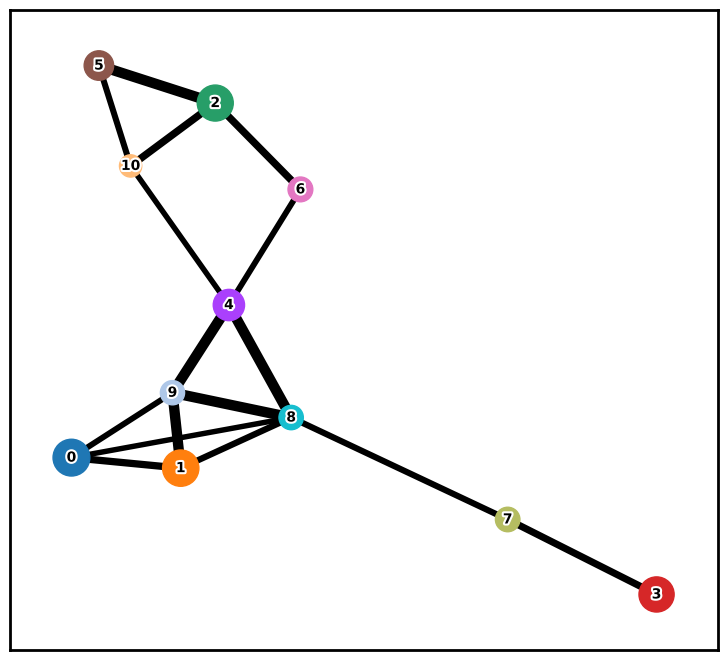

In [ ]:
sc.tl.paga(subclustering, groups='leiden')
sc.pl.paga(subclustering,threshold = 0.5, labels=None, fontsize = 10, fontoutline = 3,node_size_scale = 3,node_size_power = 1,random_state = 0)
sc.tl.umap(subclustering, min_dist = 0.001, spread = 1.5,init_pos = 'paga')

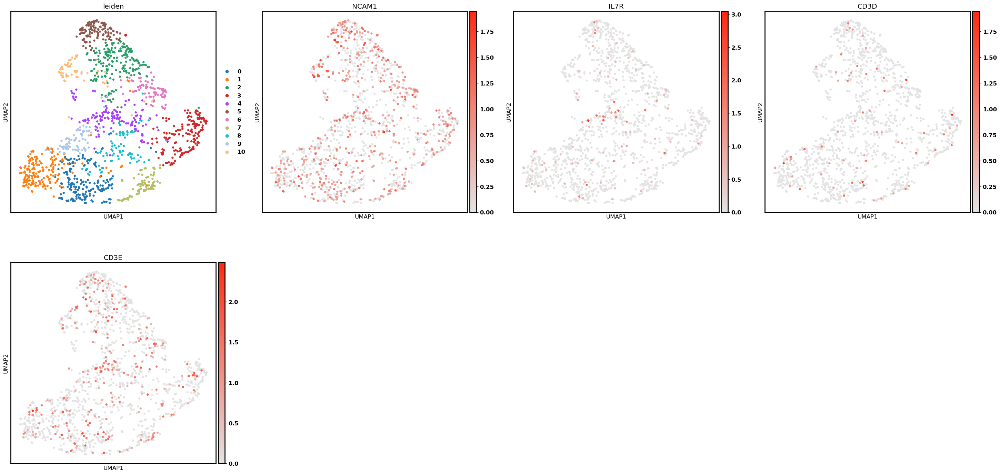

In [ ]:
sc.pl.umap(subclustering, color = ['leiden','NCAM1','IL7R','CD3D','CD3E'],cmap = my_cmap)

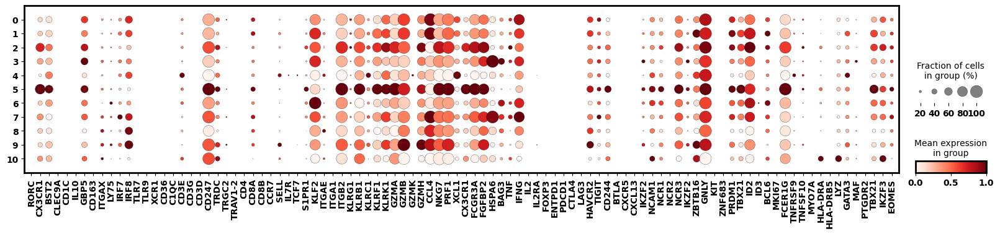

In [ ]:
plt.rcParams.update({'font.size': 12, 'font.weight': 'heavy','axes.linewidth':2})
#plt.rcParams.update(plt.rcParamsDefault)

gene_list = ['RORC','CX3CR1','BST2','CLEC9A','CD1C','IL10','GBP5','CD163','ITGAX','LY75','IRF7','IRF8','TLR7','TLR9','XCR1','CD36','C1QC','CD3E','CD3G','CD3D','CD247','TRDC','TRGC2','TRAV1-2','CD4','CD8A','CD8B','CCR7','SELL','IL7R','TCF7','S1PR1','KLF2',
                    'ITGAE','ITGA1','ITGB2','KLRG1','KLRB1','KLRC1','KLRF1','KLRK1','GZMA','GZMB','GZMK','GZMH','CCL4','NKG7','PRF1',
                         'XCL1','CX3CR1','FCGR3A','FGFBP2','HSPA6','BAG3','TNF','IFNG','IL2','IL2RA','FOXP3','ENTPD1','PDCD1','CTLA4','LAG3','HAVCR2','TIGIT',
             'CD244','BTLA','CXCR5','CXCL13','IKZF2','NCAM1','NCR1','NCR2','NCR3','IKZF2','ZBTB16',
             'GNLY','KIT','ZNF683','PRDM1','TBX21','ID2','ID3','BCL6','MKI67','FCER1G','TNFRSF9','TNFSF10','MYO7A','HLA-DRA','HLA-DRB5','LYZ','GATA3','MAF','PTGDR2','TBX21','IKZF3','EOMES']
sc.pl.dotplot(subclustering,gene_list,groupby = 'leiden' , vmax = 1, 
              swap_axes = False ,dot_min = 0.1,standard_scale = 'var',figsize = (20,3.5))

In [ ]:
subclustering.write('cluster3.h5ad')

### Cluster 9

In [ ]:
subclustering = adata[adata.obs['leiden'].isin(['9']),:]

In [ ]:
subclustering =subclustering[:,~np.isnan(subclustering.X.A).any(axis=0)]

In [ ]:
del subclustering.uns

In [ ]:
sc.pp.neighbors(subclustering, n_neighbors = 15, n_pcs = 50)
sc.tl.leiden(subclustering, resolution = 1, key_added= 'leiden')                                                 

In [ ]:
sc.tl.tsne(subclustering)

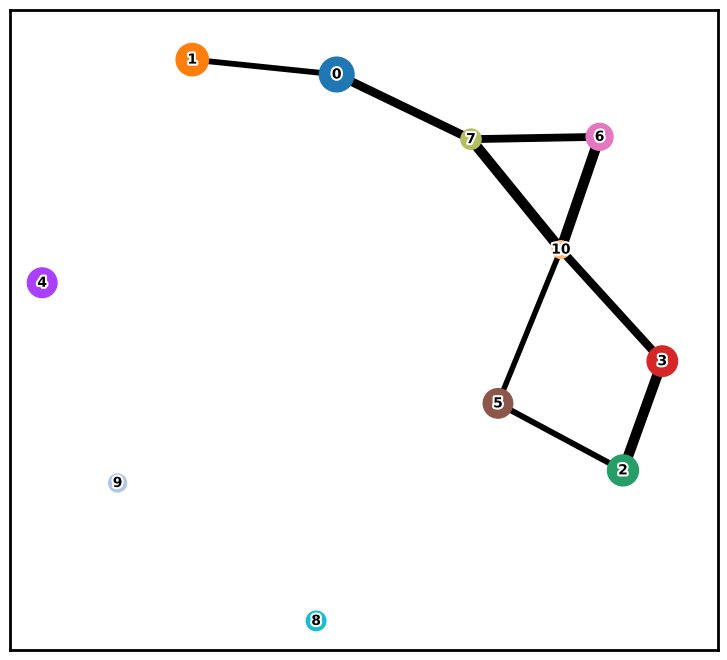

In [ ]:
sc.tl.paga(subclustering, groups='leiden')
sc.pl.paga(subclustering,threshold = 0.5, labels=None, fontsize = 10, fontoutline = 3,node_size_scale = 3,node_size_power = 1,random_state = 0)
sc.tl.umap(subclustering, min_dist = 0.001, spread = 1.5,init_pos = 'paga')

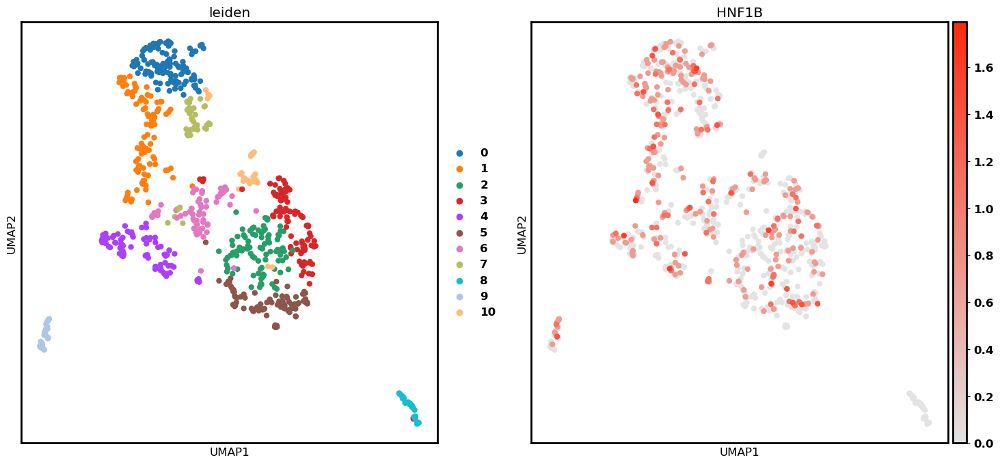

In [ ]:
sc.pl.umap(subclustering, color = ['leiden','HNF1B'],cmap = my_cmap)

In [ ]:
sum(subclustering.obs['leiden'] == '8')

39

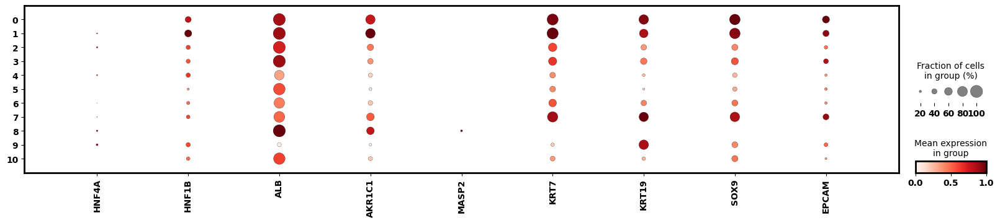

In [ ]:
plt.rcParams.update({'font.size': 12, 'font.weight': 'heavy','axes.linewidth':2})
#plt.rcParams.update(plt.rcParamsDefault)

gene_list = ['HNF4A','HNF1B','ALB','AKR1C1','MASP2',
                      'KRT7','KRT19','SOX9','EPCAM']

sc.pl.dotplot(subclustering,gene_list,groupby = 'leiden' , vmax = 1, 
              swap_axes = False ,dot_min = 0.1,standard_scale = 'var',figsize = (20,3.5))

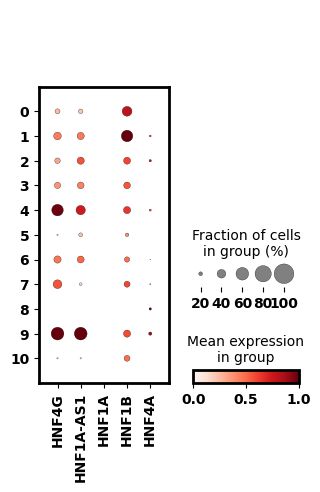

In [ ]:
# plt.rcParams.update({'font.size': 15, 'font.weight': 'heavy','axes.linewidth':2})
#plt.rcParams.update(plt.rcParamsDefault)
gamma_genesmask = [gene.startswith("HNF") for gene in subclustering.var_names]
gamma_genes = subclustering.var_names[gamma_genesmask]

sc.pl.dotplot(subclustering,gamma_genes,groupby = 'leiden' , vmax = 1, swap_axes = False, dot_min =0.1, dot_max =1,standard_scale = 'var')

In [ ]:
subclustering.obs['cell type'] = subclustering.obs['leiden']
subclustering.obs['cell type'] = subclustering.obs['cell type'].astype('str')

HEP = np.array([8])
HEP = [str(i) for i in HEP]

for c_id in set(subclustering.obs['leiden']):
    if c_id in HEP:
        subclustering.obs = subclustering.obs.replace({'cell type' : { c_id: 'Hepatocytes Type 6'}})
    else:
        subclustering.obs = subclustering.obs.replace({'cell type' : { c_id: 'Cholangiocytes'}})

subclustering.obs['cell type'] = subclustering.obs['cell type'].astype('category')

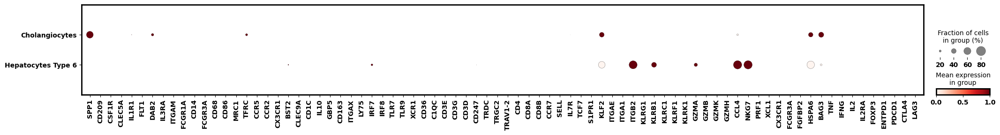

In [ ]:
# plt.rcParams.update({'font.size': 12, 'font.weight': 'heavy','axes.linewidth':2})
#plt.rcParams.update(plt.rcParamsDefault)

gene_list = ['SPP1','CD209','CSF1R','CLEC5A','IL1R1','FLT1','DAB2','IL3RA','ITGAM','FCGR1A','CD14','FCGR3A','CD68','CD86','MRC1','TFRC','CCR5','CCR2','CX3CR1','BST2','CLEC9A','CD1C','IL10','GBP5','CD163','ITGAX','LY75','IRF7','IRF8','TLR7','TLR9','XCR1','CD36','C1QC','CD3E','CD3G','CD3D','CD247','TRDC','TRGC2','TRAV1-2','CD4','CD8A','CD8B','CCR7','SELL','IL7R','TCF7','S1PR1','KLF2',
                    'ITGAE','ITGA1','ITGB2','KLRG1','KLRB1','KLRC1','KLRF1','KLRK1','GZMA','GZMB','GZMK','GZMH','CCL4','NKG7','PRF1',
                         'XCL1','CX3CR1','FCGR3A','FGFBP2','HSPA6','BAG3','TNF','IFNG','IL2','IL2RA','FOXP3','ENTPD1','PDCD1','CTLA4','LAG3']
sc.pl.dotplot(subclustering,gene_list,groupby = 'cell type' , vmax = 1, 
              swap_axes = False ,dot_min = 0.1,standard_scale = 'var',figsize = (25,2.5))

In [ ]:
subclustering.obs['T type'] = ''
subclustering.obs['T type'] = subclustering.obs['T type'].astype('category')

In [ ]:
subclustering.obs['Detailed Cell Type'] = subclustering.obs['T type'].astype(str).map(str) + ' ' +subclustering.obs['cell type'].astype(str).map(str)

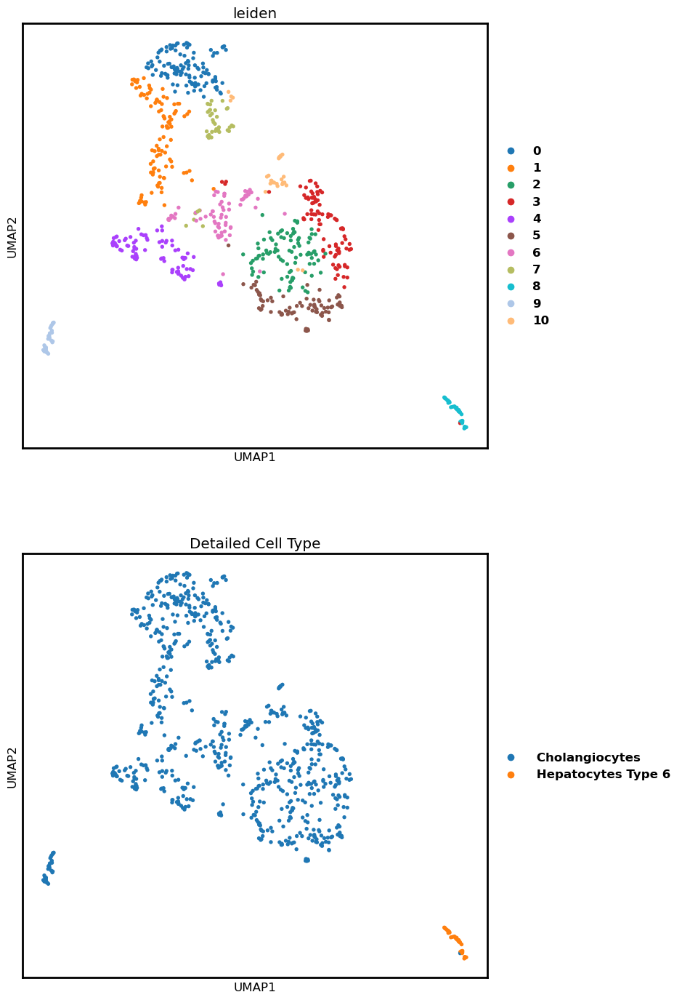

In [ ]:
sc.pl.umap(subclustering, color=['leiden','Detailed Cell Type'], ncols = 1, size = 60, cmap = my_cmap)

In [ ]:
subclustering.write('cluster9.h5ad')

In [ ]:
subclustering = sc.read_h5ad('cluster9.h5ad')

In [ ]:
df_9 = subclustering.obs[['cell type','T type','Detailed Cell Type']]

In [ ]:
df_9

,cell type,T type,Detailed Cell Type
AACTCAGGTTTCGCTC-1-3,Hepatocytes Type 6,,Hepatocytes Type 6
AACTTTCTCCATGCTC-1-3,Hepatocytes Type 6,,Hepatocytes Type 6
AAGTCTGTCGCCATAA-1-3,Cholangiocytes,,Cholangiocytes
ACACCCTTCTCGGACG-1-3,Hepatocytes Type 6,,Hepatocytes Type 6
ACACCCTTCTTGGGTA-1-3,Cholangiocytes,,Cholangiocytes
...,...,...,...
TTTCCTCTCCTTTCTC-1-5,Cholangiocytes,,Cholangiocytes
TTTGCGCCAAGTTCTG-1-5,Cholangiocytes,,Cholangiocytes
TTTGTCAAGTGACTCT-1-5,Cholangiocytes,,Cholangiocytes
TTTGTCACAAATACAG-1-5,Cholangiocytes,,Cholangiocytes


### Cluster 10

In [ ]:
subclustering = adata[adata.obs['leiden'].isin(['10']),:]

In [ ]:
subclustering =subclustering[:,~np.isnan(subclustering.X.A).any(axis=0)]

In [ ]:
del subclustering.uns

In [ ]:
sc.pp.neighbors(subclustering, n_neighbors = 15, n_pcs = 50)
sc.tl.leiden(subclustering, resolution = 1, key_added= 'leiden')                                                 

In [ ]:
sc.tl.tsne(subclustering)

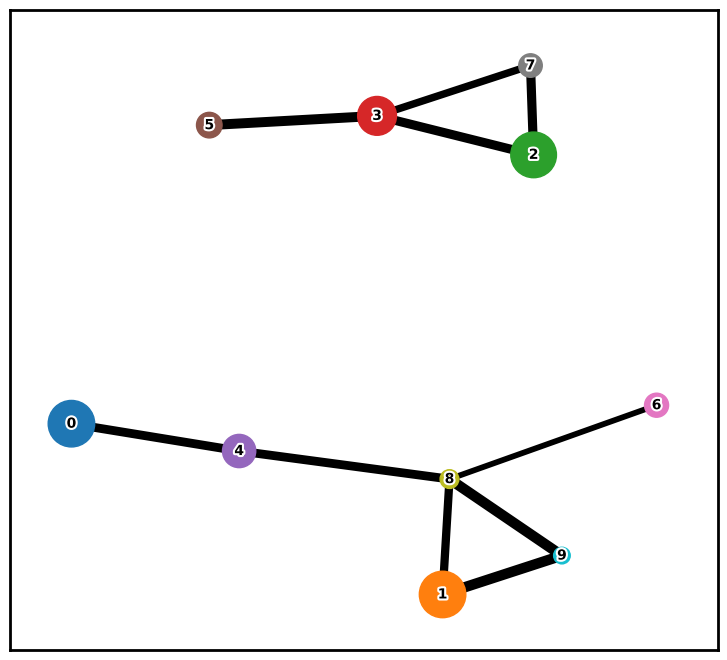

In [ ]:
sc.tl.paga(subclustering, groups='leiden')
sc.pl.paga(subclustering,threshold = 0.5, labels=None, fontsize = 10, fontoutline = 3,node_size_scale = 3,node_size_power = 1,random_state = 0)
sc.tl.umap(subclustering, min_dist = 0.001, spread = 1.5,init_pos = 'paga')

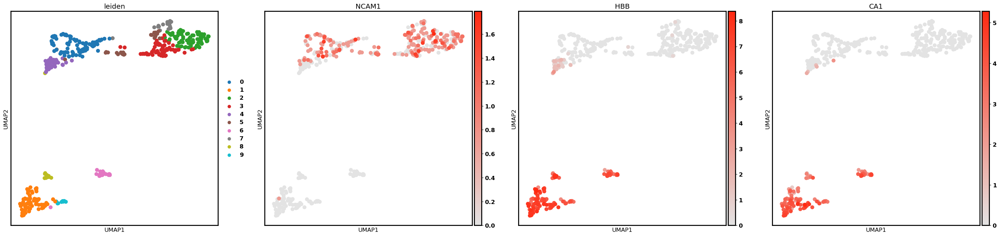

In [ ]:
sc.pl.umap(subclustering, color = ['leiden','NCAM1','HBB','CA1'],cmap = my_cmap)

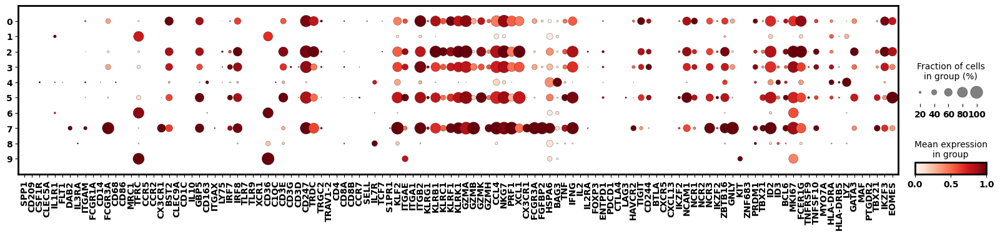

In [ ]:
plt.rcParams.update({'font.size': 12, 'font.weight': 'heavy','axes.linewidth':2})
#plt.rcParams.update(plt.rcParamsDefault)

gene_list = ['SPP1','CD209','CSF1R','CLEC5A','IL1R1','FLT1','DAB2','IL3RA','ITGAM','FCGR1A','CD14','FCGR3A','CD68','CD86','MRC1','TFRC','CCR5','CCR2','CX3CR1','BST2','CLEC9A','CD1C','IL10','GBP5','CD163','ITGAX','LY75','IRF7','IRF8','TLR7','TLR9','XCR1','CD36','C1QC','CD3E','CD3G','CD3D','CD247','TRDC','TRGC2','TRAV1-2','CD4','CD8A','CD8B','CCR7','SELL','IL7R','TCF7','S1PR1','KLF2',
                    'ITGAE','ITGA1','ITGB2','KLRG1','KLRB1','KLRC1','KLRF1','KLRK1','GZMA','GZMB','GZMK','GZMH','CCL4','NKG7','PRF1',
                         'XCL1','CX3CR1','FCGR3A','FGFBP2','HSPA6','BAG3','TNF','IFNG','IL2','IL2RA','FOXP3','ENTPD1','PDCD1','CTLA4','LAG3','HAVCR2','TIGIT',
             'CD244','BTLA','CXCR5','CXCL13','IKZF2','NCAM1','NCR1','NCR2','NCR3','IKZF2','ZBTB16',
             'GNLY','KIT','ZNF683','PRDM1','TBX21','ID2','ID3','BCL6','MKI67','FCER1G','TNFRSF9','TNFSF10','MYO7A','HLA-DRA','HLA-DRB5','LYZ','GATA3','MAF','PTGDR2','TBX21','IKZF3','EOMES']
sc.pl.dotplot(subclustering,gene_list,groupby = 'leiden' , vmax = 1, 
              swap_axes = False ,dot_min = 0.1,standard_scale = 'var',figsize = (20,3.5))

In [ ]:
subclustering.obs['cell type'] = subclustering.obs['leiden']
subclustering.obs['cell type'] = subclustering.obs['cell type'].astype('str')

Erthyroid = np.array([1,9,6,8,4])
Erthyroid = [str(i) for i in Erthyroid]


for c_id in set(subclustering.obs['leiden']):
    if c_id in Erthyroid:
        subclustering.obs = subclustering.obs.replace({'cell type' : { c_id: 'Erthyroid'}})
    else:
        subclustering.obs = subclustering.obs.replace({'cell type' : { c_id: 'NK'}})

subclustering.obs['cell type'] = subclustering.obs['cell type'].astype('category')

In [ ]:
subclustering.obs['T type'] = ''
subclustering.obs['T type'] = subclustering.obs['T type'].astype('category')

In [ ]:
subclustering.obs['Detailed Cell Type'] = subclustering.obs['T type'].astype(str).map(str) + ' ' +subclustering.obs['cell type'].astype(str).map(str)

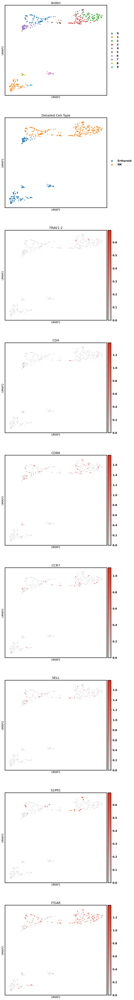

In [ ]:
sc.pl.umap(subclustering, color=['leiden','Detailed Cell Type','TRAV1-2','CD4','CD8A','CCR7','SELL','S1PR1','ITGAE'], ncols = 1, size = 60, cmap = my_cmap)

In [ ]:
subclustering.write('cluster10.h5ad')

In [ ]:
subclustering = sc.read_h5ad('cluster10.h5ad')

In [ ]:
df_10 = subclustering.obs[['cell type','T type','Detailed Cell Type']]

In [ ]:
df_10

,cell type,T type,Detailed Cell Type
AAAGTAGAGCTCAACT-1-3,NK,,NK
AACCGCGAGATGGCGT-1-3,NK,,NK
AACTCAGAGATCCTGT-1-3,NK,,NK
AACTGGTCAAACGTGG-1-3,NK,,NK
AAGCCGCTCAGGCGAA-1-3,NK,,NK
...,...,...,...
TTCTCCTGTTGGTGGA-1-5,Erthyroid,,Erthyroid
TTGACTTGTGTTCGAT-1-5,Erthyroid,,Erthyroid
TTGGAACCAGCTGTAT-1-5,Erthyroid,,Erthyroid
TTGTAGGAGGTGCACA-1-5,Erthyroid,,Erthyroid


### Cluster 7

In [ ]:
subclustering = adata[adata.obs['leiden'].isin(['7']),:]

In [ ]:
subclustering =subclustering[:,~np.isnan(subclustering.X.A).any(axis=0)]

In [ ]:
del subclustering.uns

In [ ]:
sc.pp.neighbors(subclustering, n_neighbors = 15, n_pcs = 50)
sc.tl.leiden(subclustering, resolution = 1, key_added= 'leiden')                                                 

In [ ]:
sc.tl.tsne(subclustering)

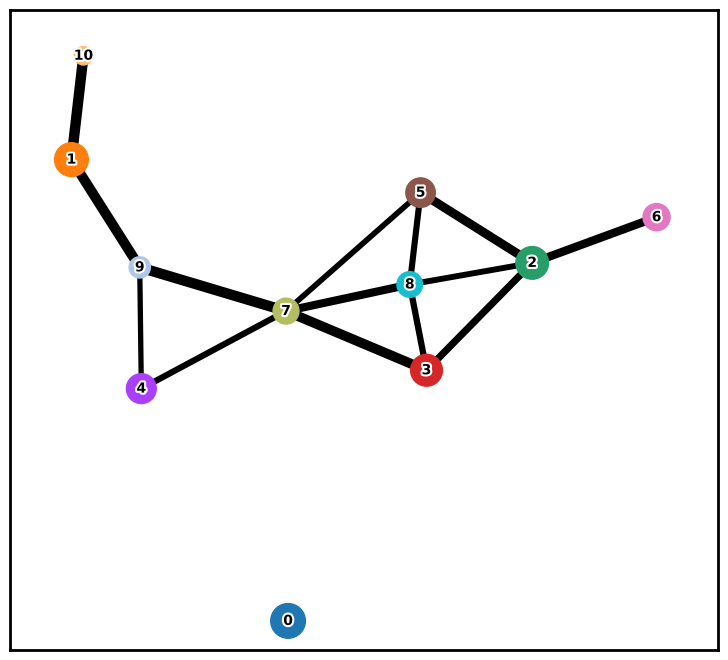

In [ ]:
sc.tl.paga(subclustering, groups='leiden')
sc.pl.paga(subclustering,threshold = 0.5, labels=None, fontsize = 10, fontoutline = 3,node_size_scale = 3,node_size_power = 1,random_state = 0)
sc.tl.umap(subclustering, min_dist = 0.001, spread = 1.5,init_pos = 'paga')

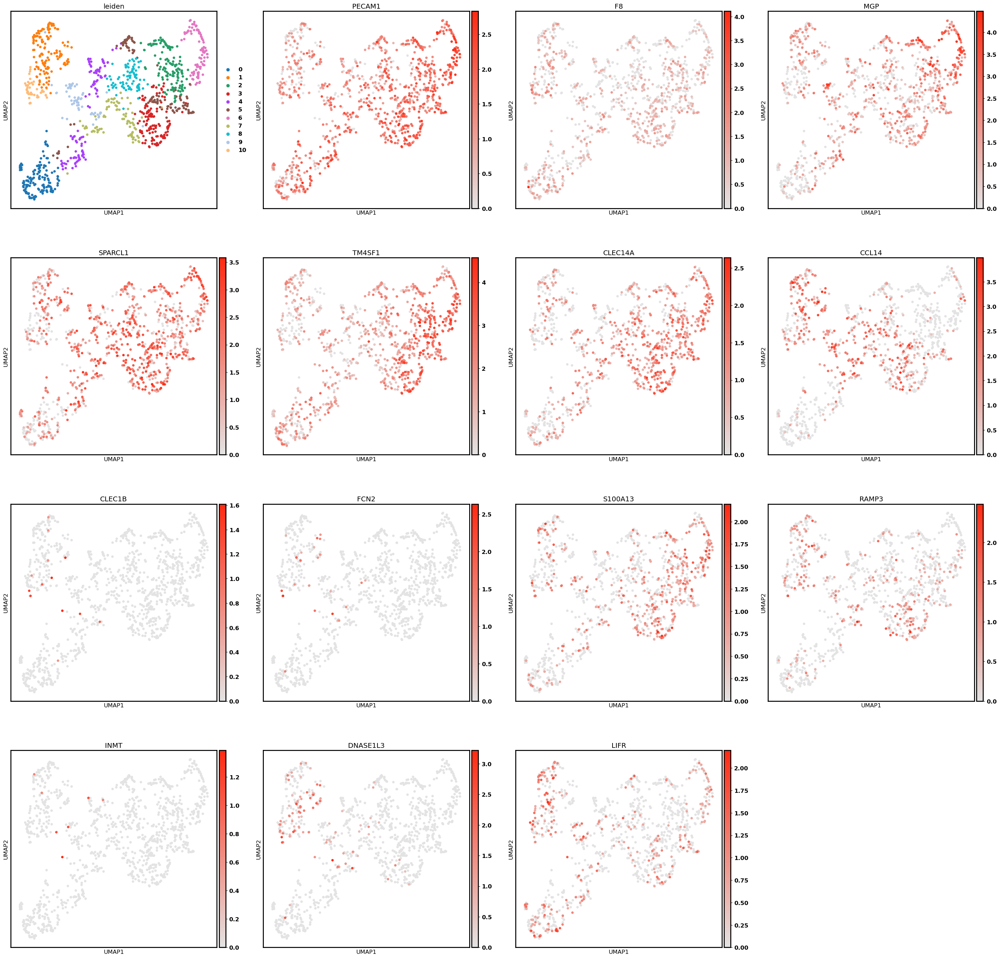

In [ ]:
sc.pl.umap(subclustering, color = ['leiden','PECAM1','F8','MGP','SPARCL1','TM4SF1','CLEC14A','CCL14','CLEC1B','FCN2','S100A13','RAMP3','INMT','DNASE1L3','LIFR'],cmap = my_cmap)

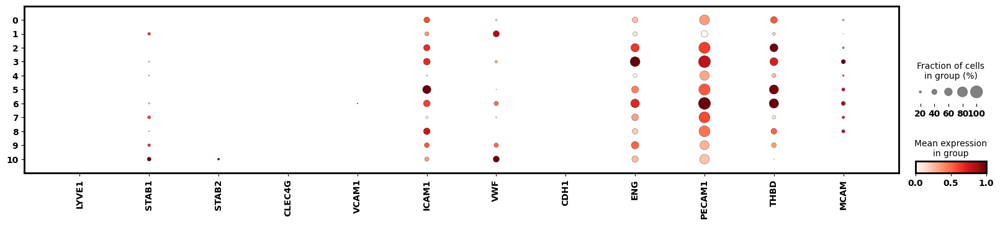

In [ ]:
plt.rcParams.update({'font.size': 12, 'font.weight': 'heavy','axes.linewidth':2})
#plt.rcParams.update(plt.rcParamsDefault)

gene_list = ['LYVE1', 'STAB1', 'STAB2', 'CLEC4G','VCAM1','ICAM1','VWF','CDH1','ENG','PECAM1','THBD','MCAM']
sc.pl.dotplot(subclustering,gene_list,groupby = 'leiden' , vmax = 1, 
              swap_axes = False ,dot_min = 0.1,standard_scale = 'var',figsize = (20,3.5))

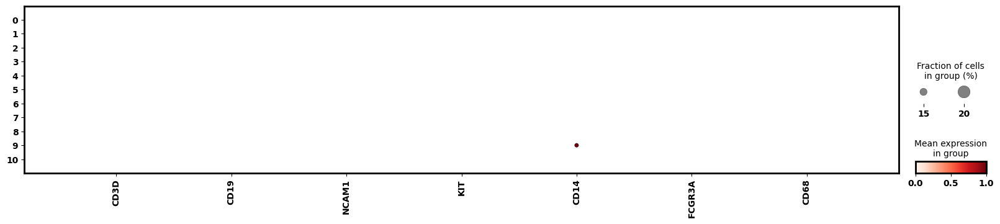

In [ ]:
plt.rcParams.update({'font.size': 12, 'font.weight': 'heavy','axes.linewidth':2})
#plt.rcParams.update(plt.rcParamsDefault)

gene_list = ['CD3D','CD19','NCAM1','KIT','CD14','FCGR3A','CD68']
sc.pl.dotplot(subclustering,gene_list,groupby = 'leiden' , vmax = 1, 
              swap_axes = False ,dot_min = 0.1,standard_scale = 'var',figsize = (20,3.5))

In [ ]:
subclustering.obs['cell type'] = subclustering.obs['leiden']
subclustering.obs['cell type'] = subclustering.obs['cell type'].astype('str')

PEC = np.array([1,9,10])
PEC = [str(i) for i in PEC]

LSEC1 = ['2','0','6','4']

for c_id in set(subclustering.obs['leiden']):
    if c_id in PEC:
        subclustering.obs = subclustering.obs.replace({'cell type' : { c_id: 'PEC'}})
    if c_id in LSEC1:
        subclustering.obs = subclustering.obs.replace({'cell type' : { c_id: 'LSEC1'}})
    else:
        subclustering.obs = subclustering.obs.replace({'cell type' : { c_id: 'LSEC2'}})

subclustering.obs['cell type'] = subclustering.obs['cell type'].astype('category')

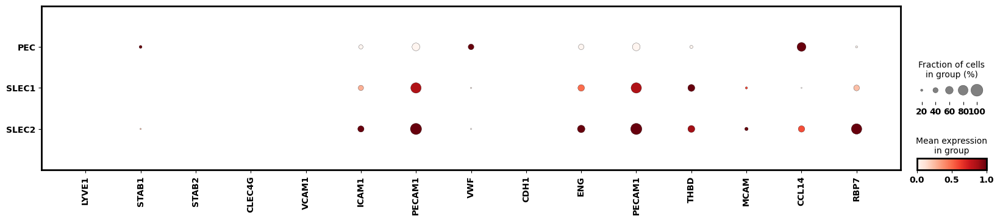

In [ ]:
plt.rcParams.update({'font.size': 12, 'font.weight': 'heavy','axes.linewidth':2})
#plt.rcParams.update(plt.rcParamsDefault)

gene_list = ['LYVE1', 'STAB1', 'STAB2', 'CLEC4G','VCAM1','ICAM1','PECAM1','VWF','CDH1','ENG','PECAM1','THBD','MCAM','CCL14','RBP7']
sc.pl.dotplot(subclustering,gene_list,groupby = 'cell type' , vmax = 1, 
              swap_axes = False ,dot_min = 0.1,standard_scale = 'var',figsize = (20,3.5))

In [ ]:
subclustering.obs['T type'] = ''
subclustering.obs['T type'] = subclustering.obs['T type'].astype('category')

In [ ]:
subclustering.obs['Detailed Cell Type'] = subclustering.obs['T type'].astype(str).map(str) + ' ' +subclustering.obs['cell type'].astype(str).map(str)

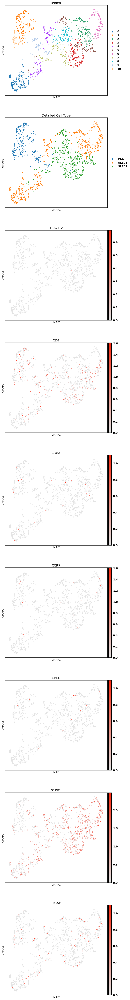

In [ ]:
sc.pl.umap(subclustering, color=['leiden','Detailed Cell Type','TRAV1-2','CD4','CD8A','CCR7','SELL','S1PR1','ITGAE'], ncols = 1, size = 60, cmap = my_cmap)

In [ ]:
subclustering.write('cluster7.h5ad')

In [ ]:
subclustering = sc.read_h5ad('cluster7.h5ad')

In [ ]:
df_7 = subclustering.obs[['cell type','T type','Detailed Cell Type']]

In [ ]:
df_7

,cell type,T type,Detailed Cell Type
AAACCTGCACATCCAA-1-3,PEC,,PEC
AACGTTGAGTACATGA-1-3,PEC,,PEC
AAGGTTCGTTCGCTAA-1-3,PEC,,PEC
AAGTCTGTCACATAGC-1-3,PEC,,PEC
ACATCAGAGGGTGTTG-1-3,PEC,,PEC
...,...,...,...
TTTGCGCAGCTAAGAT-1-5,PEC,,PEC
TTTGCGCTCAGCTCGG-1-5,SLEC1,,SLEC1
TTTGGTTTCTCGTTTA-1-5,SLEC1,,SLEC1
TTTGTCAGTCGCGGTT-1-5,SLEC1,,SLEC1


### Cluster 11

In [ ]:
subclustering = adata[adata.obs['leiden'].isin(['11']),:]

In [ ]:
subclustering =subclustering[:,~np.isnan(subclustering.X.A).any(axis=0)]

In [ ]:
del subclustering.uns

In [ ]:
sc.pp.neighbors(subclustering, n_neighbors = 15, n_pcs = 50)
sc.tl.leiden(subclustering, resolution = 1, key_added= 'leiden')                                                 

In [ ]:
sc.tl.tsne(subclustering)

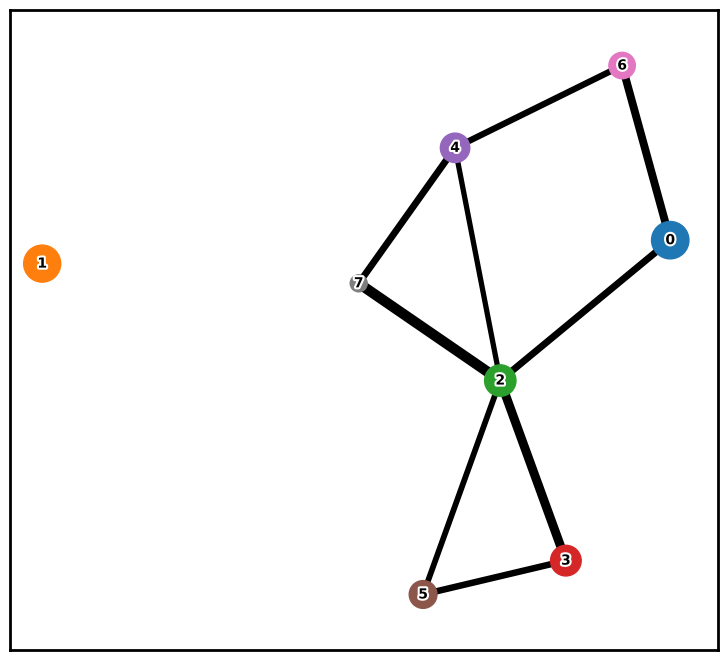

In [ ]:
sc.tl.paga(subclustering, groups='leiden')
sc.pl.paga(subclustering,threshold = 0.5, labels=None, fontsize = 10, fontoutline = 3,node_size_scale = 3,node_size_power = 1,random_state = 0)
sc.tl.umap(subclustering, min_dist = 0.001, spread = 1.5,init_pos = 'paga')

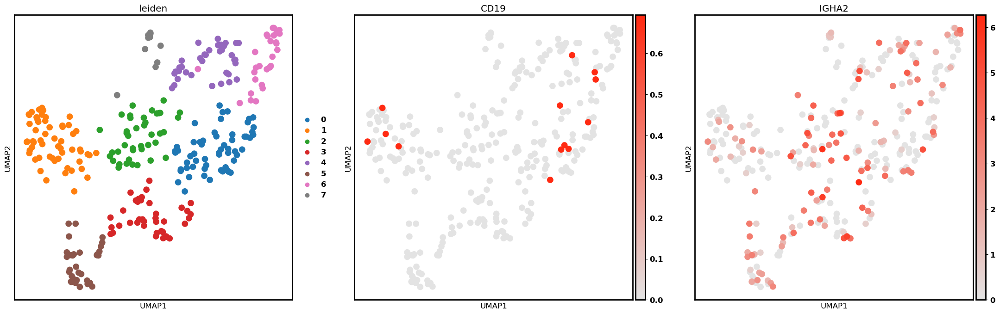

In [ ]:
sc.pl.umap(subclustering, color = ['leiden','CD19','IGHA2'],cmap = my_cmap)

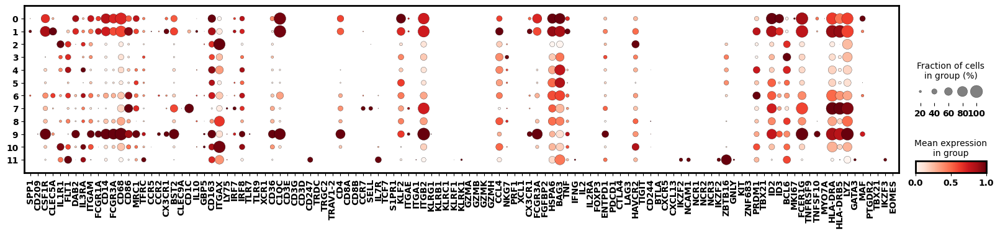

In [ ]:
plt.rcParams.update({'font.size': 12, 'font.weight': 'heavy','axes.linewidth':2})
#plt.rcParams.update(plt.rcParamsDefault)

gene_list = ['SPP1','CD209','CSF1R','CLEC5A','IL1R1','FLT1','DAB2','IL3RA','ITGAM','FCGR1A','CD14','FCGR3A','CD68','CD86','MRC1','TFRC','CCR5','CCR2','CX3CR1','BST2','CLEC9A','CD1C','IL10','GBP5','CD163','ITGAX','LY75','IRF7','IRF8','TLR7','TLR9','XCR1','CD36','C1QC','CD3E','CD3G','CD3D','CD247','TRDC','TRGC2','TRAV1-2','CD4','CD8A','CD8B','CCR7','SELL','IL7R','TCF7','S1PR1','KLF2',
                    'ITGAE','ITGA1','ITGB2','KLRG1','KLRB1','KLRC1','KLRF1','KLRK1','GZMA','GZMB','GZMK','GZMH','CCL4','NKG7','PRF1',
                         'XCL1','CX3CR1','FCGR3A','FGFBP2','HSPA6','BAG3','TNF','IFNG','IL2','IL2RA','FOXP3','ENTPD1','PDCD1','CTLA4','LAG3','HAVCR2','TIGIT',
             'CD244','BTLA','CXCR5','CXCL13','IKZF2','NCAM1','NCR1','NCR2','NCR3','IKZF2','ZBTB16',
             'GNLY','KIT','ZNF683','PRDM1','TBX21','ID2','ID3','BCL6','MKI67','FCER1G','TNFRSF9','TNFSF10','MYO7A','HLA-DRA','HLA-DRB5','LYZ','GATA3','MAF','PTGDR2','TBX21','IKZF3','EOMES']
sc.pl.dotplot(subclustering,gene_list,groupby = 'leiden' , vmax = 1, 
              swap_axes = False ,dot_min = 0.1,standard_scale = 'var',figsize = (20,3.5))

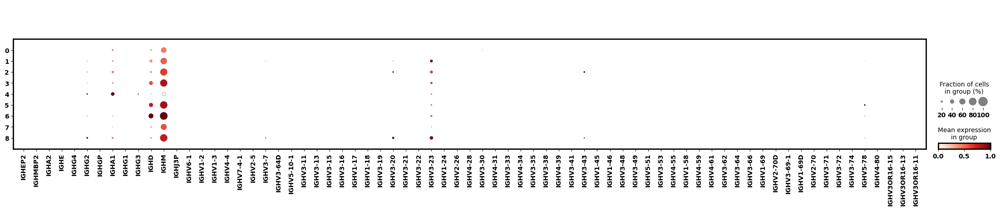

In [ ]:
# plt.rcParams.update({'font.size': 15, 'font.weight': 'heavy','axes.linewidth':2})
#plt.rcParams.update(plt.rcParamsDefault)
gamma_genesmask = [gene.startswith("IGH") for gene in subclustering.var_names]
gamma_genes = subclustering.var_names[gamma_genesmask]

sc.pl.dotplot(subclustering,gamma_genes,groupby = 'leiden' , vmax = 1, swap_axes = False, dot_min =0.1, dot_max =1,standard_scale = 'var')

In [ ]:
subclustering.obs['cell type'] = subclustering.obs['leiden']
subclustering.obs['cell type'] = subclustering.obs['cell type'].astype('str')

IgAp = ['4'] 


for c_id in set(subclustering.obs['leiden']):
    if c_id in IgAp:
        subclustering.obs = subclustering.obs.replace({'cell type' : { c_id: 'IgA Plasma'}})
    else:
        subclustering.obs = subclustering.obs.replace({'cell type' : { c_id: 'Naive B'}})

subclustering.obs['cell type'] = subclustering.obs['cell type'].astype('category')

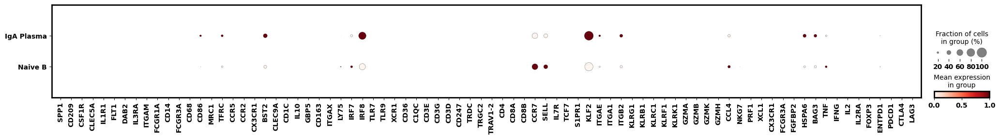

In [ ]:
# plt.rcParams.update({'font.size': 12, 'font.weight': 'heavy','axes.linewidth':2})
#plt.rcParams.update(plt.rcParamsDefault)

gene_list = ['SPP1','CD209','CSF1R','CLEC5A','IL1R1','FLT1','DAB2','IL3RA','ITGAM','FCGR1A','CD14','FCGR3A','CD68','CD86','MRC1','TFRC','CCR5','CCR2','CX3CR1','BST2','CLEC9A','CD1C','IL10','GBP5','CD163','ITGAX','LY75','IRF7','IRF8','TLR7','TLR9','XCR1','CD36','C1QC','CD3E','CD3G','CD3D','CD247','TRDC','TRGC2','TRAV1-2','CD4','CD8A','CD8B','CCR7','SELL','IL7R','TCF7','S1PR1','KLF2',
                    'ITGAE','ITGA1','ITGB2','KLRG1','KLRB1','KLRC1','KLRF1','KLRK1','GZMA','GZMB','GZMK','GZMH','CCL4','NKG7','PRF1',
                         'XCL1','CX3CR1','FCGR3A','FGFBP2','HSPA6','BAG3','TNF','IFNG','IL2','IL2RA','FOXP3','ENTPD1','PDCD1','CTLA4','LAG3']
sc.pl.dotplot(subclustering,gene_list,groupby = 'cell type' , vmax = 1, 
              swap_axes = False ,dot_min = 0.1,standard_scale = 'var',figsize = (25,2.5))

In [ ]:
subclustering.obs['T type'] = ''
subclustering.obs['T type'] = subclustering.obs['T type'].astype('category')

In [ ]:
subclustering.obs['Detailed Cell Type'] = subclustering.obs['T type'].astype(str).map(str) + ' ' +subclustering.obs['cell type'].astype(str).map(str)

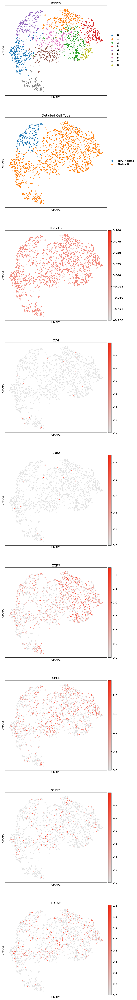

In [ ]:
sc.pl.umap(subclustering, color=['leiden','Detailed Cell Type','TRAV1-2','CD4','CD8A','CCR7','SELL','S1PR1','ITGAE'], ncols = 1, size = 60, cmap = my_cmap)

In [ ]:
subclustering.write('cluster5.h5ad')

### Finalize the annotation

In [ ]:
merge_df2 = pd.concat([df_0,df_1,df_2,df_3,df_4,df_5,df_7,df_9,df_10])

In [ ]:
merge_df1 = adata.obs

In [ ]:
merged_df = merge_df1.merge(merge_df2, left_index=True, right_index=True, how='left', suffixes=('', ''))

In [ ]:
for i in ['cell type', 'T type', 'Detailed Cell Type']:
    merged_df[i] = merged_df[i].astype(str)

In [ ]:
merged_df

,n_counts,log_counts,n_genes,log10GenesPerUMI,mt_frac,ribo_frac,batch,S_score,G2M_score,S_G2M_diff,phase,leiden,leiden2,leiden3,cell type,T type,Detailed Cell Type
AAACCTGAGAGACTTA-1-3,NaN,8.965335,3033,0.894293,NaN,NaN,3,0.323142,0.224294,0.098848,S,2,2,2,DNT,TCRab,TCRab DNT
AAACCTGAGAGTAATC-1-3,NaN,9.296427,3104,0.876545,NaN,NaN,3,0.176376,0.056112,0.120264,S,0,"0,0","0,0,2",NK,,NK
AAACCTGAGCGATATA-1-3,NaN,8.931024,2379,0.870545,NaN,NaN,3,-0.084942,-0.077649,-0.007293,G1,1,1,1,M1-like CD16+ Macrophage,,M1-like CD16+ Macrophage
AAACCTGAGCGGCTTC-1-3,NaN,8.323608,1450,0.874539,NaN,NaN,3,-0.082840,-0.064996,-0.017844,G1,2,2,2,MAIT,TCRab CD8,TCRab CD8 MAIT
AAACCTGAGGAACTGC-1-3,NaN,9.100079,2869,0.876692,NaN,NaN,3,-0.096672,-0.046460,-0.050212,G1,3,3,3,M2-like CD16+ Macrophage,,M2-like CD16+ Macrophage
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
TTTGTCAGTTCCCGAG-1-5,NaN,8.273336,1815,0.906991,NaN,NaN,5,-0.087702,-0.083728,-0.003974,G1,8,8,8,nan,nan,nan
TTTGTCATCCTACAGA-1-5,NaN,8.313852,1845,0.904543,NaN,NaN,5,-0.092803,-0.074307,-0.018496,G1,0,"0,4","0,4",TEM,TCRab CD8,TCRab CD8 TEM
TTTGTCATCGAATGCT-1-5,NaN,7.908020,1485,0.923514,NaN,NaN,5,-0.025840,-0.045015,0.019174,G1,7,7,7,SLEC1,,SLEC1
TTTGTCATCGCCGTGA-1-5,NaN,7.357556,870,0.919154,NaN,NaN,5,-0.060678,0.082432,-0.143110,G2M,0,"0,2","0,2",TEM,TCRab CD8,TCRab CD8 TEM


In [ ]:
merged_df['cell type'][merged_df['leiden3'] == '6']= 'NK'
merged_df['T type'][merged_df['leiden3'] == '6'] = ''
merged_df['Detailed Cell Type'][merged_df['leiden3'] == '6'] = 'NK'

In [ ]:
merged_df['cell type'][merged_df['leiden3'] == '11'] = 'Plasma'
merged_df['T type'][merged_df['leiden3'] == '11'] = ''
merged_df['Detailed Cell Type'][merged_df['leiden3'] == '11'] = 'Plasma'

In [ ]:
merged_df['cell type'][merged_df['leiden3'] == '8']= 'Stellate Cells'
merged_df['T type'][merged_df['leiden3'] == '8'] = ''
merged_df['Detailed Cell Type'][merged_df['leiden3'] == '8'] = 'Stellate Cells'

In [ ]:
merged_df['cell type'][merged_df['leiden3'] == '12'] = 'IgM Naive B'
merged_df['T type'][merged_df['leiden3'] == '12'] = ''
merged_df['Detailed Cell Type'][merged_df['leiden3'] == '12'] = 'IgM Naive B'

In [ ]:
merged_df['cell type'][merged_df['leiden3'] == '13']= 'KIT+ ILC3'
merged_df['T type'][merged_df['leiden3'] == '13'] = ''
merged_df['Detailed Cell Type'][merged_df['leiden3'] == '13'] = 'KIT+ ILC3'

In [ ]:
merged_df['cell type'][merged_df['leiden3'] == '14'] = 'Glial-like Cells'
merged_df['T type'][merged_df['leiden3'] == '14'] = ''
merged_df['Detailed Cell Type'][merged_df['leiden3'] == '14'] = 'Glial-like Cells'

In [ ]:
merged_df['cell type'][merged_df['leiden3'] == '15'] = 'M2-like CD16- Macrophage'
merged_df['T type'][merged_df['leiden3'] == '15'] = ''
merged_df['Detailed Cell Type'][merged_df['leiden3'] == '15'] = 'M2-like CD16- Macrophage'

## Further update the annotation

In [ ]:
adata.obs['Detailed Cell Type'] = adata.obs['Detailed Cell Type'].replace({' Plasma':'Mmeory B',
                                                                           ' LSEC1':'Liver Sinusoidal Endothelial Cells zone 1',
                                                                           ' LSEC2':'Liver Sinusoidal Endothelial Cells zone 2',
                                                                          ' ILCreg': 'Regulatory ILC',
                                                                          ' IgD IgM Naive B': 'Naive B Cells', 
                                                                           ' IgM Naive B': 'Naive B Cells',
                                                                          'Mmeory B':'Mmeory B Cells',
                                                                          ' PEC':'Portal Endothelial Cells',
                                                                           'Plasma':'Plasma Cells'
                                                                          })

In [ ]:
adata.obs['Detailed Cell Type'] = [' '.join(i.split(' ')[1:]) if i.startswith(' ') else i for i in adata.obs['Detailed Cell Type']]

In [ ]:
adata.obs['Detailed Cell Type'] = adata.obs['Detailed Cell Type'].astype('category')

In [ ]:
adata.write('liver_processed.h5ad')

In [16]:
adata.obs['celltype_lowres'] = adata.obs['cell type']
adata.obs['celltype_highres'] = adata.obs['Detailed Cell Type']

In [ ]:
sc.pl.dotplot(adata, var_names=['CD3D','CD3E','CD3G','CD274','TRDC','CD19'],groupby= 'celltype_highres')

In [ ]:
adata.obs.groupby('celltype_highres')['celltype_lowres'].apply(set)

In [ ]:
adata.obs['celltype_lowres'] = adata.obs['celltype_lowres'].astype(str)
adata.obs['celltype_lowres'][adata.obs['celltype_highres'] == 'CD16- Macrophage'] = 'Macrophages'
adata.obs['celltype_lowres'][adata.obs['celltype_highres'] == 'Hepatocytes Type 6'] = 'Hepatocytes'
adata.obs['celltype_lowres'][adata.obs['celltype_highres'] == 'ILC1-like Cells'] = 'ILC'
adata.obs['celltype_lowres'][adata.obs['celltype_highres'] == 'KIT- ILC3-like Cells'] = 'ILC'
adata.obs['celltype_lowres'][adata.obs['celltype_highres'] == 'Liver Sinusoidal Endothelial Cells zone 1'] = 'LSEC'
adata.obs['celltype_lowres'][adata.obs['celltype_highres'] == 'Liver Sinusoidal Endothelial Cells zone 2'] = 'LSEC'
adata.obs['celltype_lowres'][adata.obs['celltype_highres'] == 'M1-like CD16+ Macrophage'] = 'Macrophages'
adata.obs['celltype_lowres'][adata.obs['celltype_highres'] == 'M2-like CD16+ Macrophage'] = 'Macrophages'
adata.obs['celltype_lowres'][adata.obs['celltype_highres'] == 'M2-like CD16- Macrophage'] = 'Macrophages'
adata.obs['celltype_lowres'][adata.obs['celltype_highres'] == 'pDC'] = 'Dendritic Cells'
adata.obs['celltype_lowres'][adata.obs['celltype_highres'] == 'Immature DC'] = 'Dendritic Cells'
adata.obs['celltype_lowres'][adata.obs['celltype_highres'] == 'KIT+ ILC3'] = 'ILC'
adata.obs['celltype_lowres'][adata.obs['celltype_highres'] == 'Regulatory ILC'] = 'ILC'
adata.obs['celltype_lowres'][adata.obs['celltype_highres'] == 'Naive B Cells'] = 'B Cells'
t_id = [i.startswith('TCR') for i in list(set(adata.obs['celltype_highres']))]
t_names = np.array(list(set(adata.obs['celltype_highres'])))[t_id]
adata.obs['celltype_lowres'][adata.obs['celltype_highres'].isin(t_names)] = 'T Cells'
adata.obs['celltype_lowres'][adata.obs['celltype_highres'] == 'Mmeory B Cells'] = 'B Cells'
adata.obs['celltype_lowres'][adata.obs['celltype_highres'] == 'IgM Naive B'] = 'B Cells'
adata.obs['celltype_lowres'][adata.obs['celltype_highres'] == 'Plasma Cells'] = 'Plasma Cells'

In [40]:
adata.obs['celltype_highres'] = adata.obs['celltype_highres'].replace('Mmeory B Cells','Memory B Cells')

In [41]:
adata.write('liver_annotated.h5ad')

### Asked to further look into mait cells

In [ ]:
plt.rcParams['figure.figsize'] = [8,8]
sc.tl.leiden(adata, restrict_to = ('celltype_highres', ['TCRab CD8 effector']), resolution = 1, key_added= 'celltype_highres_forMAIT')
adataT = adata[adata.obs['celltype_lowres'] == 'T Cells']
sc.pl.umap(adataT, color=['celltype_highres_forMAIT'], size = 20, cmap = my_cmap)
sc.pl.umap(adataT, color=['TRAV1-2','CD4'], size = 20, cmap = my_cmap)
#go back to the DE section to make sure this subcluster make sense

In [19]:
adata.obs['celltype_highres'] = adata.obs['celltype_highres'].astype(str)
adata.obs['celltype_highres'][adata.obs['celltype_highres_forMAIT']=='TCRab CD8 effector,0'] = 'TCRab CD8ab MAIT'
adata.obs['celltype_highres'][adata.obs['celltype_highres']=='TCRab CD8 MAIT'] = 'TCRab CD8aa MAIT'

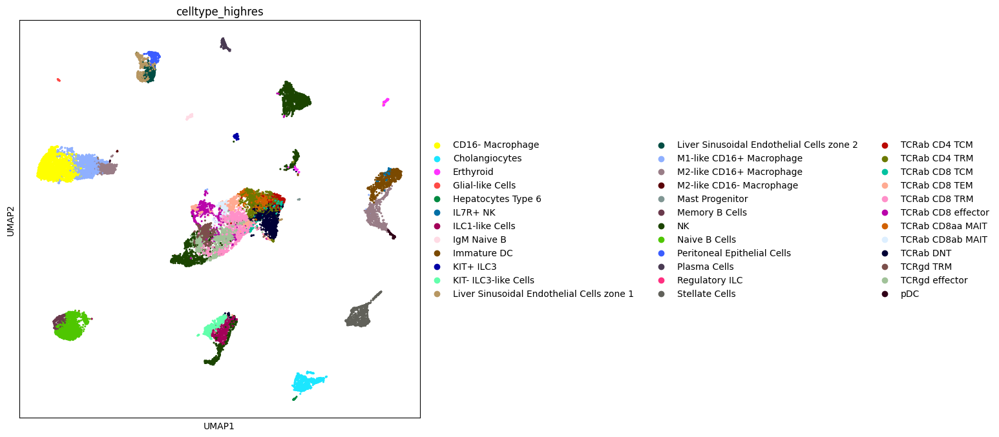

In [21]:
plt.rcParams['figure.figsize'] = [8,8]
sc.pl.umap(adata, color=['celltype_highres'], size = 20, cmap = my_cmap)

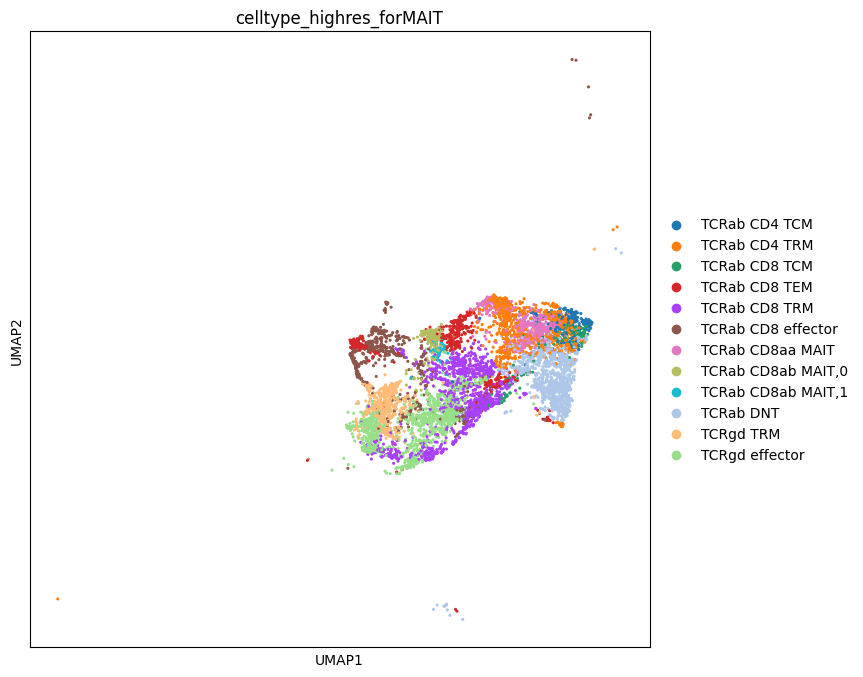

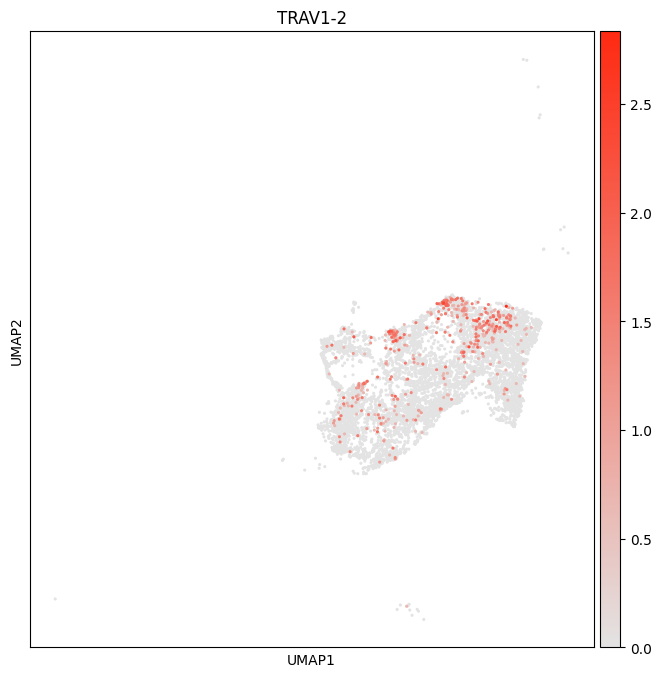

In [29]:
plt.rcParams['figure.figsize'] = [8,8]
sc.tl.leiden(adata, restrict_to = ('celltype_highres', ['TCRab CD8ab MAIT']), resolution = 0.3, key_added= 'celltype_highres_forMAIT')
adataT = adata[adata.obs['celltype_lowres'] == 'T Cells']
sc.pl.umap(adataT, color=['celltype_highres_forMAIT'], size = 20, cmap = my_cmap)
sc.pl.umap(adataT, color=['TRAV1-2'], size = 20, cmap = my_cmap)
#go back to the DE section to make sure this subcluster make sense

In [30]:
adata.obs['celltype_highres'] = adata.obs['celltype_highres'].astype(str)
adata.obs['celltype_highres'][adata.obs['celltype_highres_forMAIT']=='TCRab CD8ab MAIT,1'] = 'TCRab CD8 effector'

In [31]:
del adata.obs['celltype_highres_forMAIT']

In [32]:
adata.write('liver_annotated.h5ad')

Historical notebook provenance. Renamed from liver_process.ipynb during repository organization. Original scientific code cells, execution counts, and saved outputs are preserved. Personal drive paths and non-linear execution history remain historical; the active revision workflow and verified inputs are documented in the root README. Saved output does not imply that a fresh top-to-bottom execution has been validated.
